# HIV model fitting and identifiability analysis in log-parameter coordinates

$$\dot T=\lambda-dT-kVT,\qquad \dot I=kVT-\delta I,\qquad \dot V=pI-cV,$$

with observable $h(x)=\log_{10}(2V\times10^3)$ and physical parameters

$$\theta=(\lambda,d,k,\delta,p,c).$$

The parameter $c$ is fixed at $c=3.0$. The remaining five positive parameters are fitted and analyzed in the log-coordinate vector $\eta=\log(\lambda,d,k,\delta,p)$. First- and second-order physical sensitivities are retained only as internal chain-rule intermediates; every reported identifiability diagnostic uses the free-parameter derivatives $Z_\eta=\partial h/\partial\eta$ and $H_\eta=\partial^2h/\partial\eta^2$.

In [1]:
import numpy as np
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq, least_squares
from scipy.special import erfc, gammaincinv
from scipy.stats import norm
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=False, linewidth=120)

PARAM_TEX = [r'$\lambda$', '$d$', '$k$', r'$\delta$', r'$\pi$', '$c$']
PARAM_TXT = ['lambda', 'd', 'k', 'delta', 'p', 'c']
N_STATE, N_THETA = 3, 6
FIXED_PARAMETER_VALUES = {'c': 3.0}
FIXED_PARAM_IDX = np.asarray(
    [PARAM_TXT.index(name) for name in FIXED_PARAMETER_VALUES],
    dtype=int)
FREE_PARAM_IDX = np.asarray(
    [j for j in range(N_THETA) if j not in FIXED_PARAM_IDX],
    dtype=int)
FREE_PARAM_TEX = [PARAM_TEX[j] for j in FREE_PARAM_IDX]
FREE_PARAM_TXT = [PARAM_TXT[j] for j in FREE_PARAM_IDX]
FREE_LOG_PARAM_TXT = [f'log({name})' for name in FREE_PARAM_TXT]
LOG_PARAM_TEX = [
    r'$\log\lambda$', r'$\log d$', r'$\log k$',
    r'$\log\delta$', r'$\log p$', r'$\log c$']
FREE_LOG_PARAM_TEX = [LOG_PARAM_TEX[j] for j in FREE_PARAM_IDX]
N_FREE = FREE_PARAM_IDX.size

## 1. HIV model derivatives used as chain-rule intermediates

`hiv_eq` is the dimensional RHS. `get_hiv_derivatives` returns

$$f,\qquad J_x=\frac{\partial f}{\partial x},\qquad
J_\theta=\frac{\partial f}{\partial\theta},$$

for the six original parameters $\theta=(\lambda,d,k,\delta,p,c)$.

In [2]:
def hiv_eq(t, x, theta):
    lam, d, k, delta, p, c = theta
    T, I, V = x
    return np.array([lam - d*T - k*V*T,    # dT/dt
                     k*V*T - delta*I,      # dI/dt
                     p*I - c*V])           # dV/dt


def get_hiv_derivatives(x, theta):
    """f, Jx (3x3 = df/dx), Jtheta (3x6 = df/dtheta)."""
    lam, d, k, delta, p, c = theta
    T, I, V = x
    f = hiv_eq(0.0, x, theta)

    Jx = np.array([[-d - k*V, 0.0,    -k*T],
                   [ k*V,     -delta,  k*T],
                   [ 0.0,      p,     -c]])

    # columns: lambda, d, k, delta, p, c
    Jtheta = np.array([[1.0, -T, -V*T,  0.0, 0.0,  0.0],
                       [0.0,  0.0, V*T, -I,  0.0,  0.0],
                       [0.0,  0.0, 0.0,  0.0, I,  -V]])
    return f, Jx, Jtheta

## 2. Physical sensitivity ODE used internally for log derivatives

Augment the state with

$$Y^x_\theta=\frac{\partial x}{\partial\theta}.$$

Because the initial state is fixed and parameter-independent, $Y^x_\theta(0)=0$, and

$$\dot x=f,\qquad
\dot Y^x_\theta=J_xY^x_\theta+J_\theta.$$

In [3]:
def hiv_ode_sens(t, S, theta, n=N_STATE, k_dim=N_THETA):
    x = S[:n]
    Y = S[n:n + n*k_dim].reshape(n, k_dim)
    f, Jx, Jtheta = get_hiv_derivatives(x, theta)
    dYdt = Jx @ Y + Jtheta
    return np.concatenate([f, dYdt.ravel()])

## 3. Load data and fit parameters

Patient-3 viral titers (RNA copies/ml) are used both to estimate the model parameter vector $\widehat\theta$ and as the observed data for all subsequent uncertainty analyses. After sorting by time, the code uses all observations (`[0:]`), shifts time by 36 days, and scales titers by $10^3$. The residual is $\log_{10}(2\cdot10^3V_{\mathrm{model}})-\log_{10}V_{\mathrm{patient}}$.

The parameter $c$ is fixed at `FIXED_PARAMETER_VALUES['c'] = 3.0`. The optimizer works in the five-dimensional log-coordinate vector $\eta=\log(\lambda,d,k,\delta,p)$ for positivity and numerical stability, then inserts the fixed $c$ value when constructing the complete physical parameter vector for the ODE. Edit `PARAMETER_RANGES` below in physical units; only free-parameter bounds are passed to the optimizer. Every identifiability diagnostic and profile calculation uses the five free log coordinates.

The fitting algorithm uses three stages: deterministic multi-start coarse search, smaller-step finite-difference refinement, and sensitivity-Jacobian refinement. The three best distinct candidates are checked using bounded KKT projected gradients, positive definiteness of the reduced loss Hessian, and feasible neighboring probes. Failed candidates trigger limited negative-curvature or projected-gradient continuation. A point is labeled as a verified local minimum only when every acceptance test passes; the result is stored in `fit_local_minimum_verified` and `local_minimum_check`.

In [4]:
def observable_hiv(theta, tspan, y0):
    """Evaluate h(t, theta)=log10(2*1e3*V) at tspan."""
    t_eval = np.concatenate([[0.0], tspan])
    sol = solve_ivp(
        lambda t, x: hiv_eq(t, x, theta),
        [0.0, t_eval[-1]], y0, t_eval=t_eval,
        rtol=1e-10, atol=1e-12, method='DOP853')
    if (not sol.success) or sol.y.shape[1] != t_eval.size:
        raise RuntimeError(
            f'HIV state integration failed: {sol.message}')
    V = np.maximum(sol.y[2, 1:], 1e-30)
    return np.log10(2.0 * V * 1e3)


def objective_hiv(theta, tspan, y0, xexp):
    try:
        return observable_hiv(theta, tspan, y0) - np.log10(xexp)
    except RuntimeError:
        return np.full(xexp.shape, 1e6, dtype=float)


theta0 = np.array([0.85, 0.085, 0.00084, 0.01, 850.0, 3.0])
for fixed_name, fixed_value in FIXED_PARAMETER_VALUES.items():
    theta0[PARAM_TXT.index(fixed_name)] = float(fixed_value)
y0 = np.array([10.0, 0.0, 1e-6])
# sel_days = [15, 29, 57]
raw = np.loadtxt('HIV_patient8.txt', skiprows=1)
data = raw[np.argsort(raw[:, 0])][0:]
tspan = data[:, 0] + 40.0
xexp_fitting = data[:, 1] * 1e3
print('observations used for fitting (day, titer):\n', data)

# Editable bounds in the original physical parameter coordinates.
# Change these values only; optimizer bounds are generated in log scale.
PARAMETER_RANGES = {
    'lambda': (1e-16, 1e6),
    'd':      (1e-16, 1e4),
    'k':      (1e-20, 1e2),
    'delta':  (1e-16, 1e4),
    'p':      (1e-16, 1e12),
    'c':      (1e-16, 1e4),
}

if set(PARAMETER_RANGES) != set(PARAM_TXT):
    missing = set(PARAM_TXT) - set(PARAMETER_RANGES)
    extra = set(PARAMETER_RANGES) - set(PARAM_TXT)
    raise ValueError(
        f'PARAMETER_RANGES keys mismatch; missing={missing}, extra={extra}')
theta_bounds = np.asarray(
    [PARAMETER_RANGES[name] for name in PARAM_TXT], dtype=float)
theta_lb = theta_bounds[:, 0]
theta_ub = theta_bounds[:, 1]
if (np.any(~np.isfinite(theta_bounds)) or np.any(theta_lb <= 0.0)
        or np.any(theta_ub <= theta_lb)):
    raise ValueError(
        'Every physical parameter range must satisfy '
        '0 < lower < upper < infinity')
if np.any(theta0 <= theta_lb) or np.any(theta0 >= theta_ub):
    invalid = [
        PARAM_TXT[j] for j in range(N_THETA)
        if not theta_lb[j] < theta0[j] < theta_ub[j]]
    raise ValueError(
        f'Initial values must lie strictly inside their ranges: {invalid}')

eta0 = np.log(theta0[FREE_PARAM_IDX])
eta_lb = np.log(theta_lb[FREE_PARAM_IDX])
eta_ub = np.log(theta_ub[FREE_PARAM_IDX])
print('editable physical parameter ranges:')
for name, lower, upper in zip(PARAM_TXT, theta_lb, theta_ub):
    print(f'  {name:>7s}: [{lower:.3e}, {upper:.3e}]')

def theta_from_free_log(eta_free):
    eta_free = np.asarray(eta_free, dtype=float)
    if eta_free.shape != (N_FREE,):
        raise ValueError(f'eta_free must have shape ({N_FREE},)')
    theta = theta0.copy()
    theta[FREE_PARAM_IDX] = np.exp(eta_free)
    for fixed_name, fixed_value in FIXED_PARAMETER_VALUES.items():
        theta[PARAM_TXT.index(fixed_name)] = float(fixed_value)
    return theta


def residual_all_log(eta_free):
    return objective_hiv(theta_from_free_log(eta_free),
                         tspan, y0, xexp_fitting)


def loss_all_log(eta):
    residual = residual_all_log(eta)
    return float(residual @ residual)


def check_local_minimum_log(eta_hat, base_step=2e-4,
                            gradient_tol=5e-4, curvature_rtol=1e-6,
                            active_bound_tol=1e-5):
    """Numerically verify bounded first- and second-order conditions."""
    eta_hat = np.asarray(eta_hat, dtype=float)
    f0 = loss_all_log(eta_hat)
    n_param = eta_hat.size
    eye = np.eye(n_param)

    active_lower = eta_hat - eta_lb <= active_bound_tol
    active_upper = eta_ub - eta_hat <= active_bound_tol
    free = ~(active_lower | active_upper)
    free_idx = np.flatnonzero(free)

    gradient = np.zeros(n_param)
    projected_gradient = np.zeros(n_param)
    probe_losses = []
    steps = np.full(n_param, base_step)

    for a in range(n_param):
        if active_lower[a]:
            ha = min(base_step, 0.25 * (eta_ub[a] - eta_hat[a]))
            f_plus = loss_all_log(eta_hat + ha*eye[a])
            gradient[a] = (f_plus - f0) / ha
            projected_gradient[a] = min(gradient[a], 0.0)
            probe_losses.append(f_plus)
        elif active_upper[a]:
            ha = min(base_step, 0.25 * (eta_hat[a] - eta_lb[a]))
            f_minus = loss_all_log(eta_hat - ha*eye[a])
            gradient[a] = (f0 - f_minus) / ha
            projected_gradient[a] = max(gradient[a], 0.0)
            probe_losses.append(f_minus)
        else:
            ha = min(base_step, 0.25 * (eta_hat[a] - eta_lb[a]),
                     0.25 * (eta_ub[a] - eta_hat[a]))
            f_plus = loss_all_log(eta_hat + ha*eye[a])
            f_minus = loss_all_log(eta_hat - ha*eye[a])
            gradient[a] = (f_plus - f_minus) / (2.0*ha)
            projected_gradient[a] = gradient[a]
            probe_losses.extend([f_minus, f_plus])
        steps[a] = ha

    reduced_hessian = np.zeros((free_idx.size, free_idx.size))
    for ia, a in enumerate(free_idx):
        ha = steps[a]
        f_plus = loss_all_log(eta_hat + ha*eye[a])
        f_minus = loss_all_log(eta_hat - ha*eye[a])
        reduced_hessian[ia, ia] = (f_plus - 2.0*f0 + f_minus) / ha**2
        for ib in range(ia + 1, free_idx.size):
            b = free_idx[ib]
            hb = steps[b]
            f_pp = loss_all_log(eta_hat + ha*eye[a] + hb*eye[b])
            f_pm = loss_all_log(eta_hat + ha*eye[a] - hb*eye[b])
            f_mp = loss_all_log(eta_hat - ha*eye[a] + hb*eye[b])
            f_mm = loss_all_log(eta_hat - ha*eye[a] - hb*eye[b])
            value = (f_pp - f_pm - f_mp + f_mm) / (4.0*ha*hb)
            reduced_hessian[ia, ib] = reduced_hessian[ib, ia] = value

    if free_idx.size:
        hessian_eigenvalues = np.linalg.eigvalsh(
            0.5 * (reduced_hessian + reduced_hessian.T))
        curvature_scale = max(
            1.0, float(np.max(np.abs(hessian_eigenvalues))))
        curvature_tol = curvature_rtol * curvature_scale
        positive_definite = bool(hessian_eigenvalues[0] > curvature_tol)
        minimum_eigenvalue = float(hessian_eigenvalues[0])
    else:
        hessian_eigenvalues = np.array([])
        curvature_tol = curvature_rtol
        positive_definite = True
        minimum_eigenvalue = np.inf

    projected_gradient_inf_norm = float(
        np.linalg.norm(projected_gradient, ord=np.inf))
    min_probe_loss = float(np.min(probe_losses))
    loss_tol = 1e-9 * max(1.0, abs(f0))
    stationary = projected_gradient_inf_norm <= gradient_tol
    no_lower_probe = min_probe_loss >= f0 - loss_tol
    passed = bool(stationary and positive_definite and no_lower_probe)

    return {
        'passed': passed,
        'stationary': stationary,
        'positive_definite': positive_definite,
        'no_lower_coordinate_probe': no_lower_probe,
        'gradient': gradient,
        'projected_gradient': projected_gradient,
        'projected_gradient_inf_norm': projected_gradient_inf_norm,
        'reduced_hessian': reduced_hessian,
        'hessian_eigenvalues': hessian_eigenvalues,
        'minimum_hessian_eigenvalue': minimum_eigenvalue,
        'minimum_coordinate_probe_loss': min_probe_loss,
        'center_loss': f0,
        'active_lower': active_lower,
        'active_upper': active_upper,
        'free_indices': free_idx,
        'steps': steps,
    }


def run_fd_least_squares(eta_start, diff_step, max_nfev):
    return least_squares(
        residual_all_log, eta_start,
        bounds=(eta_lb, eta_ub), method='trf',
        diff_step=diff_step,
        xtol=1e-11, ftol=1e-11, gtol=1e-9,
        x_scale='jac', max_nfev=max_nfev)


# Stage 1: deterministic multi-start coarse search in log coordinates.
fit_rng = np.random.default_rng(20260829)
eta_starts = [eta0.copy()]
eta_starts += [
    np.clip(eta0 + fit_rng.normal(0.0, 0.75, N_FREE),
            eta_lb + 1e-6, eta_ub - 1e-6)
    for _ in range(4)
]
coarse_candidates = [
    (f'coarse_{i}', run_fd_least_squares(start, 1e-3, 400))
    for i, start in enumerate(eta_starts)
]
coarse_candidates.sort(key=lambda item: float(item[1].fun @ item[1].fun))

# Stage 2: refine the two best basins with a smaller, ODE-compatible step.
refined_candidates = []
for i, (_, candidate) in enumerate(coarse_candidates[:2]):
    refined = run_fd_least_squares(candidate.x, 3e-4, 1000)
    refined_candidates.append((f'refined_{i}', refined))

# Stage 3: sensitivity-Jacobian refinement of the best finite-difference point.
best_fd_name, best_fd = min(
    coarse_candidates + refined_candidates,
    key=lambda item: float(item[1].fun @ item[1].fun))


def residual_and_jacobian_log(eta_free):
    """Residual and analytic Jacobian for the free log parameters."""
    theta = theta_from_free_log(eta_free)
    t_eval = np.concatenate([[0.0], tspan])
    S0_fit = np.concatenate([y0, np.zeros(N_STATE * N_THETA)])
    sol = solve_ivp(
        lambda t, S: hiv_ode_sens(t, S, theta),
        [0.0, t_eval[-1]], S0_fit, t_eval=t_eval,
        rtol=1e-10, atol=1e-12, method='DOP853')
    if (not sol.success) or sol.y.shape[1] != t_eval.size:
        return (np.full(xexp_fitting.shape, 1e6, dtype=float),
                np.zeros((xexp_fitting.size, N_FREE)))

    X = sol.y[:N_STATE].T
    Y_theta = sol.y[N_STATE:].T.reshape(-1, N_STATE, N_THETA)
    V = np.maximum(X[1:, 2], 1e-30)
    residual = (np.log10(2.0*V*1e3)
                - np.log10(xexp_fitting))
    J_theta = Y_theta[1:, 2, :] / (V[:, None] * np.log(10.0))
    J_eta = (J_theta[:, FREE_PARAM_IDX]
             * theta[FREE_PARAM_IDX][None, :])
    return residual, J_eta


fit_eval_cache = {'key': None, 'value': None}
def cached_residual_and_jacobian_log(eta):
    key = np.asarray(eta, dtype=float).tobytes()
    if fit_eval_cache['key'] != key:
        fit_eval_cache['key'] = key
        fit_eval_cache['value'] = residual_and_jacobian_log(
            np.asarray(eta, dtype=float))
    return fit_eval_cache['value']


sensitivity_refined = least_squares(
    lambda eta: cached_residual_and_jacobian_log(eta)[0],
    best_fd.x,
    jac=lambda eta: cached_residual_and_jacobian_log(eta)[1],
    bounds=(eta_lb, eta_ub), method='trf',
    xtol=1e-11, ftol=1e-11, gtol=1e-9,
    x_scale='jac', max_nfev=1000)

all_fit_candidates = (
    coarse_candidates + refined_candidates
    + [('sensitivity_refined', sensitivity_refined)]
)
all_fit_candidates.sort(key=lambda item: loss_all_log(item[1].x))

# Verify the three lowest-loss distinct candidates. A verified local minimum
# is always preferred; otherwise retain the lowest-loss point with FAIL status.
verified_candidates = []
seen = []
for name, candidate in all_fit_candidates:
    if any(np.linalg.norm(candidate.x - previous, ord=np.inf) < 1e-5
           for previous in seen):
        continue
    seen.append(candidate.x.copy())
    check = check_local_minimum_log(candidate.x)
    verified_candidates.append((name, candidate, check))
    if len(verified_candidates) == 3:
        break

passing_candidates = [
    item for item in verified_candidates if item[2]['passed']
]
if passing_candidates:
    selected_name, res, local_minimum_check = min(
        passing_candidates, key=lambda item: item[2]['center_loss'])
else:
    selected_name, res, local_minimum_check = min(
        verified_candidates, key=lambda item: item[2]['center_loss'])

# If verification fails, attempt two bounded continuation/escape cycles.
# Negative curvature uses the lowest reduced-Hessian eigenvector; when
# curvature is positive but the KKT gradient is large, use steepest descent.
fit_escape_history = []
for escape_iteration in range(2):
    if local_minimum_check['passed']:
        break

    direction = np.zeros(N_FREE)
    free_idx = local_minimum_check['free_indices']
    reduced_hessian = local_minimum_check['reduced_hessian']
    if (free_idx.size and reduced_hessian.size
            and local_minimum_check['minimum_hessian_eigenvalue'] < 0.0):
        _, reduced_vectors = np.linalg.eigh(reduced_hessian)
        direction[free_idx] = reduced_vectors[:, 0]
        escape_reason = 'negative curvature'
    else:
        direction = -local_minimum_check['projected_gradient']
        escape_reason = 'projected-gradient descent'

    direction_norm = np.linalg.norm(direction)
    if direction_norm <= np.finfo(float).eps:
        break
    direction /= direction_norm

    trial_points = [res.x.copy()]
    for magnitude in (0.05, 0.10, 0.20):
        for sign in (-1.0, 1.0):
            trial_points.append(np.clip(
                res.x + sign*magnitude*direction,
                eta_lb + 1e-7, eta_ub - 1e-7))
    escape_start = min(trial_points, key=loss_all_log)

    continuation = least_squares(
        lambda eta: cached_residual_and_jacobian_log(eta)[0],
        escape_start,
        jac=lambda eta: cached_residual_and_jacobian_log(eta)[1],
        bounds=(eta_lb, eta_ub), method='trf',
        xtol=1e-11, ftol=1e-11, gtol=1e-9,
        x_scale='jac', max_nfev=1000)
    continuation_check = check_local_minimum_log(continuation.x)
    fit_escape_history.append({
        'iteration': escape_iteration + 1,
        'reason': escape_reason,
        'start_loss': float(loss_all_log(escape_start)),
        'end_loss': float(continuation_check['center_loss']),
        'passed': bool(continuation_check['passed']),
    })

    # Accept a verified point, or a strictly lower-loss continuation point.
    if (continuation_check['passed']
            or continuation_check['center_loss']
            < local_minimum_check['center_loss'] - 1e-10):
        selected_name = f'escape_refined_{escape_iteration + 1}'
        res = continuation
        local_minimum_check = continuation_check
    else:
        break

eta_free_new = res.x.copy()
theta_new = theta_from_free_log(eta_free_new)
eta_new = np.log(theta_new)
BOUNDARY_LOG_WARNING_DISTANCE = 0.05
distance_to_lower_log = eta_free_new - eta_lb
distance_to_upper_log = eta_ub - eta_free_new
near_lower_bound = (
    distance_to_lower_log <= BOUNDARY_LOG_WARNING_DISTANCE)
near_upper_bound = (
    distance_to_upper_log <= BOUNDARY_LOG_WARNING_DISTANCE)
fit_touches_parameter_bound = bool(
    np.any(near_lower_bound | near_upper_bound))
resnorm = float(local_minimum_check['center_loss'])
fit_local_minimum_verified = bool(local_minimum_check['passed'])

fit_candidate_summary = [
    {
        'name': name,
        'loss': float(loss_all_log(candidate.x)),
        'optimizer_success': bool(candidate.success),
        'verified_local_minimum': bool(check['passed']),
        'projected_gradient_inf_norm':
            float(check['projected_gradient_inf_norm']),
        'minimum_hessian_eigenvalue':
            float(check['minimum_hessian_eigenvalue']),
    }
    for name, candidate, check in verified_candidates
]

print('\nVerified fit candidates:')
for row in fit_candidate_summary:
    print(
        f"{row['name']:>20s}: loss={row['loss']:.6e}, "
        f"optimizer_success={row['optimizer_success']}, "
        f"local_min={row['verified_local_minimum']}, "
        f"||projected gradient||_inf="
        f"{row['projected_gradient_inf_norm']:.3e}, "
        f"lambda_min={row['minimum_hessian_eigenvalue']:.3e}")

print('\nselected candidate =', selected_name)
print('free fitted parameters =', FREE_PARAM_TXT)
print('fixed parameters =', FIXED_PARAMETER_VALUES)
print('fitted free eta =', eta_free_new)
print('full eta = log(theta) =', eta_new)
print('fitted theta = exp(eta) =', theta_new)
print('\nParameter-bound diagnostics (distance measured in log scale):')
print(f"{'parameter':>10s} {'lower':>12s} {'estimate':>12s} "
      f"{'upper':>12s} {'dist. lower':>12s} "
      f"{'dist. upper':>12s} {'status':>12s}")
for j, (param_idx, name) in enumerate(
        zip(FREE_PARAM_IDX, FREE_PARAM_TXT)):
    if near_lower_bound[j]:
        bound_status = 'NEAR LOWER'
    elif near_upper_bound[j]:
        bound_status = 'NEAR UPPER'
    else:
        bound_status = 'interior'
    print(
        f'{name:>10s} {theta_lb[param_idx]:12.3e} '
        f'{theta_new[param_idx]:12.3e} '
        f'{theta_ub[param_idx]:12.3e} '
        f'{distance_to_lower_log[j]:12.3e} '
        f'{distance_to_upper_log[j]:12.3e} {bound_status:>12s}')
print('any fitted parameter near a bound =',
      fit_touches_parameter_bound)
print('patient-data fit resnorm = %.6e   mean = %.6e'
      % (resnorm, resnorm/data.shape[0]))
print('optimizer status =', res.message)
print('optimizer success =', res.success)
print('local-minimum verified =', fit_local_minimum_verified)
print('projected ||gradient||_inf = %.6e'
      % local_minimum_check['projected_gradient_inf_norm'])
print('reduced-Hessian eigenvalues =',
      local_minimum_check['hessian_eigenvalues'])
print('minimum coordinate-probe loss = %.6e'
      % local_minimum_check['minimum_coordinate_probe_loss'])
if fit_escape_history:
    print('escape/continuation history =', fit_escape_history)
if not fit_local_minimum_verified:
    print('WARNING: no tested candidate passed the strict local-minimum check.')

print('analysis data = Patient-3 observations used in fitting')

observations used for fitting (day, titer):
 [[   0.  2217.7]
 [   4.  2427.9]
 [   7.  2200.4]
 [  11.  1134.3]
 [  14.   709.9]
 [  18.   447.8]
 [  21.   412.7]
 [  26.   302.1]
 [  29.   118.8]
 [  33.   248.8]
 [  36.   173.6]
 [  40.   131.3]
 [  49.   259.1]]
editable physical parameter ranges:
   lambda: [1.000e-16, 1.000e+06]
        d: [1.000e-16, 1.000e+04]
        k: [1.000e-20, 1.000e+02]
    delta: [1.000e-16, 1.000e+04]
        p: [1.000e-16, 1.000e+12]
        c: [1.000e-16, 1.000e+04]



Verified fit candidates:
 sensitivity_refined: loss=1.161232e-01, optimizer_success=True, local_min=True, ||projected gradient||_inf=2.142e-05, lambda_min=7.249e-04
           refined_0: loss=1.163713e-01, optimizer_success=True, local_min=False, ||projected gradient||_inf=1.618e-03, lambda_min=-5.385e-04
           refined_1: loss=1.164018e-01, optimizer_success=True, local_min=False, ||projected gradient||_inf=1.594e-03, lambda_min=-5.480e-04

selected candidate = sensitivity_refined
free fitted parameters = ['lambda', 'd', 'k', 'delta', 'p']
fixed parameters = {'c': 3.0}
fitted free eta = [-2.0441 -3.7337 -8.454  -1.4397  7.4013]
full eta = log(theta) = [-2.0441 -3.7337 -8.454  -1.4397  7.4013  1.0986]
fitted theta = exp(eta) = [1.2949e-01 2.3903e-02 2.1305e-04 2.3701e-01 1.6381e+03 3.0000e+00]

Parameter-bound diagnostics (distance measured in log scale):
 parameter        lower     estimate        upper  dist. lower  dist. upper       status
    lambda    1.000e-16    1.295e-01  

## 4. Fitted model and Patient-3 observations

The Patient-3 observations determine $\widehat\theta$ and are also used directly by the uncertainty analyses below. The figure compares those observations with the fitted model trajectory.

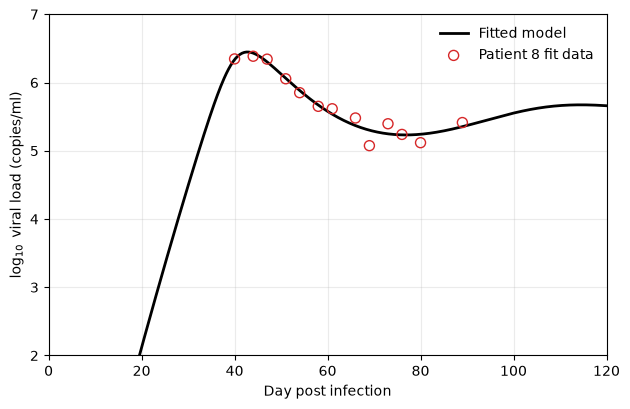

In [5]:
t_plot = np.linspace(0.0, 120.0, 500)
sol_plot = solve_ivp(lambda t, x: hiv_eq(t, x, theta_new),
                     [t_plot[0], t_plot[-1]], y0, t_eval=t_plot,
                     rtol=1e-9, atol=1e-11, method='LSODA')
if not sol_plot.success:
    raise RuntimeError(sol_plot.message)

viral_load_fit = np.log10(
    2.0 * np.maximum(sol_plot.y[2], 1e-30) * 1e3)
viral_load_patient = np.log10(xexp_fitting)

fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(t_plot, viral_load_fit, color='black', lw=2.0, label='Fitted model')
ax.scatter(
    tspan, viral_load_patient, s=52, facecolors='none',
    edgecolors='tab:red', zorder=3, label='Patient 8 fit data')
ax.set(xlabel='Day post infection', ylabel=r'$\log_{10}$ viral load (copies/ml)',
       xlim=(0, 120))
ax.grid(alpha=0.25)
ax.set_xlim(0, 120); ax.set_ylim(2, 7)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 5. First-order observable sensitivity in log coordinates

At the Patient-3 observation times, the model observable is

$$h(t,\theta)=\log_{10}(2V(t,\theta)\times10^3).$$

The ODE first propagates physical sensitivities as internal intermediates. With $\eta=\log\theta$ and $\partial\theta/\partial\eta=\operatorname{diag}(\theta)$, the reported observable Jacobian is

$$J_\eta=\frac{\partial h}{\partial\eta}
=\frac{\partial h}{\partial\theta}\operatorname{diag}(\theta).$$

All subsequent analyses evaluate $Z_\eta$ at $\widehat\theta$ and use the original Patient-3 observations `np.log10(xexp_fitting)` as the data vector.

In [6]:
t_sens = np.concatenate([[0.0], tspan])
S0 = np.concatenate([y0, np.zeros(N_STATE * N_THETA)])
sol_sens = solve_ivp(
    lambda t, S: hiv_ode_sens(t, S, theta_new),
    [t_sens[0], t_sens[-1]], S0, t_eval=t_sens,
    rtol=1e-10, atol=1e-12, method='DOP853')
if not sol_sens.success:
    raise RuntimeError(sol_sens.message)

X_sens = sol_sens.y[:N_STATE].T
Y_state_theta_full = sol_sens.y[N_STATE:].T.reshape(
    -1, N_STATE, N_THETA)
Y_state_theta_intermediate = (
    Y_state_theta_full[:, :, FREE_PARAM_IDX])

# h=log10(2*1e3*V); the multiplicative constant has zero derivative.
V_sens = np.maximum(X_sens[1:, 2], 1e-30)
Z_theta_intermediate = (Y_state_theta_intermediate[1:, 2, :]
           / (V_sens[:, None] * np.log(10.0)))
theta_free_fitted = theta_new[FREE_PARAM_IDX].copy()
Z_logtheta = (
    Z_theta_intermediate * theta_free_fitted[None, :])

print('analyzed log parameters =', FREE_LOG_PARAM_TXT)
print('Z_logtheta=dh/dlog(theta), shape =', Z_logtheta.shape)
print('Z_logtheta:\n', Z_logtheta)

analyzed log parameters = ['log(lambda)', 'log(d)', 'log(k)', 'log(delta)', 'log(p)']
Z_logtheta=dh/dlog(theta), shape = (13, 5)
Z_logtheta:
 [[ 1.3238e+00 -2.1067e+00  5.1423e+00 -1.6240e+00  5.3937e+00]
 [ 1.3217e-01 -1.2270e-01 -7.9992e-01 -1.7851e-01 -3.2337e-01]
 [-2.8686e-01  5.9877e-01 -2.6993e+00  1.9596e-01 -2.1592e+00]
 [-4.2033e-01  9.0496e-01 -3.3190e+00  1.6588e-01 -2.7625e+00]
 [-3.7793e-01  9.3386e-01 -3.2254e+00  1.7196e-03 -2.6749e+00]
 [-2.2497e-01  8.5603e-01 -2.7890e+00 -2.7307e-01 -2.2552e+00]
 [-6.3591e-02  7.4912e-01 -2.3390e+00 -4.8728e-01 -1.8208e+00]
 [ 2.6169e-01  5.2001e-01 -1.4807e+00 -8.2593e-01 -9.8983e-01]
 [ 4.7779e-01  3.6466e-01 -9.4153e-01 -1.0089e+00 -4.6673e-01]
 [ 7.7601e-01  1.4727e-01 -2.3076e-01 -1.2219e+00  2.2394e-01]
 [ 9.9822e-01 -1.8251e-02  2.7794e-01 -1.3548e+00  7.1897e-01]
 [ 1.2781e+00 -2.3471e-01  8.9838e-01 -1.4904e+00  1.3235e+00]
 [ 1.7321e+00 -6.4799e-01  1.8866e+00 -1.5813e+00  2.2883e+00]]


## 6. Residual-corrected curvature $K_\eta$ in log coordinates

At the fitted point $\eta^*$, define

$$F_\eta=J_\eta^TJ_\eta,\qquad
C_\eta=\sum_{n=1}^N r_n^*H_{\eta,n},\qquad
K_\eta=F_\eta+C_\eta,$$

where $r_n^*=h(t_n;\eta^*)-h_n^{\mathrm{obs}}$ and $H_{\eta,n}=\nabla_\eta^2h(t_n;\eta^*)$. The five columns correspond to the free log parameters $\log(\lambda,d,k,\delta,p)$; $c=3$ remains fixed. The analytic second-order sensitivity ODE is evaluated first, followed by the Gauss--Newton component, the residual correction, and the eigendecomposition of $K_\eta$.

In [7]:
def get_hiv_second_derivatives_theta(x, theta):
    T, I, V = x
    lam, d, k, delta, p, c = theta

    Hxx = np.zeros((N_STATE, N_STATE, N_STATE))
    Hxx[0, 0, 2] = Hxx[0, 2, 0] = -k
    Hxx[1, 0, 2] = Hxx[1, 2, 0] = k

    # Hxtheta[i,m,a] = d^2 f_i / (dx_m dtheta_a).
    Hxtheta = np.zeros((N_STATE, N_STATE, N_THETA))
    Hxtheta[0, 0, 1] = -1.0
    Hxtheta[0, 0, 2] = -V
    Hxtheta[0, 2, 2] = -T
    Hxtheta[1, 0, 2] = V
    Hxtheta[1, 1, 3] = -1.0
    Hxtheta[1, 2, 2] = T
    Hxtheta[2, 1, 4] = 1.0
    Hxtheta[2, 2, 5] = -1.0

    Hthetatheta = np.zeros((N_STATE, N_THETA, N_THETA))
    return Hxx, Hxtheta, Hthetatheta


def hiv_ode_sens2_theta(t, S, theta, n=N_STATE, k_dim=N_THETA):
    idx_y_end = n + n * k_dim
    x = S[:n]
    Y = S[n:idx_y_end].reshape(n, k_dim)
    Hstate = S[idx_y_end:].reshape(n, k_dim, k_dim)
    f, Jx, Jtheta = get_hiv_derivatives(x, theta)
    Hxx, Hxtheta, Hthetatheta = get_hiv_second_derivatives_theta(x, theta)
    dYdt = Jx @ Y + Jtheta
    dHdt = np.zeros_like(Hstate)
    for i in range(n):
        propagated = np.einsum('m,mab->ab', Jx[i], Hstate)
        state_curvature = Y.T @ Hxx[i] @ Y
        mixed = Y.T @ Hxtheta[i]
        dHdt[i] = (propagated + state_curvature + mixed + mixed.T
                   + Hthetatheta[i])
        dHdt[i] = 0.5 * (dHdt[i] + dHdt[i].T)
    return np.concatenate([f, dYdt.ravel(), dHdt.ravel()])


def observable_log_derivatives(theta, analysis_times, initial_state):
    """Return h, J_eta, H_eta and state derivatives at given times."""
    theta = np.asarray(theta, dtype=float)
    analysis_times = np.asarray(analysis_times, dtype=float)
    if theta.shape != (N_THETA,):
        raise ValueError(f'theta must have shape ({N_THETA},)')
    if (analysis_times.ndim != 1 or analysis_times.size == 0
            or analysis_times[0] <= 0.0
            or np.any(np.diff(analysis_times) <= 0.0)):
        raise ValueError(
            'analysis_times must be strictly increasing and positive')
    t_eval = np.concatenate([[0.0], analysis_times])
    initial_augmented = np.concatenate([
        initial_state,
        np.zeros(N_STATE * N_THETA),
        np.zeros(N_STATE * N_THETA * N_THETA),
    ])
    solution = solve_ivp(
        lambda t, S: hiv_ode_sens2_theta(t, S, theta),
        [0.0, t_eval[-1]], initial_augmented, t_eval=t_eval,
        rtol=1e-10, atol=1e-12, method='DOP853')
    if (not solution.success
            or solution.y.shape[1] != t_eval.size):
        raise RuntimeError(
            f'Second-sensitivity integration failed: '
            f'{solution.message}')

    states = solution.y[:N_STATE].T
    idx_y_end = N_STATE + N_STATE * N_THETA
    state_J_theta = solution.y[
        N_STATE:idx_y_end].T.reshape(-1, N_STATE, N_THETA)
    state_H_theta = solution.y[idx_y_end:].T.reshape(
        -1, N_STATE, N_THETA, N_THETA)
    output_H_theta = np.zeros(
        (t_eval.size, N_THETA, N_THETA))
    for q in range(t_eval.size):
        Vq = max(states[q, 2], 1e-30)
        dh_dx = np.array([
            0.0, 0.0, 1.0/(Vq*np.log(10.0))])
        d2h_dx2 = np.zeros((N_STATE, N_STATE))
        d2h_dx2[2, 2] = -1.0/(Vq**2*np.log(10.0))
        output_H_theta[q] = (
            state_J_theta[q].T @ d2h_dx2 @ state_J_theta[q]
            + np.tensordot(
                dh_dx, state_H_theta[q], axes=(0, 0)))
        output_H_theta[q] = 0.5*(
            output_H_theta[q] + output_H_theta[q].T)

    V = np.maximum(states[1:, 2], 1e-30)
    h = np.log10(2.0*V*1e3)
    J_theta = (state_J_theta[1:, 2, :]
               / (V[:, None]*np.log(10.0)))
    J_theta_free = J_theta[:, FREE_PARAM_IDX]
    H_theta_free = output_H_theta[
        1:][:, FREE_PARAM_IDX, :][:, :, FREE_PARAM_IDX]
    theta_free = theta[FREE_PARAM_IDX]
    J_eta = J_theta_free*theta_free[None, :]
    H_eta = (H_theta_free
             * theta_free[None, :, None]
             * theta_free[None, None, :])
    diag = np.arange(N_FREE)
    H_eta[:, diag, diag] += (
        J_theta_free*theta_free[None, :])
    H_eta = 0.5*(H_eta + np.swapaxes(H_eta, 1, 2))
    return h, J_eta, H_eta, state_J_theta


(h_derivative_reference, J_logtheta_sens2, H_logtheta,
 Y_state_theta_aug) = observable_log_derivatives(
    theta_new, tspan, y0)
second_order_J_consistent = np.allclose(
    J_logtheta_sens2, Z_logtheta, rtol=1e-6, atol=1e-9)
if not second_order_J_consistent:
    raise RuntimeError(
        'First- and second-order sensitivity ODEs disagree')
# Retain the common first-order array used in Sections 5--13.
J_logtheta = Z_logtheta.copy()

print('J_logtheta shape =', J_logtheta.shape)
print('H_logtheta shape =', H_logtheta.shape)
print('first-order propagation consistency =', np.allclose(
    Y_state_theta_aug, Y_state_theta_full, rtol=1e-6, atol=1e-8))
print('second-order ODE J equals Z_logtheta =',
      second_order_J_consistent)
print('H_logtheta symmetric =', np.allclose(
    H_logtheta, np.swapaxes(H_logtheta, 1, 2),
    rtol=1e-12, atol=1e-12))

J_logtheta shape = (13, 5)
H_logtheta shape = (13, 5, 5)
first-order propagation consistency = True
second-order ODE J equals Z_logtheta = True
H_logtheta symmetric = True


In [8]:
# Gauss--Newton component F_eta needed for K_eta and Theorem 2.
G_logtheta = Z_logtheta.T @ Z_logtheta
G_logtheta = 0.5 * (G_logtheta + G_logtheta.T)

# Eigen-decomposition of F_eta through the SVD of the Jacobian:
# Z = U S V^T  =>  F_eta = Z^T Z = V S^2 V^T, so the eigenvalues are the
# squared singular values and the eigenvectors are the right singular
# vectors.  Working on Z instead of Z^T Z avoids squaring the condition
# number, which matters for the small eigenvalues.
(_, svd_singular_values_logtheta,
 svd_Vt_logtheta) = np.linalg.svd(Z_logtheta, full_matrices=True)
# np.linalg.svd returns singular values in descending order; pad with
# zeros if there are fewer observations than free parameters.
sqrt_eigvals_logtheta = np.zeros(N_FREE)
sqrt_eigvals_logtheta[:svd_singular_values_logtheta.size] = (
    svd_singular_values_logtheta)
eigvals_logtheta = sqrt_eigvals_logtheta**2
eigvecs_logtheta = svd_Vt_logtheta.T.copy()

# Cross-check against a direct symmetric eigensolve of G = Z^T Z.
eigh_eigvals_logtheta = np.linalg.eigvalsh(G_logtheta)[::-1]
svd_vs_eigh_rel_diff = (
    np.max(np.abs(eigvals_logtheta-eigh_eigvals_logtheta))
    / eigvals_logtheta[0])

# Independent check against the analytic Jacobian used by the fitter.
_, Z_logtheta_fit = residual_and_jacobian_log(eta_free_new)
log_jacobian_consistent = np.allclose(
    Z_logtheta, Z_logtheta_fit, rtol=1e-6, atol=1e-9)
if not log_jacobian_consistent:
    raise RuntimeError(
        'Log-coordinate observable Jacobian is inconsistent with fit Jacobian')

print('Z_logtheta = dh/dlog(theta), shape =', Z_logtheta.shape)
print('Z_logtheta:\n', Z_logtheta)
print('log Jacobian equals fitting Jacobian =',
      log_jacobian_consistent)
print('G_logtheta = Z_logtheta.T @ Z_logtheta:\n', G_logtheta)
print('eigenvalues of G_logtheta (from SVD of Z_logtheta):\n',
      eigvals_logtheta)
print('eigenvalues from direct eigh(G_logtheta):\n',
      eigh_eigvals_logtheta)
print('max |lambda_svd - lambda_eigh| / lambda_1 =',
      f'{svd_vs_eigh_rel_diff:.3e}')
print('sqrt(eigenvalues):\n', sqrt_eigvals_logtheta)
print('eigenvectors (columns, largest to smallest eigenvalue):\n',
      eigvecs_logtheta)

# Plots of the F_eta spectrum and eigenvectors are drawn together with
# K_eta in the comparison figure below.


Z_logtheta = dh/dlog(theta), shape = (13, 5)
Z_logtheta:
 [[ 1.3238e+00 -2.1067e+00  5.1423e+00 -1.6240e+00  5.3937e+00]
 [ 1.3217e-01 -1.2270e-01 -7.9992e-01 -1.7851e-01 -3.2337e-01]
 [-2.8686e-01  5.9877e-01 -2.6993e+00  1.9596e-01 -2.1592e+00]
 [-4.2033e-01  9.0496e-01 -3.3190e+00  1.6588e-01 -2.7625e+00]
 [-3.7793e-01  9.3386e-01 -3.2254e+00  1.7196e-03 -2.6749e+00]
 [-2.2497e-01  8.5603e-01 -2.7890e+00 -2.7307e-01 -2.2552e+00]
 [-6.3591e-02  7.4912e-01 -2.3390e+00 -4.8728e-01 -1.8208e+00]
 [ 2.6169e-01  5.2001e-01 -1.4807e+00 -8.2593e-01 -9.8983e-01]
 [ 4.7779e-01  3.6466e-01 -9.4153e-01 -1.0089e+00 -4.6673e-01]
 [ 7.7601e-01  1.4727e-01 -2.3076e-01 -1.2219e+00  2.2394e-01]
 [ 9.9822e-01 -1.8251e-02  2.7794e-01 -1.3548e+00  7.1897e-01]
 [ 1.2781e+00 -2.3471e-01  8.9838e-01 -1.4904e+00  1.3235e+00]
 [ 1.7321e+00 -6.4799e-01  1.8866e+00 -1.5813e+00  2.2883e+00]]
log Jacobian equals fitting Jacobian = True
G_logtheta = Z_logtheta.T @ Z_logtheta:
 [[  8.7554  -4.9664  14.5433  -9.8501

K_eta = J_eta.T @ J_eta + sum_n r_n^* H_n:
[[  8.7787  -4.9115  14.4264  -9.8402  16.4654]
 [ -4.9115   8.5648 -24.7587   3.4583 -23.0452]
 [ 14.4264 -24.7587  75.7819  -9.4442  68.9255]
 [ -9.8402   3.4583  -9.4442  12.7599 -13.4505]
 [ 16.4654 -23.0452  68.9255 -13.4505  65.026 ]]

||r*||_2 = 0.3407686076007091

Residual-curvature contribution:
[[ 0.0233  0.0549 -0.1168  0.0099 -0.1111]
 [ 0.0549 -0.1326  0.334  -0.0771  0.322 ]
 [-0.1168  0.334  -0.8318  0.1917 -0.8016]
 [ 0.0099 -0.0771  0.1917 -0.0374  0.1842]
 [-0.1111  0.322  -0.8016  0.1842 -0.7724]]

Eigenvalues of K_eta (largest to smallest):
[1.5350e+02 1.6586e+01 5.4802e-01 2.7426e-01 3.8131e-04]

Square roots of eigenvalues of K_eta:
[12.3896  4.0725  0.7403  0.5237  0.0195]

Eigenvectors of K_eta (columns, largest to smallest eigenvalue):
[[-1.5960e-01  5.2887e-01 -3.7813e-01 -7.4236e-01 -2.7225e-02]
 [ 2.3049e-01  7.4978e-02 -7.1859e-01  3.4971e-01  5.5008e-01]
 [-6.9491e-01 -3.0302e-01 -4.7341e-01  1.8957e-01 -4.0648e-0

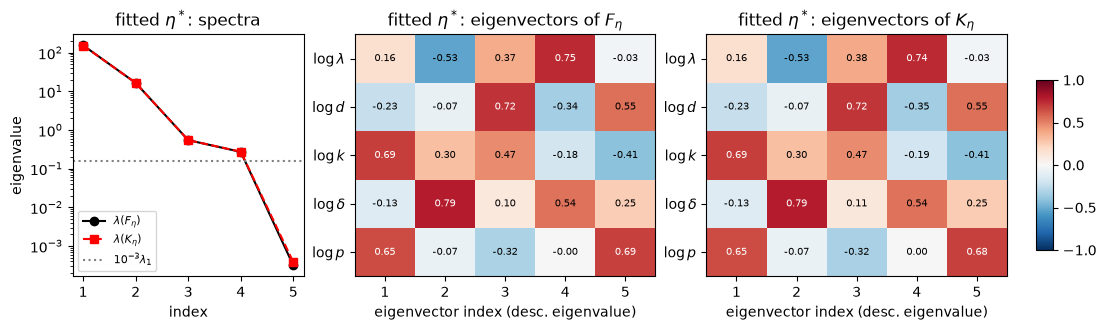

In [9]:
# Full observed-data curvature K_eta at the fitted eta*.
# The present HIV analysis has one observable per time point (L=1).
# J_eta and H_eta are the analytic arrays propagated above.
k_matrix_eta_star = eta_free_new.copy()
k_matrix_observed_h = np.log10(xexp_fitting)
k_matrix_h_star = h_derivative_reference.copy()
k_matrix_residual_star = k_matrix_h_star-k_matrix_observed_h
k_matrix_J_eta = J_logtheta.copy()
k_matrix_H_eta = H_logtheta.copy()
if not np.allclose(
        k_matrix_J_eta, Z_logtheta, rtol=1e-6, atol=1e-9):
    raise RuntimeError('Part-6 analytic J_eta arrays are inconsistent')
if not np.allclose(
        k_matrix_H_eta, np.swapaxes(k_matrix_H_eta, 1, 2),
        rtol=1e-12, atol=1e-12):
    raise RuntimeError('Part-6 analytic H_eta is not symmetric')
k_matrix_gauss_newton = k_matrix_J_eta.T @ k_matrix_J_eta
k_matrix_residual_curvature = np.einsum(
    'n,nij->ij', k_matrix_residual_star, k_matrix_H_eta,
    optimize=True)
K_eta = k_matrix_gauss_newton+k_matrix_residual_curvature
K_eta = 0.5*(K_eta+K_eta.T)

# np.linalg.eigh returns eigenpairs from smallest to largest eigenvalue.
(k_matrix_eigenvalues_ascending,
 k_matrix_eigenvectors_ascending) = np.linalg.eigh(K_eta)
k_matrix_descending_order = np.arange(N_FREE-1, -1, -1)
k_matrix_eigenvalues = (
    k_matrix_eigenvalues_ascending[k_matrix_descending_order])
k_matrix_eigenvectors = (
    k_matrix_eigenvectors_ascending[:, k_matrix_descending_order])
k_matrix_eigenpair_residual = np.linalg.norm(
    K_eta @ k_matrix_eigenvectors
    - k_matrix_eigenvectors*k_matrix_eigenvalues[None, :])
k_matrix_sqrt_eigenvalues = np.full(N_FREE, np.nan)
np.sqrt(
    k_matrix_eigenvalues,
    out=k_matrix_sqrt_eigenvalues,
    where=k_matrix_eigenvalues >= 0.0)

K_eta_results = {
    'coordinate': 'eta = log(theta_free)',
    'eta_star': k_matrix_eta_star,
    'observed_h': k_matrix_observed_h,
    'h_at_eta_star': k_matrix_h_star,
    'residual_star': k_matrix_residual_star,
    'J_eta': k_matrix_J_eta,
    'H_eta': k_matrix_H_eta,
    'gauss_newton': k_matrix_gauss_newton,
    'residual_curvature': k_matrix_residual_curvature,
    'K_eta': K_eta,
    'eigenvalues_descending': k_matrix_eigenvalues,
    'sqrt_eigenvalues_descending': k_matrix_sqrt_eigenvalues,
    'eigenvectors_descending': k_matrix_eigenvectors,
    'eigenvalues_ascending': k_matrix_eigenvalues_ascending,
    'eigenvectors_ascending': k_matrix_eigenvectors_ascending,
    'eigenpair_residual_norm': k_matrix_eigenpair_residual,
}

print('K_eta = J_eta.T @ J_eta + sum_n r_n^* H_n:')
print(K_eta)
print('\n||r*||_2 =', np.linalg.norm(k_matrix_residual_star))
print('\nResidual-curvature contribution:')
print(k_matrix_residual_curvature)
print('\nEigenvalues of K_eta (largest to smallest):')
print(k_matrix_eigenvalues)
print('\nSquare roots of eigenvalues of K_eta:')
print(k_matrix_sqrt_eigenvalues)
print('\nEigenvectors of K_eta '
      '(columns, largest to smallest eigenvalue):')
print(k_matrix_eigenvectors)
print('\nEigenpair residual norm =', k_matrix_eigenpair_residual)

# Side-by-side comparison of F_eta and K_eta: eigenvalue spectra and
# signed eigenvector heat maps (one row per parameter point).
SPECTRUM_RELATIVE_THRESHOLD = 1e-3


def _align_eigenvector_signs(vectors, reference=None):
    """Fix the arbitrary sign of every eigenvector column.

    Without a reference, the largest-magnitude component is made
    positive.  With a reference, each column is flipped so that it has
    a non-negative inner product with the corresponding reference column.
    """
    aligned = vectors.copy()
    for col in range(aligned.shape[1]):
        if reference is None:
            pivot = np.argmax(np.abs(aligned[:, col]))
            sign = np.sign(aligned[pivot, col])
        else:
            sign = np.sign(reference[:, col] @ aligned[:, col])
        if sign < 0.0:
            aligned[:, col] *= -1.0
    return aligned


def _descending_eigh(matrix):
    values, vectors = np.linalg.eigh(0.5*(matrix+matrix.T))
    order = np.argsort(values)[::-1]
    return values[order], vectors[:, order]


def _eigenvector_heatmap(ax, vectors, row_labels, title, xlabel=True):
    n_rows, n_cols = vectors.shape
    im = ax.imshow(
        vectors, cmap='RdBu_r', vmin=-1.0, vmax=1.0, aspect='auto')
    ax.set_xticks(np.arange(n_cols))
    ax.set_xticklabels(np.arange(1, n_cols+1))
    ax.set_yticks(np.arange(n_rows))
    ax.set_yticklabels(row_labels)
    ax.set_title(title)
    if xlabel:
        ax.set_xlabel('eigenvector index (desc. eigenvalue)')
    for row in range(n_rows):
        for col in range(n_cols):
            value = vectors[row, col]
            ax.text(
                col, row, f'{value:.2f}', ha='center', va='center',
                fontsize=7,
                color='white' if abs(value) > 0.6 else 'black')
    return im


def _descending_eig_from_svd(jacobian):
    """Eigenpairs of F = J^T J from the SVD of J (no squaring of J)."""
    _, singular_values, Vt = np.linalg.svd(jacobian, full_matrices=True)
    values = np.zeros(Vt.shape[0])
    values[:singular_values.size] = singular_values**2
    return values, Vt.T.copy()


def plot_F_K_comparison(cases, row_labels, figsize_per_row=3.4,
                        subscript=r'\eta'):
    """cases: list of (case_label, J_eta, K_eta).

    F_eta = J_eta^T J_eta is decomposed through the SVD of J_eta;
    K_eta is decomposed with the symmetric eigensolver np.linalg.eigh.
    `subscript` is the TeX subscript used in titles and legends.
    """
    n_cases = len(cases)
    fig, axes = plt.subplots(
        n_cases, 3, figsize=(11.5, figsize_per_row*n_cases),
        squeeze=False, gridspec_kw={'width_ratios': [1.0, 1.3, 1.3]})
    im = None
    for row, (label, J_matrix, K_matrix) in enumerate(cases):
        F_values, F_vectors = _descending_eig_from_svd(J_matrix)
        K_values, K_vectors = _descending_eigh(K_matrix)
        F_vectors = _align_eigenvector_signs(F_vectors)
        K_vectors = _align_eigenvector_signs(K_vectors, reference=F_vectors)
        index = np.arange(1, F_values.size+1)
        last = row == n_cases-1

        # --- spectra -------------------------------------------------
        ax = axes[row, 0]
        for values, style, name in (
                (F_values, dict(color='k', marker='o', ls='-'),
                 fr'$\lambda(F_{{{subscript}}})$'),
                (K_values, dict(color='r', marker='s', ls='--'),
                 fr'$\lambda(K_{{{subscript}}})$')):
            shown = np.maximum(np.abs(values), np.finfo(float).tiny)
            ax.plot(index, shown, label=name, **style)
            negative = values < 0.0
            if np.any(negative):
                ax.plot(
                    index[negative], shown[negative], ls='none',
                    marker=style['marker'], mfc='white',
                    mec=style['color'], ms=9,
                    label=f'{name} < 0 (|value| shown)')
        threshold = SPECTRUM_RELATIVE_THRESHOLD*F_values[0]
        ax.axhline(
            threshold, color='gray', ls=':',
            label=fr'$10^{{{int(np.log10(SPECTRUM_RELATIVE_THRESHOLD))}}}\lambda_1$')
        ax.set_yscale('log')
        ax.set_xticks(index)
        ax.set_ylabel('eigenvalue')
        ax.set_title(f'{label}: spectra')
        ax.legend(fontsize=8, loc='lower left')
        if last:
            ax.set_xlabel('index')

        # --- eigenvector heat maps ------------------------------------
        _eigenvector_heatmap(
            axes[row, 1], F_vectors, row_labels,
            fr'{label}: eigenvectors of $F_{{{subscript}}}$', xlabel=last)
        im = _eigenvector_heatmap(
            axes[row, 2], K_vectors, row_labels,
            fr'{label}: eigenvectors of $K_{{{subscript}}}$', xlabel=last)

    fig.tight_layout()
    fig.subplots_adjust(right=0.88)
    cbar_ax = fig.add_axes([0.905, 0.25, 0.015, 0.5])
    fig.colorbar(im, cax=cbar_ax)
    return fig, axes


fig, _ = plot_F_K_comparison(
    [(r'fitted $\eta^*$', Z_logtheta, K_eta)], FREE_LOG_PARAM_TEX)
plt.show()


### 6b. Perturbation check: why the eigenvectors of $F_\eta$ and $K_\eta$ are so close

Write $F_\eta=U_\eta\Lambda_\eta U_\eta^\top$ with the SVD-based eigenpairs of Part 6 and define the rotated residual curvature

$$E_\eta:=U_\eta^\top C_\eta U_\eta,\qquad C_\eta=\sum_n r_n^*H_{\eta,n},$$

so that $K_\eta=U_\eta(\Lambda_\eta+E_\eta)U_\eta^\top$. For a small perturbation with simple, well-separated eigenvalues, standard first-order perturbation theory gives

$$\lambda_i(K_\eta)\approx\lambda_i(F_\eta)+(E_\eta)_{ii}+\sum_{j\ne i}\frac{(E_\eta)_{ji}^2}{\lambda_i(F_\eta)-\lambda_j(F_\eta)},\qquad
\Delta u_i\approx\sum_{j\ne i}\frac{(E_\eta)_{ji}}{\lambda_i(F_\eta)-\lambda_j(F_\eta)}\,u_j .$$

Small eigenvector changes therefore correspond to small scaled couplings

$$\rho_{ji}:=\frac{|(E_\eta)_{ji}|}{|\lambda_i(F_\eta)-\lambda_j(F_\eta)|}\ll1 .$$

The code below forms $E_\eta$, tabulates the first- and second-order eigenvalue predictions against the actual $\lambda_i(K_\eta)$, evaluates $\rho_{ji}$, and compares the predicted $\Delta u_i$ with the actual sign-aligned difference between the eigenvectors of $K_\eta$ and $F_\eta$. Directions whose $F_\eta$ eigenvalue is smaller than $(E_\eta)_{ii}$ are outside the small-perturbation regime and are flagged.


E_eta = U^T C_eta U (F_eta eigenbasis, descending eigenvalues):
[[-1.785e+00  2.057e-02  1.207e-01  8.754e-02 -3.417e-02]
 [ 2.057e-02  3.010e-02  1.336e-02  1.634e-02  1.620e-03]
 [ 1.207e-01  1.336e-02  1.094e-03  3.748e-03  1.618e-03]
 [ 8.754e-02  1.634e-02  3.748e-03  2.599e-03  9.622e-04]
 [-3.417e-02  1.620e-03  1.618e-03  9.622e-04  8.523e-05]]

Eigenvalue perturbation check:
 i  lambda_i(F)        E_ii |E_ii|/l_i    1st order    2nd order  lambda_i(K) rel.err 1st rel.err 2nd  regime
 1   1.5529e+02  -1.785e+00  1.149e-02   1.5350e+02   1.5350e+02   1.5350e+02   1.016e-06   1.181e-08   small
 2   1.6556e+01   3.010e-02  1.818e-03   1.6586e+01   1.6586e+01   1.6586e+01   1.478e-06   8.300e-09   small
 3   5.4698e-01   1.094e-03  2.000e-03   5.4808e-01   5.4803e-01   5.4802e-01   9.535e-05   5.091e-06   small
 4   2.7177e-01   2.599e-03  9.562e-03   2.7437e-01   2.7426e-01   2.7426e-01   4.087e-04   4.980e-06   small
 5   3.1220e-04   8.523e-05  2.730e-01   3.9743e-04   3.8156e-0

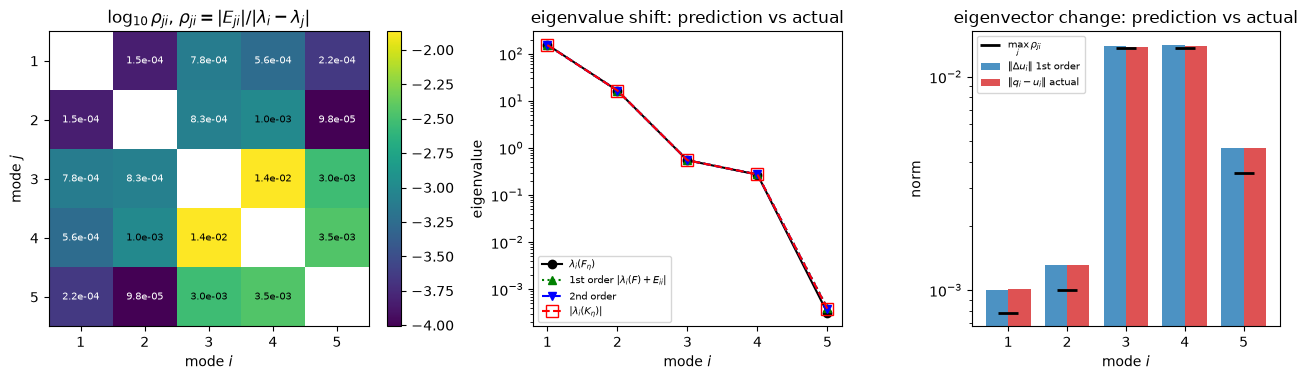

In [10]:
# Perturbation-theory check for K_eta = F_eta + C_eta in the F_eta
# eigenbasis: E_eta = U^T C_eta U.
pert_U = eigvecs_logtheta.copy()            # SVD-based eigenvectors of F
pert_lambda_F = eigvals_logtheta.copy()     # descending eigenvalues of F
pert_C = 0.5*(k_matrix_residual_curvature+k_matrix_residual_curvature.T)
pert_E = pert_U.T @ pert_C @ pert_U
pert_E = 0.5*(pert_E+pert_E.T)
if not np.allclose(
        pert_U @ (np.diag(pert_lambda_F)+pert_E) @ pert_U.T, K_eta,
        rtol=1e-9, atol=1e-12*max(np.abs(K_eta).max(), 1.0)):
    raise RuntimeError('U (Lambda + E) U^T does not reproduce K_eta')

# Actual eigenpairs of K_eta, sign-aligned to the F eigenvectors.
pert_lambda_K = k_matrix_eigenvalues.copy()
pert_Q = k_matrix_eigenvectors.copy()
for i in range(N_FREE):
    if pert_U[:, i] @ pert_Q[:, i] < 0.0:
        pert_Q[:, i] *= -1.0

# Eigenvalue gaps and scaled couplings rho_ji = |E_ji| / |lambda_i - lambda_j|.
pert_gap = pert_lambda_F[None, :]-pert_lambda_F[:, None]   # gap[j, i] = l_i - l_j
pert_offdiag = ~np.eye(N_FREE, dtype=bool)
pert_rho = np.full((N_FREE, N_FREE), np.nan)
np.divide(np.abs(pert_E), np.abs(pert_gap), out=pert_rho, where=pert_offdiag)
pert_rho_max_per_mode = np.nanmax(pert_rho, axis=0)

# First- and second-order eigenvalue predictions.
pert_lambda_first = pert_lambda_F+np.diag(pert_E)
pert_second_order_term = np.zeros(N_FREE)
for i in range(N_FREE):
    for j in range(N_FREE):
        if j != i:
            pert_second_order_term[i] += pert_E[j, i]**2/pert_gap[j, i]
pert_lambda_second = pert_lambda_first+pert_second_order_term
pert_relative_perturbation = np.abs(np.diag(pert_E))/np.maximum(
    pert_lambda_F, np.finfo(float).tiny)
pert_small_regime = pert_relative_perturbation < 1.0

# First-order eigenvector change, predicted and actual.
pert_coefficients = np.zeros((N_FREE, N_FREE))   # coefficient of u_j in Delta u_i
np.divide(pert_E, pert_gap, out=pert_coefficients, where=pert_offdiag)
pert_delta_u_pred = pert_U @ pert_coefficients
pert_delta_u_actual = pert_Q-pert_U
pert_delta_u_pred_norm = np.linalg.norm(pert_delta_u_pred, axis=0)
pert_delta_u_actual_norm = np.linalg.norm(pert_delta_u_actual, axis=0)
pert_delta_u_pred_error = np.linalg.norm(
    pert_delta_u_pred-pert_delta_u_actual, axis=0)
pert_cosine = np.clip(np.abs(np.sum(pert_U*pert_Q, axis=0)), 0.0, 1.0)
pert_angle_deg = np.degrees(np.arccos(pert_cosine))
pert_overlap = pert_U.T @ pert_Q    # overlap[j, i] = u_j . q_i

perturbation_check = {
    'U_F': pert_U, 'lambda_F': pert_lambda_F, 'C_eta': pert_C, 'E_eta': pert_E,
    'lambda_K': pert_lambda_K, 'Q_K_sign_aligned': pert_Q,
    'gap_lambda_i_minus_lambda_j': pert_gap,
    'rho_scaled_coupling': pert_rho, 'rho_max_per_mode': pert_rho_max_per_mode,
    'lambda_first_order': pert_lambda_first,
    'lambda_second_order': pert_lambda_second,
    'relative_diagonal_perturbation': pert_relative_perturbation,
    'small_perturbation_regime': pert_small_regime,
    'delta_u_predicted': pert_delta_u_pred,
    'delta_u_actual': pert_delta_u_actual,
    'delta_u_predicted_norm': pert_delta_u_pred_norm,
    'delta_u_actual_norm': pert_delta_u_actual_norm,
    'delta_u_prediction_error_norm': pert_delta_u_pred_error,
    'angle_deg_between_u_i_and_q_i': pert_angle_deg,
    'overlap_U_T_Q': pert_overlap,
}

np.set_printoptions(precision=3, suppress=False, linewidth=140)
print('E_eta = U^T C_eta U (F_eta eigenbasis, descending eigenvalues):')
print(pert_E)
print('\nEigenvalue perturbation check:')
print(f"{'i':>2s} {'lambda_i(F)':>12s} {'E_ii':>11s} {'|E_ii|/l_i':>10s} "
      f"{'1st order':>12s} {'2nd order':>12s} {'lambda_i(K)':>12s} "
      f"{'rel.err 1st':>11s} {'rel.err 2nd':>11s} {'regime':>7s}")
for i in range(N_FREE):
    err1 = abs(pert_lambda_first[i]-pert_lambda_K[i])/abs(pert_lambda_K[i])
    err2 = abs(pert_lambda_second[i]-pert_lambda_K[i])/abs(pert_lambda_K[i])
    print(f'{i+1:>2d} {pert_lambda_F[i]:12.4e} {pert_E[i, i]:11.3e} '
          f'{pert_relative_perturbation[i]:10.3e} '
          f'{pert_lambda_first[i]:12.4e} {pert_lambda_second[i]:12.4e} '
          f'{pert_lambda_K[i]:12.4e} {err1:11.3e} {err2:11.3e} '
          f"{'small' if pert_small_regime[i] else 'LARGE':>7s}")
print('\nScaled couplings rho_ji = |E_ji| / |lambda_i(F) - lambda_j(F)| '
      '(row j, column i):')
print(pert_rho)
print('max_j rho_ji per mode i =', pert_rho_max_per_mode)
print('\nEigenvector perturbation check (columns = modes i):')
print(f"{'i':>2s} {'max rho':>9s} {'||du_i|| pred':>13s} "
      f"{'||du_i|| actual':>15s} {'||pred-actual||':>15s} {'angle(u_i,q_i) deg':>18s}")
for i in range(N_FREE):
    print(f'{i+1:>2d} {pert_rho_max_per_mode[i]:9.3e} '
          f'{pert_delta_u_pred_norm[i]:13.3e} {pert_delta_u_actual_norm[i]:15.3e} '
          f'{pert_delta_u_pred_error[i]:15.3e} {pert_angle_deg[i]:18.3f}')
print('\nOverlap matrix U^T Q (rows: u_j, columns: q_i, sign-aligned):')
print(pert_overlap)
if not np.all(pert_small_regime):
    print('\nNOTE: modes marked LARGE have |E_ii| >= lambda_i(F); the '
          'first-order formulas are not expected to be accurate there.')
np.set_printoptions(precision=4, suppress=False, linewidth=120)

# --- figure: scaled couplings, eigenvalue shifts, eigenvector changes ---
fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.9),
                         gridspec_kw={'width_ratios': [1.15, 1.0, 1.0]})
pert_index = np.arange(1, N_FREE+1)

ax = axes[0]
pert_rho_plot = np.log10(np.where(pert_offdiag, np.maximum(pert_rho, 1e-300), np.nan))
im = ax.imshow(pert_rho_plot, cmap='viridis', aspect='auto')
ax.set_xticks(np.arange(N_FREE)); ax.set_xticklabels(pert_index)
ax.set_yticks(np.arange(N_FREE)); ax.set_yticklabels(pert_index)
ax.set_xlabel('mode $i$'); ax.set_ylabel('mode $j$')
ax.set_title(r'$\log_{10}\rho_{ji}$, $\rho_{ji}=|E_{ji}|/|\lambda_i-\lambda_j|$')
for j in range(N_FREE):
    for i in range(N_FREE):
        if j != i:
            ax.text(i, j, f'{pert_rho[j, i]:.1e}', ha='center', va='center',
                    fontsize=7, color='white' if pert_rho_plot[j, i] < np.nanmean(pert_rho_plot) else 'black')
fig.colorbar(im, ax=ax, fraction=0.046)

ax = axes[1]
ax.plot(pert_index, pert_lambda_F, 'ko-', label=r'$\lambda_i(F_\eta)$')
ax.plot(pert_index, np.abs(pert_lambda_first), 'g^:', label=r'1st order $|\lambda_i(F)+E_{ii}|$')
ax.plot(pert_index, np.abs(pert_lambda_second), 'bv--', label='2nd order')
ax.plot(pert_index, np.abs(pert_lambda_K), 'rs--', mfc='none', ms=9, label=r'$|\lambda_i(K_\eta)|$')
ax.set_yscale('log'); ax.set_xticks(pert_index)
ax.set_xlabel('mode $i$'); ax.set_ylabel('eigenvalue')
ax.set_title('eigenvalue shift: prediction vs actual')
ax.legend(fontsize=7, loc='lower left')

ax = axes[2]
width = 0.38
ax.bar(pert_index-width/2, pert_delta_u_pred_norm, width, color='tab:blue',
       alpha=0.8, label=r'$\|\Delta u_i\|$ 1st order')
ax.bar(pert_index+width/2, pert_delta_u_actual_norm, width, color='tab:red',
       alpha=0.8, label=r'$\|q_i-u_i\|$ actual')
ax.plot(pert_index, pert_rho_max_per_mode, 'k_', ms=14, mew=2,
        label=r'$\max_j\rho_{ji}$')
ax.set_yscale('log'); ax.set_xticks(pert_index)
ax.set_xlabel('mode $i$'); ax.set_ylabel('norm')
ax.set_title('eigenvector change: prediction vs actual')
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()


## 7. Indicators from Theorem 2 of `M3as_Manuscript.pdf`

Using the notation of Theorem 2, decompose the Gauss--Newton curvature into its numerically resolved and near-null parameter subspaces,

$$[U,V]^TF_\eta[U,V]=\begin{pmatrix}\Lambda&0\\0&0\end{pmatrix},$$

and form $E=U^TC_\eta U$, $B=U^TC_\eta V$, $D=V^TC_\eta V$, and $A=\Lambda+E$. The code below first reports the theorem assumptions (interior point, verified local minimum, and $K_\eta\succeq0$), then every indicator in statements (1)--(5), Eqs. (1.32)--(1.45): positive-curvature preservation, $\epsilon_U$, the Schur complement and rank change, remaining-null-space rotation, and changes in the nonzero eigendirections.

`THEOREM2_SINGULAR_VALUE_THRESHOLD` defines the numerical split between $U$ and $V$; it is independent of settings in other parts.

In [11]:
# Independent numerical settings for Theorem 2.
THEOREM2_SINGULAR_VALUE_THRESHOLD = 1e-3
THEOREM2_RELATIVE_TOLERANCE = 1e-8

if THEOREM2_SINGULAR_VALUE_THRESHOLD <= 0.0:
    raise ValueError(
        'THEOREM2_SINGULAR_VALUE_THRESHOLD must be positive')
if THEOREM2_RELATIVE_TOLERANCE <= 0.0:
    raise ValueError('THEOREM2_RELATIVE_TOLERANCE must be positive')

theorem2_J = k_matrix_J_eta.copy()
theorem2_F = k_matrix_gauss_newton.copy()
theorem2_C = k_matrix_residual_curvature.copy()
theorem2_K = K_eta.copy()
theorem2_k = theorem2_J.shape[1]

# Eq. (1.30): right singular vectors give the parameter-space U,V basis.
(_, theorem2_singular_values,
 theorem2_Vt_parameter) = np.linalg.svd(
    theorem2_J, full_matrices=True)
theorem2_r = int(np.count_nonzero(
    theorem2_singular_values
    >= THEOREM2_SINGULAR_VALUE_THRESHOLD))
if not 1 <= theorem2_r <= theorem2_k:
    raise ValueError(
        'The numerical decomposition requires 1 <= rank(F_eta) <= k; '
        f'current rank is {theorem2_r} for k={theorem2_k}. '
        'Adjust THEOREM2_SINGULAR_VALUE_THRESHOLD if appropriate.')
theorem2_F_full_rank = bool(theorem2_r == theorem2_k)
theorem2_U = theorem2_Vt_parameter.T[:, :theorem2_r]
theorem2_V = theorem2_Vt_parameter.T[:, theorem2_r:]
theorem2_Lambda = np.diag(
    theorem2_singular_values[:theorem2_r]**2)
theorem2_basis = np.column_stack([theorem2_U, theorem2_V])
theorem2_basis_orthogonality_error = np.linalg.norm(
    theorem2_basis.T @ theorem2_basis-np.eye(theorem2_k))
theorem2_F_block_error = np.linalg.norm(
    theorem2_basis.T @ theorem2_F @ theorem2_basis
    - np.block([
        [theorem2_Lambda,
         np.zeros((theorem2_r, theorem2_k-theorem2_r))],
        [np.zeros((theorem2_k-theorem2_r, theorem2_r)),
         np.zeros((theorem2_k-theorem2_r,
                   theorem2_k-theorem2_r))],
    ]))

# Eq. (1.31): residual-curvature blocks.
theorem2_E = theorem2_U.T @ theorem2_C @ theorem2_U
theorem2_B = theorem2_U.T @ theorem2_C @ theorem2_V
theorem2_D = theorem2_V.T @ theorem2_C @ theorem2_V
theorem2_A = theorem2_Lambda+theorem2_E
theorem2_A = 0.5*(theorem2_A+theorem2_A.T)
theorem2_D = 0.5*(theorem2_D+theorem2_D.T)
theorem2_scale = max(
    float(np.linalg.norm(theorem2_K, 2)),
    float(np.linalg.norm(theorem2_F, 2)),
    np.finfo(float).tiny)
theorem2_matrix_tolerance = (
    THEOREM2_RELATIVE_TOLERANCE*theorem2_scale)
theorem2_K_block_error = np.linalg.norm(
    theorem2_basis.T @ theorem2_K @ theorem2_basis
    - np.block([[theorem2_A, theorem2_B],
                [theorem2_B.T, theorem2_D]]))
theorem2_interior_point = bool(
    not np.any(near_lower_bound | near_upper_bound))
theorem2_local_minimum_verified = bool(
    fit_local_minimum_verified)

# Statement (1), Eq. (1.32): preservation of positive curvature on U.
theorem2_lambda_diagonal = np.diag(theorem2_Lambda)
theorem2_Lambda_inverse_sqrt = np.diag(
    1.0/np.sqrt(theorem2_lambda_diagonal))
theorem2_relative_E = (
    theorem2_Lambda_inverse_sqrt
    @ theorem2_E @ theorem2_Lambda_inverse_sqrt)
theorem2_relative_E = 0.5*(
    theorem2_relative_E+theorem2_relative_E.T)
theorem2_relative_E_eigenvalues = np.linalg.eigvalsh(
    theorem2_relative_E)
theorem2_relative_E_min_eigenvalue = float(
    theorem2_relative_E_eigenvalues[0])
theorem2_A_eigenvalues = np.linalg.eigvalsh(theorem2_A)
theorem2_A_positive_definite = bool(
    theorem2_A_eigenvalues[0] > theorem2_matrix_tolerance)
theorem2_statement1_relative_condition = bool(
    theorem2_relative_E_min_eigenvalue > -1.0)
theorem2_statement1_equivalence_holds = bool(
    theorem2_A_positive_definite
    == theorem2_statement1_relative_condition)

# Statement (2), Eqs. (1.33)--(1.34): relative curvature change.
theorem2_epsilon_U = float(np.linalg.norm(
    theorem2_relative_E, 2))
theorem2_lower_Loewner_margin = float(np.min(np.linalg.eigvalsh(
    theorem2_A-(1.0-theorem2_epsilon_U)*theorem2_Lambda)))
theorem2_upper_Loewner_margin = float(np.min(np.linalg.eigvalsh(
    (1.0+theorem2_epsilon_U)*theorem2_Lambda-theorem2_A)))
theorem2_epsilon_U_below_one = bool(theorem2_epsilon_U < 1.0)

# Statement (3), Eqs. (1.35)--(1.36): Schur rank and nullity.
theorem2_A_inverse_B = np.linalg.solve(
    theorem2_A, theorem2_B)
theorem2_S = (
    theorem2_D-theorem2_B.T @ theorem2_A_inverse_B)
theorem2_S = 0.5*(theorem2_S+theorem2_S.T)
(theorem2_S_eigenvalues,
 theorem2_S_eigenvectors) = np.linalg.eigh(theorem2_S)
theorem2_S_positive_semidefinite = bool(np.all(
    theorem2_S_eigenvalues >= -theorem2_matrix_tolerance))
theorem2_s = int(np.count_nonzero(
    np.abs(theorem2_S_eigenvalues)
    > theorem2_matrix_tolerance))
theorem2_rank_K_predicted = theorem2_r+theorem2_s
theorem2_nullity_K_predicted = theorem2_k-theorem2_rank_K_predicted
theorem2_K_eigenvalues_ascending = np.linalg.eigvalsh(theorem2_K)
theorem2_rank_K_observed = int(np.count_nonzero(
    np.abs(theorem2_K_eigenvalues_ascending)
    > theorem2_matrix_tolerance))
theorem2_nullity_K_observed = (
    theorem2_k-theorem2_rank_K_observed)
theorem2_S_positive_definite = bool(
    theorem2_S.size == 0
    or np.all(theorem2_S_eigenvalues > theorem2_matrix_tolerance))
theorem2_K_positive_definite = bool(np.all(
    theorem2_K_eigenvalues_ascending > theorem2_matrix_tolerance))
theorem2_statement3_rank_identity_holds = bool(
    theorem2_rank_K_observed == theorem2_rank_K_predicted)
theorem2_statement3_nullity_identity_holds = bool(
    theorem2_nullity_K_observed
    == theorem2_nullity_K_predicted)
theorem2_statement3_PD_equivalence_holds = bool(
    theorem2_K_positive_definite
    == theorem2_S_positive_definite)
theorem2_K_positive_semidefinite = bool(np.all(
    theorem2_K_eigenvalues_ascending
    >= -theorem2_matrix_tolerance))
theorem2_assumptions_satisfied = bool(
    theorem2_interior_point
    and theorem2_local_minimum_verified
    and theorem2_K_positive_semidefinite)

# Statement (4), Eqs. (1.37)--(1.40): remaining null directions.
theorem2_S_positive_mask = (
    theorem2_S_eigenvalues > theorem2_matrix_tolerance)
theorem2_S_null_mask = (
    np.abs(theorem2_S_eigenvalues) <= theorem2_matrix_tolerance)
theorem2_W_plus = theorem2_S_eigenvectors[
    :, theorem2_S_positive_mask]
theorem2_W0 = theorem2_S_eigenvectors[:, theorem2_S_null_mask]
if theorem2_W0.shape[1]:
    theorem2_A_inverse_B_W0 = theorem2_A_inverse_B @ theorem2_W0
    theorem2_null_basis_raw = (
        theorem2_V-theorem2_U @ theorem2_A_inverse_B) @ theorem2_W0
    theorem2_null_normalizer = (
        np.eye(theorem2_W0.shape[1])
        + theorem2_A_inverse_B_W0.T
        @ theorem2_A_inverse_B_W0)
    (theorem2_normalizer_eigenvalues,
     theorem2_normalizer_eigenvectors) = np.linalg.eigh(
        theorem2_null_normalizer)
    theorem2_normalizer_inverse_sqrt = (
        theorem2_normalizer_eigenvectors
        @ np.diag(1.0/np.sqrt(theorem2_normalizer_eigenvalues))
        @ theorem2_normalizer_eigenvectors.T)
    theorem2_Z_K = (
        theorem2_null_basis_raw
        @ theorem2_normalizer_inverse_sqrt)
    theorem2_tan_theta_max = float(np.linalg.norm(
        theorem2_A_inverse_B_W0, 2))
    theorem2_B_W0_norm = float(np.linalg.norm(
        theorem2_B @ theorem2_W0, 2))
else:
    theorem2_Z_K = np.empty((theorem2_k, 0))
    theorem2_tan_theta_max = 0.0
    theorem2_B_W0_norm = 0.0
theorem2_theta_max = float(np.arctan(theorem2_tan_theta_max))
theorem2_null_basis_residual = float(np.linalg.norm(
    theorem2_K @ theorem2_Z_K))
theorem2_null_basis_orthogonality_error = float(np.linalg.norm(
    theorem2_Z_K.T @ theorem2_Z_K
    - np.eye(theorem2_Z_K.shape[1])))
theorem2_kernel_inclusion_holds = bool(
    theorem2_B_W0_norm <= theorem2_matrix_tolerance)

# Statement (5), Eqs. (1.41)--(1.45): nonzero eigendirections.
theorem2_K_eigenvalues = k_matrix_eigenvalues.copy()
theorem2_K_eigenvectors = k_matrix_eigenvectors.copy()
theorem2_T = theorem2_basis.T @ theorem2_K_eigenvectors
theorem2_T11 = theorem2_T[:theorem2_r, :theorem2_r]
theorem2_T21 = theorem2_T[theorem2_r:, :theorem2_r]
theorem2_U_hat = (
    theorem2_U @ theorem2_T11
    + theorem2_V @ theorem2_T21)
theorem2_principal_cosines = np.linalg.svd(
    theorem2_U.T @ theorem2_U_hat,
    compute_uv=False)
theorem2_principal_cosines = np.clip(
    theorem2_principal_cosines, 0.0, 1.0)
theorem2_principal_angles = np.arccos(
    theorem2_principal_cosines)
theorem2_sin_Theta_U_norm = float(np.sin(
    np.max(theorem2_principal_angles)))
theorem2_T21_norm = (
    float(np.linalg.norm(theorem2_T21, 2))
    if theorem2_T21.size else 0.0)
theorem2_projector_distance = float(np.linalg.norm(
    theorem2_U @ theorem2_U.T
    - theorem2_U_hat @ theorem2_U_hat.T, 2))
theorem2_individual_eigenvector_overlaps = np.abs(theorem2_T11)
theorem2_C_norm = float(np.linalg.norm(theorem2_C, 2))
theorem2_B_norm = (
    float(np.linalg.norm(theorem2_B, 2))
    if theorem2_B.size else 0.0)
theorem2_lambda_r = float(theorem2_lambda_diagonal[-1])
theorem2_gap_bound_applicable = bool(
    theorem2_C_norm < theorem2_lambda_r/2.0)
theorem2_gap_bound = (
    theorem2_B_norm/(theorem2_lambda_r-2.0*theorem2_C_norm)
    if theorem2_gap_bound_applicable else np.nan)
theorem2_gap_bound_holds = bool(
    theorem2_gap_bound_applicable
    and theorem2_sin_Theta_U_norm
    <= theorem2_gap_bound+THEOREM2_RELATIVE_TOLERANCE)
theorem2_A_offdiagonal = (
    theorem2_A-np.diag(np.diag(theorem2_A)))
theorem2_A_offdiagonal_norm = float(np.linalg.norm(
    theorem2_A_offdiagonal, 2))
theorem2_U_invariant = bool(
    theorem2_B_norm <= theorem2_matrix_tolerance)
theorem2_all_U_columns_remain_eigenvectors = bool(
    theorem2_U_invariant
    and theorem2_A_offdiagonal_norm <= theorem2_matrix_tolerance)

theorem2_indicators = {
    'settings': {
        'singular_value_threshold': (
            THEOREM2_SINGULAR_VALUE_THRESHOLD),
        'relative_tolerance': THEOREM2_RELATIVE_TOLERANCE,
        'matrix_tolerance': theorem2_matrix_tolerance,
    },
    'assumptions': {
        'interior_point': theorem2_interior_point,
        'local_minimum_verified': (
            theorem2_local_minimum_verified),
        'K_positive_semidefinite': (
            theorem2_K_positive_semidefinite),
        'all_verified': theorem2_assumptions_satisfied,
    },
    'decomposition': {
        'rank_F': theorem2_r,
        'F_full_rank': theorem2_F_full_rank,
        'U': theorem2_U, 'V': theorem2_V,
        'Lambda': theorem2_Lambda, 'E': theorem2_E,
        'B': theorem2_B, 'D': theorem2_D, 'A': theorem2_A,
        'basis_orthogonality_error': (
            theorem2_basis_orthogonality_error),
        'F_block_error': theorem2_F_block_error,
        'K_block_error': theorem2_K_block_error,
    },
    'statement_1': {
        'relative_E_eigenvalues': theorem2_relative_E_eigenvalues,
        'lambda_min_relative_E': (
            theorem2_relative_E_min_eigenvalue),
        'A_eigenvalues': theorem2_A_eigenvalues,
        'A_positive_definite': theorem2_A_positive_definite,
        'lambda_min_greater_than_minus_one': (
            theorem2_statement1_relative_condition),
        'equivalence_holds': theorem2_statement1_equivalence_holds,
    },
    'statement_2': {
        'epsilon_U': theorem2_epsilon_U,
        'epsilon_U_below_one': theorem2_epsilon_U_below_one,
        'lower_Loewner_margin': theorem2_lower_Loewner_margin,
        'upper_Loewner_margin': theorem2_upper_Loewner_margin,
    },
    'statement_3': {
        'S': theorem2_S, 'S_eigenvalues': theorem2_S_eigenvalues,
        'S_positive_semidefinite': theorem2_S_positive_semidefinite,
        'rank_S': theorem2_s,
        'rank_K_predicted': theorem2_rank_K_predicted,
        'rank_K_observed': theorem2_rank_K_observed,
        'nullity_K_predicted': theorem2_nullity_K_predicted,
        'nullity_K_observed': theorem2_nullity_K_observed,
        'rank_identity_holds': theorem2_statement3_rank_identity_holds,
        'nullity_identity_holds': (
            theorem2_statement3_nullity_identity_holds),
        'K_positive_definite': theorem2_K_positive_definite,
        'S_positive_definite': theorem2_S_positive_definite,
        'PD_equivalence_holds': (
            theorem2_statement3_PD_equivalence_holds),
    },
    'statement_4': {
        'W_plus': theorem2_W_plus, 'W0': theorem2_W0,
        'Z_K': theorem2_Z_K,
        'null_basis_residual': theorem2_null_basis_residual,
        'null_basis_orthogonality_error': (
            theorem2_null_basis_orthogonality_error),
        'tan_theta_max': theorem2_tan_theta_max,
        'theta_max_radians': theorem2_theta_max,
        'B_W0_norm': theorem2_B_W0_norm,
        'kernel_inclusion_holds': theorem2_kernel_inclusion_holds,
    },
    'statement_5': {
        'K_eigenvalues': theorem2_K_eigenvalues,
        'T': theorem2_T, 'T11': theorem2_T11,
        'T21': theorem2_T21, 'U_hat': theorem2_U_hat,
        'principal_angles_radians': theorem2_principal_angles,
        'sin_Theta_U_norm': theorem2_sin_Theta_U_norm,
        'T21_norm': theorem2_T21_norm,
        'projector_distance': theorem2_projector_distance,
        'individual_overlaps_abs': (
            theorem2_individual_eigenvector_overlaps),
        'C_norm': theorem2_C_norm, 'B_norm': theorem2_B_norm,
        'gap_bound_applicable': theorem2_gap_bound_applicable,
        'gap_bound': theorem2_gap_bound,
        'gap_bound_holds': theorem2_gap_bound_holds,
        'U_invariant': theorem2_U_invariant,
        'A_offdiagonal_norm': theorem2_A_offdiagonal_norm,
        'all_U_columns_remain_eigenvectors': (
            theorem2_all_U_columns_remain_eigenvectors),
    },
}

print('Theorem 2 assumptions')
print('  eta* is interior =', theorem2_interior_point)
print('  local minimum verified =',
      theorem2_local_minimum_verified)
print('  K_eta positive semidefinite =',
      theorem2_K_positive_semidefinite)
print('  all theorem assumptions verified =',
      theorem2_assumptions_satisfied)
print('\nTheorem 2 numerical decomposition')
print('  singular values(J_eta) =', theorem2_singular_values)
print('  numerical rank r / k =', theorem2_r, '/', theorem2_k)
print('  F_eta full rank =', theorem2_F_full_rank)
if theorem2_F_full_rank:
    print('  full-rank special case: V and S are empty; '
          'null-space conclusions are vacuous')
print('  ||[U,V]^T[U,V]-I|| =',
      theorem2_basis_orthogonality_error)
print('  F block reconstruction error =', theorem2_F_block_error)
print('  K block reconstruction error =', theorem2_K_block_error)
print('\n(1) Positive curvature on range(U)')
print('  lambda_min(Lambda^-1/2 E Lambda^-1/2) =',
      theorem2_relative_E_min_eigenvalue)
print('  A positive definite =', theorem2_A_positive_definite)
print('  equivalence in Eq. (1.32) =',
      theorem2_statement1_equivalence_holds)
print('\n(2) Relative curvature change')
print('  epsilon_U =', theorem2_epsilon_U)
print('  epsilon_U < 1 =', theorem2_epsilon_U_below_one)
print('  Loewner lower/upper margins =',
      theorem2_lower_Loewner_margin,
      theorem2_upper_Loewner_margin)
print('\n(3) Schur complement and rank')
print('  eigenvalues(S) =', theorem2_S_eigenvalues)
print('  S positive semidefinite =',
      theorem2_S_positive_semidefinite)
print('  rank(S) =', theorem2_s)
print('  rank(K), predicted/observed =',
      theorem2_rank_K_predicted, theorem2_rank_K_observed)
print('  nullity(K), predicted/observed =',
      theorem2_nullity_K_predicted, theorem2_nullity_K_observed)
print('  rank/nullity identities hold =',
      theorem2_statement3_rank_identity_holds,
      theorem2_statement3_nullity_identity_holds)
print('  K positive definite iff S positive definite =',
      theorem2_statement3_PD_equivalence_holds)
print('\n(4) Remaining null directions and rotation')
print('  dim ker(S) =', theorem2_W0.shape[1])
print('  ||K Z_K|| =', theorem2_null_basis_residual)
print('  tan(theta_max) =', theorem2_tan_theta_max)
print('  theta_max (radians) =', theorem2_theta_max)
print('  ||B W0||_2 =', theorem2_B_W0_norm)
print('  ker(K) subset ker(J) =', theorem2_kernel_inclusion_holds)
print('\n(5) Changes in nonzero eigendirections')
print('  principal angles (radians) =', theorem2_principal_angles)
print('  ||sin Theta_U||_2 =', theorem2_sin_Theta_U_norm)
print('  ||T21||_2 =', theorem2_T21_norm)
print('  projector distance =', theorem2_projector_distance)
print('  |u_i^T uhat_j| =\n',
      theorem2_individual_eigenvector_overlaps)
print('  gap bound applicable =', theorem2_gap_bound_applicable)
print('  gap bound =', theorem2_gap_bound)
print('  range(U) invariant under K =', theorem2_U_invariant)
print('  every prescribed U column remains an eigenvector =',
      theorem2_all_U_columns_remain_eigenvectors)

Theorem 2 assumptions
  eta* is interior = True
  local minimum verified = True
  K_eta positive semidefinite = True
  all theorem assumptions verified = True

Theorem 2 numerical decomposition
  singular values(J_eta) = [12.4614  4.0688  0.7396  0.5213  0.0177]
  numerical rank r / k = 5 / 5
  F_eta full rank = True
  full-rank special case: V and S are empty; null-space conclusions are vacuous
  ||[U,V]^T[U,V]-I|| = 1.3579062570297865e-15
  F block reconstruction error = 1.1761899481230413e-13
  K block reconstruction error = 1.1648550017425932e-13

(1) Positive curvature on range(U)
  lambda_min(Lambda^-1/2 E Lambda^-1/2) = -0.13995108326025274
  A positive definite = True
  equivalence in Eq. (1.32) = True

(2) Relative curvature change
  epsilon_U = 0.396616399924387
  epsilon_U < 1 = True
  Loewner lower/upper margins = 0.00016735888849217363 -9.318600330642992e-17

(3) Schur complement and rank
  eigenvalues(S) = []
  S positive semidefinite = True
  rank(S) = 0
  rank(K), predi

## 8. Profile sensitivity with and without the residual correction

Following Theorem 3 and Eqs. (1.58)--(1.67) of *M3as_Manuscript.pdf*, split the target coordinate $\eta_p$ from the nuisance coordinates and write

$$\widetilde K=K_{\widetilde p\widetilde p},\qquad k_p=K_{\widetilde p p},\qquad \kappa_p^K=K_{pp}-k_p^T\widetilde K^\dagger k_p,$$

$$g_p^K=j_p-\widetilde J\widetilde K^\dagger k_p,\qquad S_p^K=\frac{\|g_p^K\|_2}{\kappa_p^K}.$$

Here $S_p^K$ is the exact quadratic-model operator norm from a data perturbation $\delta$ to the profiled displacement $\Delta\eta_p$. The code compares the same target parameter in two cases: **without residual correction**, $K=F=J_\eta^TJ_\eta$; and **with residual correction**, $K=K_\eta=F+C_\eta$. The same eigenvalue tolerance is used for both Moore--Penrose pseudoinverses. It also checks $K\succeq0$, $\ker(\widetilde K)\subseteq\ker(\widetilde J)$, and $\kappa_p^K>0$ before reporting a finite coefficient.

For comparison with the uncorrected Gauss--Newton curvature, Part 8 also reports the first-order profile index

$$\kappa_p^{(0)}=\left\|(I-P_{\widetilde J_\eta})j_{\eta,p}\right\|_2^2.$$

The nuisance projection uses a condition-aware resolved SVD with an independent absolute singular-value threshold and condition-number limit. This uncorrected index is diagnostic only; the PDF-defined parameter credible interval in Part 9 uses the residual-corrected $\kappa_p^K$.

In [12]:
KAPPA_NUISANCE_SINGULAR_VALUE_THRESHOLD = 1e-8
KAPPA_A0_CONDITION_LIMIT = 1e8


def compute_profile_kappa0(
        J, parameter_names, singular_value_threshold,
        max_A0_condition_number):
    """Compute the first-order profile index kappa^(0)."""
    J = np.asarray(J, dtype=float)
    n_obs, n_param = J.shape
    if len(parameter_names) != n_param:
        raise ValueError('parameter_names must match the columns of J')
    if singular_value_threshold <= 0.0:
        raise ValueError('singular_value_threshold must be positive')
    if max_A0_condition_number < 1.0:
        raise ValueError('max_A0_condition_number must be at least 1')

    kappa0 = np.empty(n_param)
    profile_directions = np.empty((n_param, n_param))
    first_projected = np.empty((n_obs, n_param))
    nuisance_algebraic_ranks = np.empty(n_param, dtype=int)
    nuisance_resolved_ranks = np.empty(n_param, dtype=int)
    nuisance_J_condition_numbers = np.empty(n_param)
    nuisance_condition_numbers = np.empty(n_param)
    nuisance_resolved_condition_numbers = np.empty(n_param)
    nuisance_effective_singular_value_thresholds = np.empty(n_param)
    nuisance_resolved_masks = []
    nuisance_singular_values_all = []
    permutation_matrices = np.empty((n_param, n_param, n_param))
    selection_matrices = np.empty(
        (n_param, n_param-1, n_param))
    nuisance_coefficients = np.empty((n_param-1, n_param))
    eye = np.eye(n_param)

    for p_idx in range(n_param):
        e_p = eye[:, p_idx]
        e_k = eye[:, -1]
        P = eye-np.outer(e_p-e_k, e_p-e_k)
        E = P[:-1, :]
        J_nuisance = J @ E.T
        j_p = J @ e_p
        nuisance_algebraic_ranks[p_idx] = np.linalg.matrix_rank(
            J_nuisance)

        U_nuisance, singular_values, Vt_nuisance = np.linalg.svd(
            J_nuisance, full_matrices=False)
        sigma_max = float(singular_values[0])
        sigma_min = float(singular_values[-1])
        nuisance_J_condition_numbers[p_idx] = (
            sigma_max/sigma_min if sigma_min > 0.0 else np.inf)
        nuisance_condition_numbers[p_idx] = (
            nuisance_J_condition_numbers[p_idx]**2)
        effective_threshold = max(
            singular_value_threshold,
            sigma_max/np.sqrt(max_A0_condition_number))
        resolved_mask = singular_values >= effective_threshold
        resolved_rank = int(np.count_nonzero(resolved_mask))
        if resolved_rank == 0:
            raise np.linalg.LinAlgError(
                f'No resolved nuisance direction for '
                f'{parameter_names[p_idx]}')

        nuisance_resolved_ranks[p_idx] = resolved_rank
        nuisance_effective_singular_value_thresholds[p_idx] = (
            effective_threshold)
        nuisance_resolved_masks.append(resolved_mask)
        nuisance_singular_values_all.append(singular_values)
        U_resolved = U_nuisance[:, resolved_mask]
        s_resolved = singular_values[resolved_mask]
        V_resolved = Vt_nuisance.T[:, resolved_mask]
        nuisance_resolved_condition_numbers[p_idx] = (
            (s_resolved[0]/s_resolved[-1])**2
            if resolved_rank > 1 else 1.0)

        x1 = -(V_resolved @ ((U_resolved.T @ j_p)/s_resolved))
        v = E.T @ x1+e_p
        if not np.isclose(v[p_idx], 1.0):
            raise RuntimeError('Profile direction must satisfy v_p=1')
        projected_j = j_p-U_resolved @ (U_resolved.T @ j_p)

        kappa0[p_idx] = max(float(projected_j @ projected_j), 0.0)
        profile_directions[:, p_idx] = v
        first_projected[:, p_idx] = projected_j
        permutation_matrices[p_idx] = P
        selection_matrices[p_idx] = E
        nuisance_coefficients[:, p_idx] = x1

    return {
        'parameter_names': list(parameter_names),
        'kappa0': kappa0,
        'profile_directions': profile_directions,
        'first_projected': first_projected,
        'nuisance_ranks': nuisance_resolved_ranks,
        'nuisance_algebraic_ranks': nuisance_algebraic_ranks,
        'nuisance_resolved_ranks': nuisance_resolved_ranks,
        'nuisance_J_condition_numbers': nuisance_J_condition_numbers,
        'nuisance_condition_numbers': nuisance_condition_numbers,
        'nuisance_resolved_condition_numbers': (
            nuisance_resolved_condition_numbers),
        'nuisance_singular_values': np.asarray(
            nuisance_singular_values_all),
        'nuisance_resolved_masks': np.asarray(
            nuisance_resolved_masks),
        'nuisance_effective_singular_value_thresholds': (
            nuisance_effective_singular_value_thresholds),
        'singular_value_threshold': float(singular_value_threshold),
        'max_A0_condition_number': float(max_A0_condition_number),
        'permutation_matrices': permutation_matrices,
        'selection_matrices': selection_matrices,
        'nuisance_coefficients': nuisance_coefficients,
    }

First-order kappa indicators in log-parameter coordinates
absolute singular-value threshold = 1e-08
maximum retained cond(A0) = 100000000.0
   parameter     kappa^(0)  rank alg/eff     cond(A0)    cond(A0r)       s_cut
 log(lambda)  1.852605e-01    4/4          2.0918e+05   2.0918e+05   1.231e-03
      log(d)  1.034120e-03    4/4          1.0504e+03   1.0504e+03   1.213e-03
      log(k)  1.882255e-03    4/4          4.7414e+02   4.7414e+02   9.063e-04
  log(delta)  5.027244e-03    4/4          3.3313e+03   3.3313e+03   1.237e-03
      log(p)  6.640095e-04    4/4          3.3019e+02   3.3019e+02   9.473e-04
No nuisance direction is discarded at the current condition and singular-value thresholds.


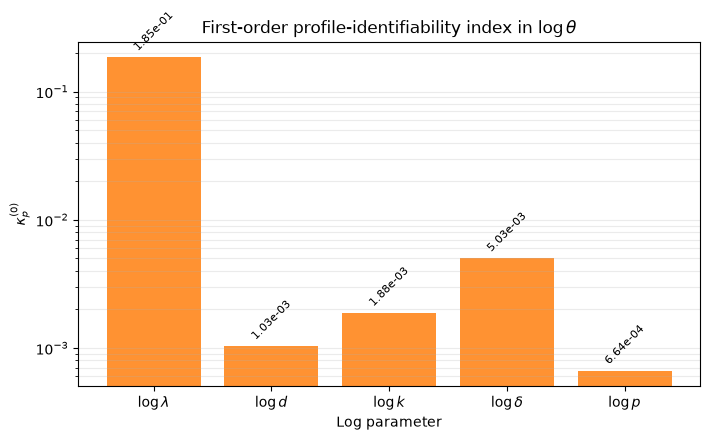

In [13]:
kappa_logtheta = compute_profile_kappa0(
    J_logtheta, FREE_LOG_PARAM_TXT,
    KAPPA_NUISANCE_SINGULAR_VALUE_THRESHOLD,
    KAPPA_A0_CONDITION_LIMIT)
kappa0_logtheta = kappa_logtheta['kappa0'].copy()
profile_directions_logtheta = kappa_logtheta['profile_directions']
kappa_logtheta_nuisance_ranks = kappa_logtheta['nuisance_ranks']
kappa_logtheta_nuisance_algebraic_ranks = (
    kappa_logtheta['nuisance_algebraic_ranks'])
kappa_logtheta_nuisance_resolved_ranks = (
    kappa_logtheta['nuisance_resolved_ranks'])
kappa_logtheta_nuisance_J_condition_numbers = (
    kappa_logtheta['nuisance_J_condition_numbers'])
kappa_logtheta_nuisance_condition_numbers = (
    kappa_logtheta['nuisance_condition_numbers'])
kappa_logtheta_nuisance_resolved_condition_numbers = (
    kappa_logtheta['nuisance_resolved_condition_numbers'])
kappa_logtheta_nuisance_effective_thresholds = (
    kappa_logtheta['nuisance_effective_singular_value_thresholds'])
kappa_logtheta_selection_matrices = (
    kappa_logtheta['selection_matrices'])
kappa_logtheta_nuisance_coefficients = (
    kappa_logtheta['nuisance_coefficients'])

print('First-order kappa indicators in log-parameter coordinates')
print('absolute singular-value threshold =',
      KAPPA_NUISANCE_SINGULAR_VALUE_THRESHOLD)
print('maximum retained cond(A0) =', KAPPA_A0_CONDITION_LIMIT)
print(
    f"{'parameter':>12s} {'kappa^(0)':>13s} "
    f"{'rank alg/eff':>13s} {'cond(A0)':>12s} "
    f"{'cond(A0r)':>12s} {'s_cut':>11s}")
for j, name in enumerate(FREE_LOG_PARAM_TXT):
    print(
        f'{name:>12s} {kappa0_logtheta[j]:13.6e} '
        f'{kappa_logtheta_nuisance_algebraic_ranks[j]:4d}/'
        f'{kappa_logtheta_nuisance_resolved_ranks[j]:<8d} '
        f'{kappa_logtheta_nuisance_condition_numbers[j]:12.4e} '
        f'{kappa_logtheta_nuisance_resolved_condition_numbers[j]:12.4e} '
        f'{kappa_logtheta_nuisance_effective_thresholds[j]:11.3e}')
if np.any(kappa_logtheta_nuisance_resolved_ranks < N_FREE-1):
    print('NOTICE: condition/threshold adjustment discarded at least '
          'one nuisance singular direction for some parameters.')
else:
    print('No nuisance direction is discarded at the current '
          'condition and singular-value thresholds.')

x_kappa_log = np.arange(N_FREE)
shown_kappa0 = np.maximum(
    kappa0_logtheta, np.finfo(float).tiny)
fig, ax = plt.subplots(figsize=(7.2, 4.5))
bars = ax.bar(
    x_kappa_log, shown_kappa0,
    color='tab:orange', alpha=0.85)
ax.set_yscale('log')
ax.set_xticks(x_kappa_log)
ax.set_xticklabels(FREE_LOG_PARAM_TEX)
ax.set_xlabel('Log parameter')
ax.set_ylabel(r'$\kappa_p^{(0)}$')
ax.set_title(
    r'First-order profile-identifiability index in $\log\theta$')
ax.grid(axis='y', which='both', alpha=0.25)
ax.bar_label(
    bars, labels=[f'{value:.2e}' for value in kappa0_logtheta],
    padding=3, fontsize=8, rotation=45)
fig.tight_layout()
plt.show()

Theorem-3 profile data-sensitivity comparison
without residual: K = F = J_eta.T @ J_eta
with residual:    K = F + C_eta
 parameter     kappa(F)     ||g(F)||     ratio(F)     kappa(K)     ||g(K)||     ratio(K)
log(lambda)   1.8526e-01   4.3042e-01   2.3233e+00   2.3634e-01   4.3523e-01   1.8415e+00
    log(d)   1.0341e-03   3.2158e-02   3.1097e+01   1.2579e-03   3.3000e-02   2.6233e+01
    log(k)   1.8823e-03   4.3385e-02   2.3049e+01   2.3049e-03   4.4496e-02   1.9305e+01
log(delta)   5.0272e-03   7.0903e-02   1.4104e+01   6.0273e-03   7.2824e-02   1.2082e+01
    log(p)   6.6401e-04   2.5768e-02   3.8807e+01   8.1357e-04   2.6428e-02   3.2484e+01
max no-residual |kappa-||g||^2| = 8.433809206565002e-13
PSD without/with residual = True True
compatibility without residual = [ True  True  True  True  True]
compatibility with residual = [ True  True  True  True  True]
positive kappa without residual = [ True  True  True  True  True]
positive kappa with residual = [ True  True  True  True  T

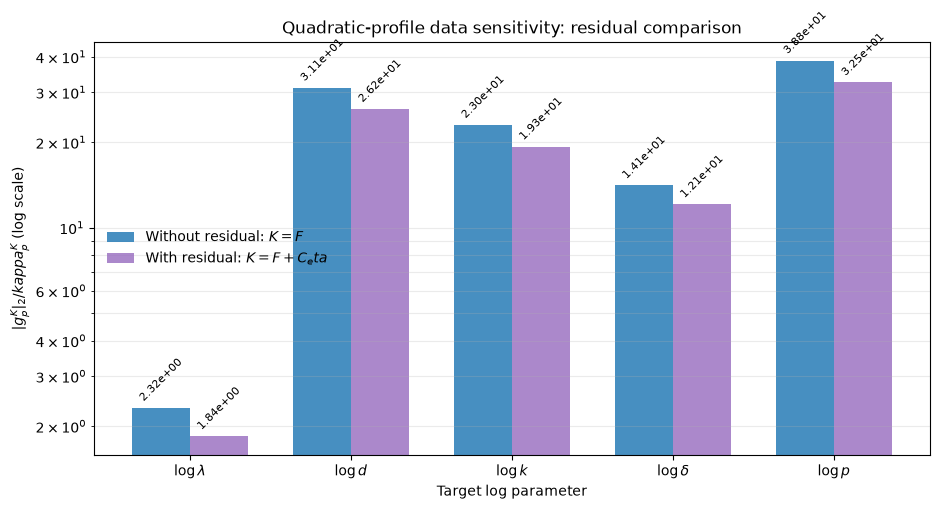

In [14]:
# Theorem 3, Eqs. (1.58)--(1.67): compare the exact
# quadratic-profile data sensitivity with and without residual correction.
PROFILE_SENSITIVITY_REL_TOL = 1e-10
PROFILE_SENSITIVITY_COMPATIBILITY_REL_TOL = 1e-8


def compute_quadratic_profile_sensitivity(
        J, curvature, parameter_names, relative_tolerance,
        compatibility_relative_tolerance):
    J = np.asarray(J, dtype=float)
    curvature = np.asarray(curvature, dtype=float)
    curvature = 0.5*(curvature+curvature.T)
    n_obs, n_param = J.shape
    if curvature.shape != (n_param, n_param):
        raise ValueError('curvature must have shape (n_param, n_param)')
    if len(parameter_names) != n_param:
        raise ValueError('parameter_names must match J columns')
    if relative_tolerance <= 0.0:
        raise ValueError('relative_tolerance must be positive')

    curvature_eigenvalues = np.linalg.eigvalsh(curvature)
    curvature_scale = max(
        float(np.linalg.norm(curvature, 2)),
        np.finfo(float).tiny)
    curvature_tolerance = relative_tolerance*curvature_scale
    curvature_psd = bool(np.all(
        curvature_eigenvalues >= -curvature_tolerance))

    kappa = np.full(n_param, np.nan)
    g_vectors = np.full((n_obs, n_param), np.nan)
    g_norm = np.full(n_param, np.nan)
    coefficient = np.full(n_param, np.nan)
    nuisance_ranks = np.zeros(n_param, dtype=int)
    compatibility_residual = np.full(n_param, np.nan)
    mixed_range_residual = np.full(n_param, np.nan)
    compatibility_holds = np.zeros(n_param, dtype=bool)
    mixed_block_in_range = np.zeros(n_param, dtype=bool)
    positive_kappa = np.zeros(n_param, dtype=bool)

    for p_idx in range(n_param):
        nuisance_idx = np.delete(np.arange(n_param), p_idx)
        J_nuisance = J[:, nuisance_idx]
        j_p = J[:, p_idx]
        K_nuisance = curvature[np.ix_(nuisance_idx, nuisance_idx)]
        k_p = curvature[nuisance_idx, p_idx]
        K_pp = float(curvature[p_idx, p_idx])

        values, vectors = np.linalg.eigh(
            0.5*(K_nuisance+K_nuisance.T))
        nuisance_scale = max(
            float(np.max(np.abs(values))), np.finfo(float).tiny)
        resolved = values > relative_tolerance*nuisance_scale
        nuisance_ranks[p_idx] = int(np.count_nonzero(resolved))
        V_resolved = vectors[:, resolved]
        if V_resolved.shape[1]:
            K_nuisance_pinv = (
                V_resolved @ np.diag(1.0/values[resolved])
                @ V_resolved.T)
            range_projector = V_resolved @ V_resolved.T
        else:
            K_nuisance_pinv = np.zeros_like(K_nuisance)
            range_projector = np.zeros_like(K_nuisance)
        null_projector = np.eye(n_param-1)-range_projector

        compatibility_residual[p_idx] = (
            np.linalg.norm(J_nuisance @ null_projector, 2)
            / max(np.linalg.norm(J_nuisance, 2),
                  np.finfo(float).tiny))
        mixed_range_residual[p_idx] = (
            np.linalg.norm(null_projector @ k_p)
            / max(np.linalg.norm(k_p), np.finfo(float).tiny))
        compatibility_holds[p_idx] = bool(
            compatibility_residual[p_idx]
            <= compatibility_relative_tolerance)
        mixed_block_in_range[p_idx] = bool(
            mixed_range_residual[p_idx]
            <= compatibility_relative_tolerance)

        nuisance_response = K_nuisance_pinv @ k_p
        kappa_value = float(K_pp-k_p @ nuisance_response)
        if -curvature_tolerance <= kappa_value < 0.0:
            kappa_value = 0.0
        g_p = j_p-J_nuisance @ nuisance_response
        kappa[p_idx] = kappa_value
        g_vectors[:, p_idx] = g_p
        g_norm[p_idx] = np.linalg.norm(g_p)
        positive_kappa[p_idx] = bool(
            kappa_value > curvature_tolerance)
        if (curvature_psd and compatibility_holds[p_idx]
                and mixed_block_in_range[p_idx]
                and positive_kappa[p_idx]):
            coefficient[p_idx] = g_norm[p_idx]/kappa_value

    return {
        'parameter_names': list(parameter_names),
        'curvature': curvature,
        'curvature_eigenvalues': curvature_eigenvalues,
        'curvature_psd': curvature_psd,
        'curvature_tolerance': curvature_tolerance,
        'kappa_K': kappa,
        'g_K_columns': g_vectors,
        'g_K_norm': g_norm,
        'g_norm_over_kappa': coefficient,
        'nuisance_ranks': nuisance_ranks,
        'compatibility_relative_residual': compatibility_residual,
        'compatibility_holds': compatibility_holds,
        'mixed_block_range_relative_residual': mixed_range_residual,
        'mixed_block_in_range': mixed_block_in_range,
        'positive_kappa': positive_kappa,
    }


profile_sensitivity_no_residual = (
    compute_quadratic_profile_sensitivity(
        J_logtheta, k_matrix_gauss_newton, FREE_LOG_PARAM_TXT,
        PROFILE_SENSITIVITY_REL_TOL,
        PROFILE_SENSITIVITY_COMPATIBILITY_REL_TOL))
profile_sensitivity_with_residual = (
    compute_quadratic_profile_sensitivity(
        J_logtheta, K_eta, FREE_LOG_PARAM_TXT,
        PROFILE_SENSITIVITY_REL_TOL,
        PROFILE_SENSITIVITY_COMPATIBILITY_REL_TOL))

profile_no_residual_ratio = profile_sensitivity_no_residual[
    'g_norm_over_kappa']
profile_with_residual_ratio = profile_sensitivity_with_residual[
    'g_norm_over_kappa']
profile_sensitivity_comparison_results = {
    'coordinate': 'eta = log(theta_free)',
    'parameter_names': np.asarray(FREE_PARAM_TXT, dtype='U'),
    'without_residual': profile_sensitivity_no_residual,
    'with_residual': profile_sensitivity_with_residual,
}

print('Theorem-3 profile data-sensitivity comparison')
print('without residual: K = F = J_eta.T @ J_eta')
print('with residual:    K = F + C_eta')
print(
    f"{'parameter':>10s} {'kappa(F)':>12s} {'||g(F)||':>12s} "
    f"{'ratio(F)':>12s} {'kappa(K)':>12s} {'||g(K)||':>12s} "
    f"{'ratio(K)':>12s}")
for p_idx, name in enumerate(FREE_LOG_PARAM_TXT):
    print(
        f'{name:>10s} '
        f"{profile_sensitivity_no_residual['kappa_K'][p_idx]:12.4e} "
        f"{profile_sensitivity_no_residual['g_K_norm'][p_idx]:12.4e} "
        f'{profile_no_residual_ratio[p_idx]:12.4e} '
        f"{profile_sensitivity_with_residual['kappa_K'][p_idx]:12.4e} "
        f"{profile_sensitivity_with_residual['g_K_norm'][p_idx]:12.4e} "
        f'{profile_with_residual_ratio[p_idx]:12.4e}')

no_residual_identity_error = np.abs(
    profile_sensitivity_no_residual['kappa_K']
    - profile_sensitivity_no_residual['g_K_norm']**2)
print('max no-residual |kappa-||g||^2| =',
      np.nanmax(no_residual_identity_error))
print('PSD without/with residual =',
      profile_sensitivity_no_residual['curvature_psd'],
      profile_sensitivity_with_residual['curvature_psd'])
print('compatibility without residual =',
      profile_sensitivity_no_residual['compatibility_holds'])
print('compatibility with residual =',
      profile_sensitivity_with_residual['compatibility_holds'])
print('positive kappa without residual =',
      profile_sensitivity_no_residual['positive_kappa'])
print('positive kappa with residual =',
      profile_sensitivity_with_residual['positive_kappa'])

profile_comparison_x = np.arange(N_FREE)
profile_comparison_width = 0.36
fig, ax = plt.subplots(figsize=(9.5, 5.2))
bars_no_residual = ax.bar(
    profile_comparison_x-profile_comparison_width/2.0,
    profile_no_residual_ratio,
    width=profile_comparison_width, color='tab:blue', alpha=0.82,
    label=r'Without residual: $K=F$')
bars_with_residual = ax.bar(
    profile_comparison_x+profile_comparison_width/2.0,
    profile_with_residual_ratio,
    width=profile_comparison_width, color='tab:purple', alpha=0.78,
    label=r'With residual: $K=F+C_eta$')
ax.set_yscale('log')
ax.set_xticks(profile_comparison_x)
ax.set_xticklabels(FREE_LOG_PARAM_TEX)
ax.set_xlabel('Target log parameter')
ax.set_ylabel(r'$|g_p^K|_2/kappa_p^K$ (log scale)')
ax.set_title('Quadratic-profile data sensitivity: residual comparison')
ax.grid(axis='y', which='both', alpha=0.25)
ax.bar_label(
    bars_no_residual,
    labels=[f'{value:.2e}' if np.isfinite(value) else 'invalid'
            for value in profile_no_residual_ratio],
    padding=3, fontsize=8, rotation=45)
ax.bar_label(
    bars_with_residual,
    labels=[f'{value:.2e}' if np.isfinite(value) else 'invalid'
            for value in profile_with_residual_ratio],
    padding=3, fontsize=8, rotation=45)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 8b. Residual-Hessian correction to coordinate Lipschitz stability

Following Eqs. (1.69)--(1.81) of `M3as_Manuscript.pdf`, compare the Gauss--Newton matrix $F_\eta=J_\eta^TJ_\eta$ with the residual-corrected matrix $K_\eta=F_\eta+C_\eta$ after nuisance-parameter reoptimization. For each target coordinate $p$, Part 8 provides

$$L_p(M_\eta)=\frac{\lVert g_p(M_\eta)\rVert_2}{\kappa_p(M_\eta)},\qquad M_\eta\in\{F_\eta,K_\eta\}.$$

The total residual-Hessian correction and its force--curvature factors are

$$R_p^{RH}=\frac{L_p(K_\eta)}{L_p(F_\eta)}=R_{p,\mathrm{resp}}^{RH}R_{p,\mathrm{curv}}^{RH},\qquad R_{p,\mathrm{resp}}^{RH}=\frac{\lVert g_p^K\rVert_2}{\lVert g_p^F\rVert_2},\qquad R_{p,\mathrm{curv}}^{RH}=\frac{\kappa_p^F}{\kappa_p^K}.$$

The requested logarithmic index is

$$I_p^{RH}=\log R_p^{RH}=I_{p,\mathrm{resp}}^{RH}+I_{p,\mathrm{curv}}^{RH},\qquad I_{p,\mathrm{resp}}^{RH}=\log\frac{\lVert g_p^K\rVert_2}{\lVert g_p^F\rVert_2},\qquad I_{p,\mathrm{curv}}^{RH}=-\log\frac{\kappa_p^K}{\kappa_p^F}.$$

$I_p^{RH}<0$ means that the residual Hessian improves coordinate stability, $I_p^{RH}=0$ means no net effect, and $I_p^{RH}>0$ means reduced stability. The code evaluates the index only when the PDF compatibility conditions hold and both profiled curvatures are positive.

Residual-Hessian correction to coordinate Lipschitz stability
M3AS Eqs. (1.76)--(1.78)
   parameter        L(F)        L(K)      R_resp      R_curv        R_RH      I_resp      I_curv        I_RH       interpretation
 log(lambda)  2.3233e+00  1.8415e+00  1.0112e+00  7.8386e-01  7.9262e-01  1.1113e-02 -2.4352e-01 -2.3241e-01   improved stability
      log(d)  3.1097e+01  2.6233e+01  1.0262e+00  8.2207e-01  8.4361e-01  2.5866e-02 -1.9593e-01 -1.7007e-01   improved stability
      log(k)  2.3049e+01  1.9305e+01  1.0256e+00  8.1664e-01  8.3756e-01  2.5295e-02 -2.0256e-01 -1.7726e-01   improved stability
  log(delta)  1.4104e+01  1.2082e+01  1.0271e+00  8.3408e-01  8.5668e-01  2.6729e-02 -1.8142e-01 -1.5469e-01   improved stability
      log(p)  3.8807e+01  3.2484e+01  1.0256e+00  8.1617e-01  8.3706e-01  2.5275e-02 -2.0313e-01 -1.7786e-01   improved stability
max |R_RH-R_resp*R_curv| = 1.1102230246251565e-16
max |I_RH-I_resp-I_curv| = 1.1102230246251565e-16


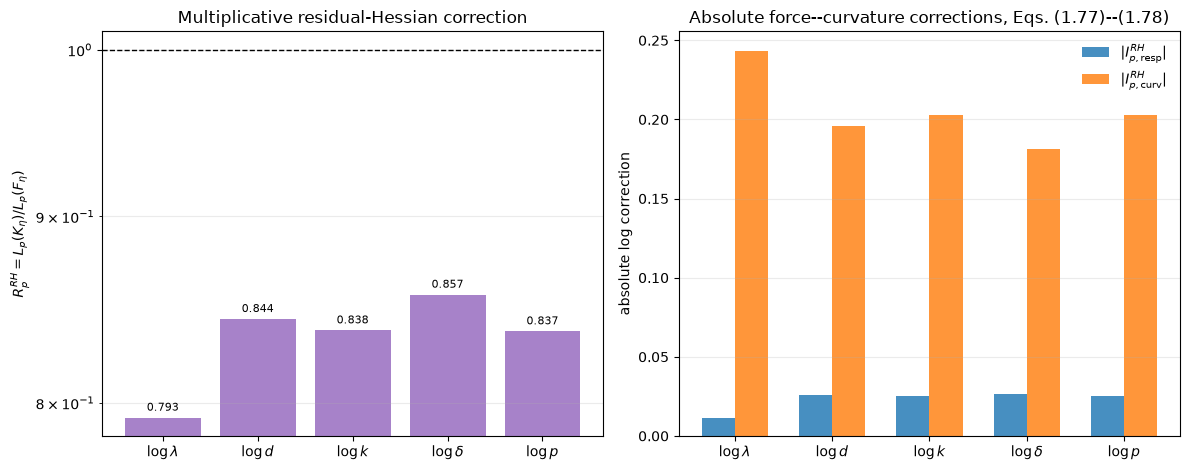

In [15]:
# M3AS Eqs. (1.76)--(1.78): residual-Hessian correction index.
RH_LOG_ZERO_TOL = 1e-10

rh_kappa_F = profile_sensitivity_no_residual['kappa_K'].copy()
rh_kappa_K = profile_sensitivity_with_residual['kappa_K'].copy()
rh_g_norm_F = profile_sensitivity_no_residual['g_K_norm'].copy()
rh_g_norm_K = profile_sensitivity_with_residual['g_K_norm'].copy()
rh_L_F = profile_sensitivity_no_residual['g_norm_over_kappa'].copy()
rh_L_K = profile_sensitivity_with_residual['g_norm_over_kappa'].copy()

rh_valid = (
    profile_sensitivity_no_residual['curvature_psd']
    & profile_sensitivity_with_residual['curvature_psd']
    & profile_sensitivity_no_residual['compatibility_holds']
    & profile_sensitivity_with_residual['compatibility_holds']
    & profile_sensitivity_no_residual['mixed_block_in_range']
    & profile_sensitivity_with_residual['mixed_block_in_range']
    & profile_sensitivity_no_residual['positive_kappa']
    & profile_sensitivity_with_residual['positive_kappa']
    & np.isfinite(rh_L_F) & np.isfinite(rh_L_K)
    & (rh_g_norm_F > 0.0) & (rh_g_norm_K > 0.0))

rh_response_ratio = np.full(N_FREE, np.nan)
rh_curvature_ratio = np.full(N_FREE, np.nan)
rh_total_ratio = np.full(N_FREE, np.nan)
rh_I_response = np.full(N_FREE, np.nan)
rh_I_curvature = np.full(N_FREE, np.nan)
rh_I_total = np.full(N_FREE, np.nan)

rh_response_ratio[rh_valid] = (
    rh_g_norm_K[rh_valid]/rh_g_norm_F[rh_valid])
rh_curvature_ratio[rh_valid] = (
    rh_kappa_F[rh_valid]/rh_kappa_K[rh_valid])
rh_total_ratio[rh_valid] = rh_L_K[rh_valid]/rh_L_F[rh_valid]
rh_I_response[rh_valid] = np.log(rh_response_ratio[rh_valid])
rh_I_curvature[rh_valid] = np.log(rh_curvature_ratio[rh_valid])
rh_I_total[rh_valid] = np.log(rh_total_ratio[rh_valid])

rh_ratio_factorization_error = np.full(N_FREE, np.nan)
rh_log_decomposition_error = np.full(N_FREE, np.nan)
rh_ratio_factorization_error[rh_valid] = np.abs(
    rh_total_ratio[rh_valid]
    - rh_response_ratio[rh_valid]*rh_curvature_ratio[rh_valid])
rh_log_decomposition_error[rh_valid] = np.abs(
    rh_I_total[rh_valid]
    - rh_I_response[rh_valid]-rh_I_curvature[rh_valid])

rh_interpretation = np.full(N_FREE, 'invalid', dtype=object)
rh_interpretation[rh_valid & (rh_I_total < -RH_LOG_ZERO_TOL)] = (
    'improved stability')
rh_interpretation[rh_valid & (np.abs(rh_I_total) <= RH_LOG_ZERO_TOL)] = (
    'no net effect')
rh_interpretation[rh_valid & (rh_I_total > RH_LOG_ZERO_TOL)] = (
    'reduced stability')

residual_hessian_coordinate_stability = {
    'coordinate': 'eta = log(theta_free)',
    'parameter_names': np.asarray(FREE_PARAM_TXT, dtype='U'),
    'valid': rh_valid.copy(),
    'kappa_F': rh_kappa_F, 'kappa_K': rh_kappa_K,
    'g_norm_F': rh_g_norm_F, 'g_norm_K': rh_g_norm_K,
    'L_F': rh_L_F, 'L_K': rh_L_K,
    'R_RH_response': rh_response_ratio,
    'R_RH_curvature': rh_curvature_ratio,
    'R_RH': rh_total_ratio,
    'I_RH_response': rh_I_response,
    'I_RH_curvature': rh_I_curvature,
    'I_RH': rh_I_total,
    'interpretation': np.asarray(rh_interpretation, dtype='U'),
    'ratio_factorization_error': rh_ratio_factorization_error,
    'log_decomposition_error': rh_log_decomposition_error,
}

print('Residual-Hessian correction to coordinate Lipschitz stability')
print('M3AS Eqs. (1.76)--(1.78)')
print(
    f"{'parameter':>12s} {'L(F)':>11s} {'L(K)':>11s} "
    f"{'R_resp':>11s} {'R_curv':>11s} {'R_RH':>11s} "
    f"{'I_resp':>11s} {'I_curv':>11s} {'I_RH':>11s} "
    f"{'interpretation':>20s}")
for p_idx, name in enumerate(FREE_LOG_PARAM_TXT):
    print(
        f'{name:>12s} {rh_L_F[p_idx]:11.4e} '
        f'{rh_L_K[p_idx]:11.4e} '
        f'{rh_response_ratio[p_idx]:11.4e} '
        f'{rh_curvature_ratio[p_idx]:11.4e} '
        f'{rh_total_ratio[p_idx]:11.4e} '
        f'{rh_I_response[p_idx]:11.4e} '
        f'{rh_I_curvature[p_idx]:11.4e} '
        f'{rh_I_total[p_idx]:11.4e} '
        f'{rh_interpretation[p_idx]:>20s}')
if np.any(rh_valid):
    print('max |R_RH-R_resp*R_curv| =',
          np.nanmax(rh_ratio_factorization_error))
    print('max |I_RH-I_resp-I_curv| =',
          np.nanmax(rh_log_decomposition_error))
if not np.all(rh_valid):
    print('WARNING: I_RH is undefined for invalid coordinates:',
          np.asarray(FREE_LOG_PARAM_TXT)[~rh_valid])

rh_x = np.arange(N_FREE)
rh_width = 0.34
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.8))
bars_ratio = axes[0].bar(
    rh_x, rh_total_ratio, color='tab:purple', alpha=0.82)
axes[0].set_yscale('log')
axes[0].axhline(1.0, color='black', lw=1.0, ls='--')
axes[0].set_xticks(rh_x)
axes[0].set_xticklabels(FREE_LOG_PARAM_TEX)
axes[0].set_ylabel(r'$R_p^{RH}=L_p(K_\eta)/L_p(F_\eta)$')
axes[0].set_title('Multiplicative residual-Hessian correction')
axes[0].grid(axis='y', which='both', alpha=0.25)
axes[0].bar_label(
    bars_ratio, labels=[f'{value:.3f}' for value in rh_total_ratio],
    padding=3, fontsize=8)

axes[1].bar(
    rh_x-rh_width/2.0, np.abs(rh_I_response), width=rh_width,
    color='tab:blue', alpha=0.82,
    label=r'$|I_{p,\mathrm{resp}}^{RH}|$')
axes[1].bar(
    rh_x+rh_width/2.0, np.abs(rh_I_curvature), width=rh_width,
    color='tab:orange', alpha=0.82,
    label=r'$|I_{p,\mathrm{curv}}^{RH}|$')
axes[1].set_xticks(rh_x)
axes[1].set_xticklabels(FREE_LOG_PARAM_TEX)
axes[1].set_ylabel('absolute log correction')
axes[1].set_title('Absolute force--curvature corrections, Eqs. (1.77)--(1.78)')
axes[1].grid(axis='y', alpha=0.25)
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

In [16]:
# Theorem 4, Eqs. (1.79)--(1.83): global-to-coordinate bounds.
THEOREM4_PD_RELATIVE_TOLERANCE = 1e-12
THEOREM4_BOUND_RELATIVE_TOLERANCE = 1e-9

if THEOREM4_PD_RELATIVE_TOLERANCE <= 0.0:
    raise ValueError(
        'THEOREM4_PD_RELATIVE_TOLERANCE must be positive')
if THEOREM4_BOUND_RELATIVE_TOLERANCE <= 0.0:
    raise ValueError(
        'THEOREM4_BOUND_RELATIVE_TOLERANCE must be positive')

theorem4_F = 0.5*(k_matrix_gauss_newton+k_matrix_gauss_newton.T)
theorem4_C = 0.5*(
    k_matrix_residual_curvature+k_matrix_residual_curvature.T)
theorem4_K = 0.5*(K_eta+K_eta.T)
theorem4_C_reconstruction_error = float(np.linalg.norm(
    theorem4_C-(theorem4_K-theorem4_F), 2))

(theorem4_F_eigenvalues,
 theorem4_F_eigenvectors) = np.linalg.eigh(theorem4_F)
theorem4_K_eigenvalues = np.linalg.eigvalsh(theorem4_K)
theorem4_F_scale = max(
    float(np.max(np.abs(theorem4_F_eigenvalues))),
    np.finfo(float).tiny)
theorem4_K_scale = max(
    float(np.max(np.abs(theorem4_K_eigenvalues))),
    np.finfo(float).tiny)
theorem4_F_tolerance = (
    THEOREM4_PD_RELATIVE_TOLERANCE*theorem4_F_scale)
theorem4_K_tolerance = (
    THEOREM4_PD_RELATIVE_TOLERANCE*theorem4_K_scale)
theorem4_F_positive_definite = bool(
    theorem4_F_eigenvalues[0] > theorem4_F_tolerance)
theorem4_K_positive_definite = bool(
    theorem4_K_eigenvalues[0] > theorem4_K_tolerance)
if not theorem4_F_positive_definite:
    raise ValueError(
        'Theorem 4 requires F_eta to be positive definite; '
        f'lambda_min(F_eta)={theorem4_F_eigenvalues[0]:.6e}, '
        f'tolerance={theorem4_F_tolerance:.6e}.')
if not theorem4_K_positive_definite:
    raise ValueError(
        'Theorem 4 requires K_eta to be positive definite; '
        f'lambda_min(K_eta)={theorem4_K_eigenvalues[0]:.6e}, '
        f'tolerance={theorem4_K_tolerance:.6e}.')

theorem4_F_inverse_sqrt = (
    theorem4_F_eigenvectors
    @ np.diag(1.0/np.sqrt(theorem4_F_eigenvalues))
    @ theorem4_F_eigenvectors.T)
theorem4_F_inverse = theorem4_F_inverse_sqrt @ theorem4_F_inverse_sqrt
theorem4_B = (
    theorem4_F_inverse_sqrt @ theorem4_C
    @ theorem4_F_inverse_sqrt)
theorem4_B = 0.5*(theorem4_B+theorem4_B.T)
theorem4_B_eigenvalues = np.linalg.eigvalsh(theorem4_B)
theorem4_rho = float(np.max(np.abs(theorem4_B_eigenvalues)))
theorem4_A = np.eye(N_FREE)+theorem4_B
theorem4_A = 0.5*(theorem4_A+theorem4_A.T)
(theorem4_A_eigenvalues,
 theorem4_A_eigenvectors) = np.linalg.eigh(theorem4_A)
theorem4_alpha = float(theorem4_A_eigenvalues[0])
theorem4_beta = float(theorem4_A_eigenvalues[-1])
if theorem4_alpha <= 0.0:
    raise ValueError(
        'A_eta is not positive definite, contrary to the K_eta '
        'positive-definiteness assumption.')
theorem4_A_inverse = (
    theorem4_A_eigenvectors
    @ np.diag(1.0/theorem4_A_eigenvalues)
    @ theorem4_A_eigenvectors.T)
theorem4_A_inverse_squared = theorem4_A_inverse @ theorem4_A_inverse

# Columns are the normalized coordinate vectors u_p in Eq. (1.79).
theorem4_coordinate_denominator = np.sqrt(
    np.diag(theorem4_F_inverse))
theorem4_u = (
    theorem4_F_inverse_sqrt
    / theorem4_coordinate_denominator[None, :])
theorem4_u_norm_error = float(np.max(np.abs(
    np.sum(theorem4_u**2, axis=0)-1.0)))
theorem4_u_A_inverse_u = np.einsum(
    'ip,ip->p', theorem4_u, theorem4_A_inverse @ theorem4_u)
theorem4_u_A_inverse_squared_u = np.einsum(
    'ip,ip->p', theorem4_u,
    theorem4_A_inverse_squared @ theorem4_u)
theorem4_R_RH = np.sqrt(theorem4_u_A_inverse_squared_u)
theorem4_R_RH_curvature = theorem4_u_A_inverse_u
theorem4_R_RH_response = (
    np.sqrt(theorem4_u_A_inverse_squared_u)
    / theorem4_u_A_inverse_u)

# Eq. (1.81): universal bounds based on alpha_eta and beta_eta.
theorem4_global_bounds = {
    'R_RH': (1.0/theorem4_beta, 1.0/theorem4_alpha),
    'R_RH_curvature': (
        1.0/theorem4_beta, 1.0/theorem4_alpha),
    'R_RH_response': (
        1.0,
        (theorem4_alpha+theorem4_beta)
        /(2.0*np.sqrt(theorem4_alpha*theorem4_beta))),
}

# Eqs. (1.82)--(1.83): rho-dependent bounds.
if theorem4_rho < 1.0:
    theorem4_rho_regime = '0 <= rho < 1: Eq. (1.82)'
    theorem4_rho_bounds = {
        'R_RH': (1.0/(1.0+theorem4_rho),
                 1.0/(1.0-theorem4_rho)),
        'R_RH_curvature': (1.0/(1.0+theorem4_rho),
                           1.0/(1.0-theorem4_rho)),
        'R_RH_response': (
            1.0, 1.0/np.sqrt(1.0-theorem4_rho**2)),
    }
elif theorem4_rho > 1.0:
    theorem4_rho_regime = 'rho > 1: Eq. (1.83)'
    theorem4_rho_bounds = {
        'R_RH': (1.0/(1.0+theorem4_rho),
                 1.0/theorem4_alpha),
        'R_RH_curvature': (1.0/(1.0+theorem4_rho),
                           1.0/theorem4_alpha),
        'R_RH_response': (
            1.0,
            (theorem4_alpha+1.0+theorem4_rho)
            /(2.0*np.sqrt(
                theorem4_alpha*(1.0+theorem4_rho)))),
    }
else:
    theorem4_rho_regime = 'rho = 1: only Eq. (1.81) applies'
    theorem4_rho_bounds = None

def theorem4_values_within_bounds(values, bounds):
    lower, upper = bounds
    scale = np.maximum(
        1.0, np.maximum(np.abs(lower), np.abs(upper)))
    slack = THEOREM4_BOUND_RELATIVE_TOLERANCE*scale
    return (values >= lower-slack) & (values <= upper+slack)

theorem4_exact_factors = {
    'R_RH': theorem4_R_RH,
    'R_RH_curvature': theorem4_R_RH_curvature,
    'R_RH_response': theorem4_R_RH_response,
}
theorem4_global_checks = {
    key: theorem4_values_within_bounds(
        theorem4_exact_factors[key], theorem4_global_bounds[key])
    for key in theorem4_exact_factors
}
theorem4_rho_checks = (
    {key: theorem4_values_within_bounds(
        theorem4_exact_factors[key], theorem4_rho_bounds[key])
     for key in theorem4_exact_factors}
    if theorem4_rho_bounds is not None else None)

def theorem4_induced_coordinate_bounds(factor_bounds):
    # Convert factor bounds into p-specific bounds for L(K),
    # kappa(K), and ||g(K)||. Each returned array is N_FREE x 2.
    total_lower, total_upper = factor_bounds['R_RH']
    curvature_lower, curvature_upper = (
        factor_bounds['R_RH_curvature'])
    response_lower, response_upper = factor_bounds['R_RH_response']
    return {
        'L_K': np.column_stack([
            rh_L_F*total_lower, rh_L_F*total_upper]),
        'kappa_K': np.column_stack([
            rh_kappa_F/curvature_upper,
            rh_kappa_F/curvature_lower]),
        'g_norm_K': np.column_stack([
            rh_g_norm_F*response_lower,
            rh_g_norm_F*response_upper]),
    }

theorem4_coordinate_bounds_eq_1_81 = (
    theorem4_induced_coordinate_bounds(theorem4_global_bounds))
theorem4_coordinate_bounds_rho = (
    theorem4_induced_coordinate_bounds(theorem4_rho_bounds)
    if theorem4_rho_bounds is not None else None)
theorem4_selected_factor_bounds = (
    theorem4_rho_bounds
    if theorem4_rho_bounds is not None else theorem4_global_bounds)
theorem4_coordinate_bounds = theorem4_induced_coordinate_bounds(
    theorem4_selected_factor_bounds)
theorem4_coordinate_actual = {
    'L_K': rh_L_K,
    'kappa_K': rh_kappa_K,
    'g_norm_K': rh_g_norm_K,
}
theorem4_coordinate_bound_checks = {
    key: theorem4_values_within_bounds(
        theorem4_coordinate_actual[key],
        (theorem4_coordinate_bounds[key][:, 0],
         theorem4_coordinate_bounds[key][:, 1]))
    for key in theorem4_coordinate_actual
}
theorem4_beta_rho_identity_error = (
    abs(theorem4_beta-(1.0+theorem4_rho))
    if theorem4_rho > 1.0 else np.nan)

# Independent consistency check against the Part 8b factors.
theorem4_part8b_errors = {
    'R_RH': np.abs(theorem4_R_RH-rh_total_ratio),
    'R_RH_curvature': np.abs(
        theorem4_R_RH_curvature-rh_curvature_ratio),
    'R_RH_response': np.abs(
        theorem4_R_RH_response-rh_response_ratio),
}

theorem4_residual_hessian_bounds = {
    'coordinate': 'eta = log(theta_free)',
    'parameter_names': np.asarray(FREE_PARAM_TXT, dtype='U'),
    'F_eigenvalues': theorem4_F_eigenvalues,
    'K_eigenvalues': theorem4_K_eigenvalues,
    'F_positive_definite': theorem4_F_positive_definite,
    'K_positive_definite': theorem4_K_positive_definite,
    'B_eta': theorem4_B, 'B_eigenvalues': theorem4_B_eigenvalues,
    'rho': theorem4_rho, 'A_eta': theorem4_A,
    'alpha': theorem4_alpha, 'beta': theorem4_beta,
    'u': theorem4_u, 'exact_factors': theorem4_exact_factors,
    'global_bounds_eq_1_81': theorem4_global_bounds,
    'rho_regime': theorem4_rho_regime,
    'rho_bounds_eq_1_82_or_1_83': theorem4_rho_bounds,
    'coordinate_bounds_eq_1_81': (
        theorem4_coordinate_bounds_eq_1_81),
    'coordinate_bounds_rho': theorem4_coordinate_bounds_rho,
    'coordinate_bounds_selected': theorem4_coordinate_bounds,
    'coordinate_actual': theorem4_coordinate_actual,
    'coordinate_bound_checks': theorem4_coordinate_bound_checks,
    'global_checks': theorem4_global_checks,
    'rho_checks': theorem4_rho_checks,
    'part8b_absolute_errors': theorem4_part8b_errors,
}

print('Theorem 4 global-to-coordinate residual-Hessian bounds')
print('  F_eta positive definite =', theorem4_F_positive_definite)
print('  K_eta positive definite =', theorem4_K_positive_definite)
print('  lambda_min(F_eta) =', theorem4_F_eigenvalues[0])
print('  lambda_min(K_eta) =', theorem4_K_eigenvalues[0])
print('  ||C_eta-(K_eta-F_eta)||_2 =',
      theorem4_C_reconstruction_error)
print('  rho =', theorem4_rho)
print('  alpha_eta =', theorem4_alpha)
print('  beta_eta =', theorem4_beta)
print('  rho regime =', theorem4_rho_regime)
if theorem4_rho > 1.0:
    print('  |beta_eta-(1+rho)| =',
          theorem4_beta_rho_identity_error)
print('  max ||u_p||_2 normalization error =', theorem4_u_norm_error)

print('\nEq. (1.81) factor-bound constants')
for key, bounds in theorem4_global_bounds.items():
    print(f'  {key}: [{bounds[0]:.6e}, {bounds[1]:.6e}]')
if theorem4_rho_bounds is not None:
    print('\nRho-dependent bounds:', theorem4_rho_regime)
    for key, bounds in theorem4_rho_bounds.items():
        print(f'  {key}: [{bounds[0]:.6e}, {bounds[1]:.6e}]')

print('\nCoordinate factors and bound checks')
print(
    f"{'parameter':>12s} {'R_RH':>12s} {'R_curv':>12s} "
    f"{'R_resp':>12s} {'Eq1.81':>9s} {'rho-bound':>10s}")
for p_idx, name in enumerate(FREE_LOG_PARAM_TXT):
    global_ok = all(
        theorem4_global_checks[key][p_idx]
        for key in theorem4_exact_factors)
    rho_ok = (
        all(theorem4_rho_checks[key][p_idx]
            for key in theorem4_exact_factors)
        if theorem4_rho_checks is not None else True)
    print(
        f'{name:>12s} {theorem4_R_RH[p_idx]:12.4e} '
        f'{theorem4_R_RH_curvature[p_idx]:12.4e} '
        f'{theorem4_R_RH_response[p_idx]:12.4e} '
        f'{str(global_ok):>9s} {str(rho_ok):>10s}')

print('\nParameter-specific induced bounds')
for key, label in [
        ('L_K', 'L_p(K)'),
        ('kappa_K', 'kappa_p(K)'),
        ('g_norm_K', '||g_p(K)||_2')]:
    print(f'\n  {label}')
    print(
        f"{'parameter':>12s} {'lower':>13s} {'actual':>13s} "
        f"{'upper':>13s} {'inside':>9s}")
    for p_idx, name in enumerate(FREE_LOG_PARAM_TXT):
        lower, upper = theorem4_coordinate_bounds[key][p_idx]
        actual = theorem4_coordinate_actual[key][p_idx]
        inside = theorem4_coordinate_bound_checks[key][p_idx]
        print(
            f'{name:>12s} {lower:13.5e} {actual:13.5e} '
            f'{upper:13.5e} {str(inside):>9s}')

print('\nMaximum absolute discrepancy from Part 8b')
for key, error in theorem4_part8b_errors.items():
    print(f'  {key}: {np.nanmax(error):.6e}')


Theorem 4 global-to-coordinate residual-Hessian bounds
  F_eta positive definite = True
  K_eta positive definite = True
  lambda_min(F_eta) = 0.00031220480545345654
  lambda_min(K_eta) = 0.00038130618983250885
  ||C_eta-(K_eta-F_eta)||_2 = 7.322608509803335e-15
  rho = 0.3966163999221315
  alpha_eta = 0.8600489167400386
  beta_eta = 1.3966163999221315
  rho regime = 0 <= rho < 1: Eq. (1.82)
  max ||u_p||_2 normalization error = 2.220446049250313e-16

Eq. (1.81) factor-bound constants
  R_RH: [7.160162e-01, 1.162725e+00]
  R_RH_curvature: [7.160162e-01, 1.162725e+00]
  R_RH_response: [1.000000e+00, 1.029525e+00]

Rho-dependent bounds: 0 <= rho < 1: Eq. (1.82)
  R_RH: [7.160162e-01, 1.657320e+00]
  R_RH_curvature: [7.160162e-01, 1.657320e+00]
  R_RH_response: [1.000000e+00, 1.089343e+00]

Coordinate factors and bound checks
   parameter         R_RH       R_curv       R_resp    Eq1.81  rho-bound
 log(lambda)   7.9262e-01   7.8386e-01   1.0112e+00      True       True
      log(d)   8.43

### 9a. Parameter credible intervals from the residual-corrected curvature

Following Eqs. (1.69)--(1.90) of *M3as_Manuscript.pdf*, use a prior that is locally uniform in the target coordinate and in the data-informed nuisance directions. A proper Gaussian prior may regularize only the nuisance null space; by Eqs. (1.81)--(1.83), that regularization does not change the coordinate curvature

$$\kappa_p^K=K_{pp}-k_p^T\widetilde K^\dagger k_p.$$

Under $K_\eta\succeq0$, $\ker(\widetilde K)\subseteq\ker(\widetilde J)$, and $\kappa_p^K>0$, the quadratic marginal posterior is

$$u_p=\eta_p-\eta_p^*,\qquad
u_p\mid\widehat h\overset{\mathrm{quad}}\sim
N\!\left(0,\frac{\sigma^2}{\kappa_p^K}\right).$$

Therefore,

$$\operatorname{CrI}_{\eta_p}(1-\alpha)=
\left[\eta_p^*-z_{1-\alpha/2}\frac{\sigma}{\sqrt{\kappa_p^K}},
\ \eta_p^*+z_{1-\alpha/2}\frac{\sigma}{\sqrt{\kappa_p^K}}\right],$$

and the interval for the positive physical parameter is obtained by exponentiating both endpoints. The code uses the residual-corrected $K_\eta$ from Part 6, checks all theorem assumptions coordinate by coordinate, and flags intervals that reach the admissible parameter boundary.

Paper-defined 95.0% parameter credible intervals
posterior sd = sigma/sqrt(kappa_p^K)
 parameter      kappa_K      sd(eta)     eta lower          eta*     eta upper    theta lower    theta upper  compute  theorem   bound
    lambda   2.3634e-01   5.1424e-03 -2.054197e+00 -2.044118e+00 -2.034039e+00   1.281958e-01   1.308062e-01     True     True   False
         d   1.2579e-03   7.0487e-02 -3.871901e+00 -3.733749e+00 -3.595598e+00   2.081875e-02   2.744428e-02     True     True   False
         k   2.3049e-03   5.2073e-02 -8.556048e+00 -8.453986e+00 -8.351924e+00   1.923780e-04   2.359420e-04     True     True   False
     delta   6.0273e-03   3.2202e-02 -1.502786e+00 -1.439671e+00 -1.376557e+00   2.225094e-01   2.524462e-01     True     True   False
         p   8.1357e-04   8.7648e-02  7.229488e+00  7.401276e+00  7.573063e+00   1.379516e+03   1.945088e+03     True     True   False
max relative error in Eq. (1.88) = 4.186907426911595e-10
K_eta PSD = True
compatibility by parameter = [

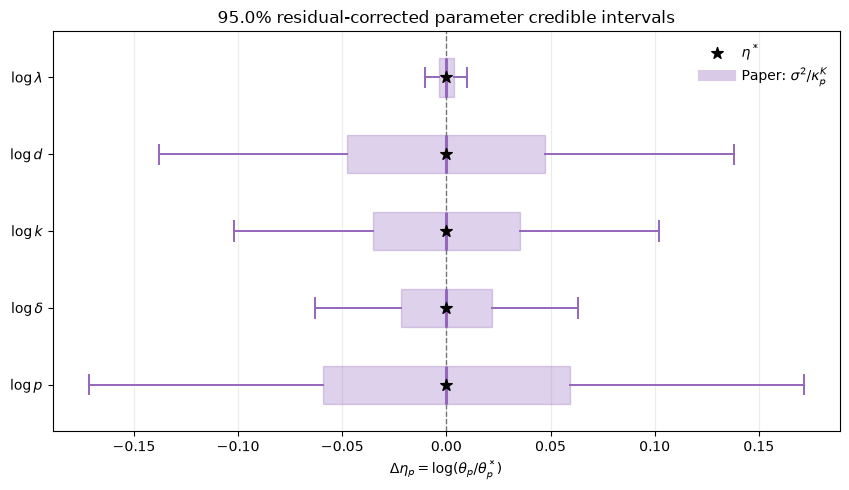

In [17]:
# Independent settings for the paper-defined parameter credible intervals.
PAPER_CI_NOISE_SIGMA = 2.5e-3
PAPER_CI_LEVEL = 0.95
PAPER_CI_EIGENVALUE_REL_TOL = 1e-10
PAPER_CI_COMPATIBILITY_REL_TOL = 1e-8

if not np.isfinite(PAPER_CI_NOISE_SIGMA) or PAPER_CI_NOISE_SIGMA <= 0.0:
    raise ValueError('PAPER_CI_NOISE_SIGMA must be positive')
if not 0.0 < PAPER_CI_LEVEL < 1.0:
    raise ValueError('PAPER_CI_LEVEL must lie strictly between 0 and 1')
if PAPER_CI_EIGENVALUE_REL_TOL <= 0.0:
    raise ValueError('PAPER_CI_EIGENVALUE_REL_TOL must be positive')
if PAPER_CI_COMPATIBILITY_REL_TOL <= 0.0:
    raise ValueError(
        'PAPER_CI_COMPATIBILITY_REL_TOL must be positive')

paper_eta_star = eta_free_new.copy()
paper_theta_star = np.exp(paper_eta_star)
paper_profile_curvature = compute_quadratic_profile_sensitivity(
    J_logtheta, K_eta, FREE_LOG_PARAM_TXT,
    PAPER_CI_EIGENVALUE_REL_TOL,
    PAPER_CI_COMPATIBILITY_REL_TOL)
paper_kappa_K = paper_profile_curvature['kappa_K'].copy()

paper_fit_is_interior = bool(
    not np.any(near_lower_bound | near_upper_bound))
paper_local_minimum_verified = bool(fit_local_minimum_verified)
paper_interval_computable = (
    paper_profile_curvature['curvature_psd']
    & paper_profile_curvature['compatibility_holds']
    & paper_profile_curvature['mixed_block_in_range']
    & paper_profile_curvature['positive_kappa'])
paper_theorem_assumptions_verified = (
    paper_interval_computable
    & paper_fit_is_interior
    & paper_local_minimum_verified)
paper_parameter_sd = np.full(N_FREE, np.nan)
paper_parameter_sd[paper_interval_computable] = (
    PAPER_CI_NOISE_SIGMA
    / np.sqrt(paper_kappa_K[paper_interval_computable]))

paper_alpha = 1.0-PAPER_CI_LEVEL
paper_probability = np.array([
    paper_alpha/2.0, 0.25, 0.50, 0.75,
    1.0-paper_alpha/2.0,
])
paper_standard_normal_quantiles = norm.ppf(paper_probability)
paper_u_quantiles = (
    paper_standard_normal_quantiles[:, None]
    * paper_parameter_sd[None, :])
paper_eta_quantiles = paper_eta_star[None, :]+paper_u_quantiles
paper_theta_quantiles = np.exp(paper_eta_quantiles)

paper_eta_lower = paper_eta_quantiles[0]
paper_eta_median = paper_eta_quantiles[2]
paper_eta_upper = paper_eta_quantiles[4]
paper_theta_lower = paper_theta_quantiles[0]
paper_theta_median = paper_theta_quantiles[2]
paper_theta_upper = paper_theta_quantiles[4]
paper_interval_hits_admissible_boundary = (
    (paper_eta_lower <= eta_lb)
    | (paper_eta_upper >= eta_ub))

# Eq. (1.88): when the coordinate is stable,
# kappa_p^K = 1/(K_eta^dagger)_pp.
paper_K_eigenvalues, paper_K_eigenvectors = np.linalg.eigh(
    0.5*(K_eta+K_eta.T))
paper_K_scale = max(
    float(np.max(np.abs(paper_K_eigenvalues))),
    np.finfo(float).tiny)
paper_K_cutoff = PAPER_CI_EIGENVALUE_REL_TOL*paper_K_scale
paper_K_positive = paper_K_eigenvalues > paper_K_cutoff
paper_K_pseudoinverse = (
    paper_K_eigenvectors[:, paper_K_positive]
    @ np.diag(1.0/paper_K_eigenvalues[paper_K_positive])
    @ paper_K_eigenvectors[:, paper_K_positive].T)
paper_K_pseudoinverse = 0.5*(
    paper_K_pseudoinverse+paper_K_pseudoinverse.T)
paper_kappa_from_pseudoinverse = np.divide(
    1.0, np.diag(paper_K_pseudoinverse),
    out=np.full(N_FREE, np.nan),
    where=np.diag(paper_K_pseudoinverse) > 0.0)
paper_kappa_pseudoinverse_relative_error = np.divide(
    np.abs(paper_kappa_K-paper_kappa_from_pseudoinverse),
    np.maximum(np.abs(paper_kappa_K), np.finfo(float).tiny))

paper_parameter_credible_intervals = {
    'method': 'M3AS Eqs. (1.85)--(1.90)',
    'coordinate': 'eta = log(theta_free)',
    'level': PAPER_CI_LEVEL,
    'alpha': paper_alpha,
    'sigma': PAPER_CI_NOISE_SIGMA,
    'probability': paper_probability,
    'parameter_names': np.asarray(FREE_PARAM_TXT, dtype='U'),
    'eta_star': paper_eta_star,
    'theta_star': paper_theta_star,
    'K_eta': K_eta.copy(),
    'profile_curvature': paper_profile_curvature,
    'kappa_K': paper_kappa_K,
    'parameter_sd': paper_parameter_sd,
    'interval_computable': paper_interval_computable,
    'fit_is_interior': paper_fit_is_interior,
    'local_minimum_verified': paper_local_minimum_verified,
    'theorem_assumptions_verified': (
        paper_theorem_assumptions_verified),
    'interval_hits_admissible_boundary': (
        paper_interval_hits_admissible_boundary),
    'u_quantiles': paper_u_quantiles,
    'u_lower': paper_u_quantiles[0],
    'u_q25': paper_u_quantiles[1],
    'u_median': paper_u_quantiles[2],
    'u_q75': paper_u_quantiles[3],
    'u_upper': paper_u_quantiles[4],
    'eta_quantiles': paper_eta_quantiles,
    'eta_lower': paper_eta_lower,
    'eta_median': paper_eta_median,
    'eta_upper': paper_eta_upper,
    'theta_quantiles': paper_theta_quantiles,
    'theta_lower': paper_theta_lower,
    'theta_median': paper_theta_median,
    'theta_upper': paper_theta_upper,
    'K_pseudoinverse': paper_K_pseudoinverse,
    'kappa_from_K_pseudoinverse': (
        paper_kappa_from_pseudoinverse),
    'kappa_pseudoinverse_relative_error': (
        paper_kappa_pseudoinverse_relative_error),
}

print(
    f'Paper-defined {100*PAPER_CI_LEVEL:.1f}% parameter credible intervals')
print('posterior sd = sigma/sqrt(kappa_p^K)')
print(
    f"{'parameter':>10s} {'kappa_K':>12s} {'sd(eta)':>12s} "
    f"{'eta lower':>13s} {'eta*':>13s} {'eta upper':>13s} "
    f"{'theta lower':>14s} {'theta upper':>14s} "
    f"{'compute':>8s} {'theorem':>8s} {'bound':>7s}")
for p_idx, name in enumerate(FREE_PARAM_TXT):
    print(
        f'{name:>10s} '
        f'{paper_kappa_K[p_idx]:12.4e} '
        f'{paper_parameter_sd[p_idx]:12.4e} '
        f'{paper_eta_lower[p_idx]:13.6e} '
        f'{paper_eta_star[p_idx]:13.6e} '
        f'{paper_eta_upper[p_idx]:13.6e} '
        f'{paper_theta_lower[p_idx]:14.6e} '
        f'{paper_theta_upper[p_idx]:14.6e} '
        f'{str(paper_interval_computable[p_idx]):>8s} '
        f'{str(paper_theorem_assumptions_verified[p_idx]):>8s} '
        f'{str(paper_interval_hits_admissible_boundary[p_idx]):>7s}')
print('max relative error in Eq. (1.88) =',
      np.nanmax(paper_kappa_pseudoinverse_relative_error))
print('K_eta PSD =',
      paper_profile_curvature['curvature_psd'])
print('compatibility by parameter =',
      paper_profile_curvature['compatibility_holds'])
print('eta* is interior =', paper_fit_is_interior)
print('local minimum verified =', paper_local_minimum_verified)
if not paper_local_minimum_verified:
    print('WARNING: intervals are computed, but the PDF local-minimum '
          'assumption has not been strictly verified.')

paper_valid_indices = np.flatnonzero(
    paper_interval_computable
    & np.all(np.isfinite(paper_u_quantiles), axis=0))
paper_boxplot_stats = [
    {
        'label': FREE_PARAM_TXT[p_idx],
        'whislo': paper_u_quantiles[0, p_idx],
        'q1': paper_u_quantiles[1, p_idx],
        'med': paper_u_quantiles[2, p_idx],
        'q3': paper_u_quantiles[3, p_idx],
        'whishi': paper_u_quantiles[4, p_idx],
        'fliers': [],
    }
    for p_idx in paper_valid_indices
]

paper_y = np.arange(1, N_FREE+1, dtype=float)
fig, ax = plt.subplots(figsize=(8.6, 5.0))
if paper_valid_indices.size:
    ax.bxp(
        paper_boxplot_stats,
        positions=paper_y[paper_valid_indices],
        orientation='horizontal', showfliers=False,
        manage_ticks=False, patch_artist=True, widths=0.50,
        boxprops={'facecolor': 'tab:purple', 'alpha': 0.30,
                  'edgecolor': 'tab:purple'},
        whiskerprops={'color': 'tab:purple', 'linewidth': 1.4},
        capprops={'color': 'tab:purple', 'linewidth': 1.4},
        medianprops={'color': 'tab:purple', 'linewidth': 2.2})
ax.scatter(np.zeros(N_FREE), paper_y, marker='*', s=75,
           color='black', label=r'$\eta^*$', zorder=4)
ax.plot([], [], color='tab:purple', lw=8, alpha=0.35,
        label=r'Paper: $\sigma^2/\kappa_p^K$')
ax.axvline(0.0, color='black', ls='--', lw=1.0, alpha=0.5)
ax.set_yticks(paper_y)
ax.set_yticklabels(FREE_LOG_PARAM_TEX)
ax.set_ylim(N_FREE+0.6, 0.4)
ax.set_xlabel(r'$\Delta\eta_p=\log(\theta_p/\theta_p^*)$')
ax.set_title(
    f'{100*PAPER_CI_LEVEL:.1f}% residual-corrected parameter '
    'credible intervals')
ax.grid(axis='x', alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 9a-GN. Parameter credible intervals from the Gauss--Newton curvature

Repeat the construction of Part 9a with the residual-corrected curvature $K_\eta$ replaced by the Gauss--Newton (Fisher-information) curvature $F_\eta=J_\eta^TJ_\eta$ from Part 6. The coordinate curvature becomes

$$\kappa_p^F=F_{pp}-f_p^T\widetilde F^\dagger f_p,$$

and the quadratic marginal posterior is $u_p\mid\widehat h\overset{\mathrm{quad}}\sim N\!\left(0,\sigma^2/\kappa_p^F\right)$, so that

$$\operatorname{CrI}^{F}_{\eta_p}(1-\alpha)=
\left[\eta_p^*-z_{1-\alpha/2}\frac{\sigma}{\sqrt{\kappa_p^F}},
\ \eta_p^*+z_{1-\alpha/2}\frac{\sigma}{\sqrt{\kappa_p^F}}\right].$$

When $F_\eta$ is positive definite, $\kappa_p^F=1/(F_\eta^{-1})_{pp}$, which is the classical Wald / Fisher-information interval. The difference between this interval and the Part 9a interval isolates the effect of the residual term $C_\eta=\sum_n r_n^*H_{\eta,n}$ on every coordinate. The same noise level, credible level, and tolerances as Part 9a are used.


Gauss--Newton 95.0% parameter credible intervals
posterior sd = sigma/sqrt(kappa_p^F),  F_eta = J_eta^T J_eta
 parameter      kappa_F      kappa_K  kappa_K/F    sd_F(eta)  sd_F/sd_K     eta lower     eta upper    theta lower    theta upper  compute   bound
    lambda   1.8526e-01   2.3634e-01     1.2757   5.8083e-03     1.1295 -2.055502e+00 -2.032734e+00   1.280286e-01   1.309770e-01     True   False
         d   1.0341e-03   1.2579e-03     1.2164   7.7742e-02     1.1029 -3.886121e+00 -3.581378e+00   2.052482e-02   2.783730e-02     True   False
         k   1.8823e-03   2.3049e-03     1.2245   5.7624e-02     1.1066 -8.566927e+00 -8.341046e+00   1.902966e-04   2.385227e-04     True   False
     delta   5.0272e-03   6.0273e-03     1.1989   3.5259e-02     1.0950 -1.508779e+00 -1.370564e+00   2.211799e-01   2.539636e-01     True   False
         p   6.6401e-04   8.1357e-04     1.2252   9.7018e-02     1.1069  7.211123e+00  7.591428e+00   1.354413e+03   1.981140e+03     True   False
max rela

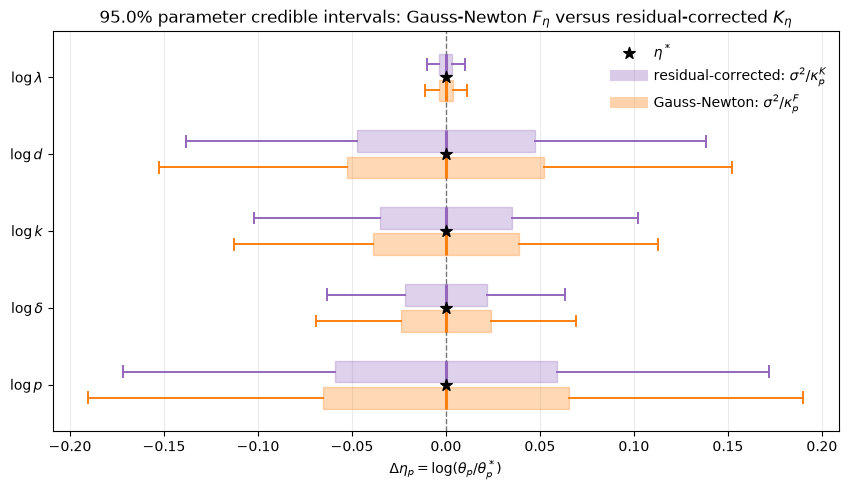

In [18]:
# Gauss--Newton counterpart of Part 9a: the same construction with the
# residual-corrected curvature K_eta replaced by F_eta = J_eta^T J_eta.
# Settings are deliberately shared with Part 9a so that the two
# intervals differ only through the curvature matrix.
GN_CI_NOISE_SIGMA = PAPER_CI_NOISE_SIGMA
GN_CI_LEVEL = PAPER_CI_LEVEL
GN_CI_EIGENVALUE_REL_TOL = PAPER_CI_EIGENVALUE_REL_TOL
GN_CI_COMPATIBILITY_REL_TOL = PAPER_CI_COMPATIBILITY_REL_TOL

gn_F_eta = 0.5*(G_logtheta+G_logtheta.T)
if not np.allclose(
        gn_F_eta, J_logtheta.T @ J_logtheta, rtol=1e-10, atol=1e-12):
    raise RuntimeError('G_logtheta is inconsistent with J_eta^T J_eta')

gn_eta_star = eta_free_new.copy()
gn_theta_star = np.exp(gn_eta_star)
gn_profile_curvature = compute_quadratic_profile_sensitivity(
    J_logtheta, gn_F_eta, FREE_LOG_PARAM_TXT,
    GN_CI_EIGENVALUE_REL_TOL, GN_CI_COMPATIBILITY_REL_TOL)
gn_kappa_F = gn_profile_curvature['kappa_K'].copy()

gn_interval_computable = (
    gn_profile_curvature['curvature_psd']
    & gn_profile_curvature['compatibility_holds']
    & gn_profile_curvature['mixed_block_in_range']
    & gn_profile_curvature['positive_kappa'])
gn_assumptions_verified = (
    gn_interval_computable
    & paper_fit_is_interior
    & paper_local_minimum_verified)
gn_parameter_sd = np.full(N_FREE, np.nan)
gn_parameter_sd[gn_interval_computable] = (
    GN_CI_NOISE_SIGMA/np.sqrt(gn_kappa_F[gn_interval_computable]))

gn_alpha = 1.0-GN_CI_LEVEL
gn_probability = np.array([
    gn_alpha/2.0, 0.25, 0.50, 0.75, 1.0-gn_alpha/2.0])
gn_u_quantiles = (
    norm.ppf(gn_probability)[:, None]*gn_parameter_sd[None, :])
gn_eta_quantiles = gn_eta_star[None, :]+gn_u_quantiles
gn_theta_quantiles = np.exp(gn_eta_quantiles)
gn_eta_lower, gn_eta_median, gn_eta_upper = (
    gn_eta_quantiles[0], gn_eta_quantiles[2], gn_eta_quantiles[4])
gn_theta_lower, gn_theta_median, gn_theta_upper = (
    gn_theta_quantiles[0], gn_theta_quantiles[2], gn_theta_quantiles[4])
gn_interval_hits_admissible_boundary = (
    (gn_eta_lower <= eta_lb) | (gn_eta_upper >= eta_ub))

# Classical check: for positive definite F_eta,
# kappa_p^F = 1/(F_eta^{-1})_pp (Wald / Fisher-information interval).
gn_F_eigenvalues, gn_F_eigenvectors = np.linalg.eigh(gn_F_eta)
gn_F_cutoff = GN_CI_EIGENVALUE_REL_TOL*max(
    float(np.max(np.abs(gn_F_eigenvalues))), np.finfo(float).tiny)
gn_F_positive = gn_F_eigenvalues > gn_F_cutoff
gn_F_pseudoinverse = (
    gn_F_eigenvectors[:, gn_F_positive]
    @ np.diag(1.0/gn_F_eigenvalues[gn_F_positive])
    @ gn_F_eigenvectors[:, gn_F_positive].T)
gn_F_pseudoinverse = 0.5*(gn_F_pseudoinverse+gn_F_pseudoinverse.T)
gn_kappa_from_pseudoinverse = np.divide(
    1.0, np.diag(gn_F_pseudoinverse),
    out=np.full(N_FREE, np.nan),
    where=np.diag(gn_F_pseudoinverse) > 0.0)
gn_kappa_pseudoinverse_relative_error = np.divide(
    np.abs(gn_kappa_F-gn_kappa_from_pseudoinverse),
    np.maximum(np.abs(gn_kappa_F), np.finfo(float).tiny))

# Effect of the residual correction on each coordinate.
gn_kappa_ratio_K_over_F = np.divide(
    paper_kappa_K, gn_kappa_F,
    out=np.full(N_FREE, np.nan),
    where=np.isfinite(gn_kappa_F) & (gn_kappa_F > 0.0))
gn_sd_ratio_F_over_K = np.divide(
    gn_parameter_sd, paper_parameter_sd,
    out=np.full(N_FREE, np.nan),
    where=np.isfinite(paper_parameter_sd) & (paper_parameter_sd > 0.0))

gauss_newton_parameter_credible_intervals = {
    'method': 'Part 9a construction with F_eta = J_eta^T J_eta',
    'coordinate': 'eta = log(theta_free)',
    'level': GN_CI_LEVEL,
    'alpha': gn_alpha,
    'sigma': GN_CI_NOISE_SIGMA,
    'probability': gn_probability,
    'parameter_names': np.asarray(FREE_PARAM_TXT, dtype='U'),
    'eta_star': gn_eta_star,
    'theta_star': gn_theta_star,
    'F_eta': gn_F_eta.copy(),
    'profile_curvature': gn_profile_curvature,
    'kappa_F': gn_kappa_F,
    'parameter_sd': gn_parameter_sd,
    'interval_computable': gn_interval_computable,
    'assumptions_verified': gn_assumptions_verified,
    'interval_hits_admissible_boundary': (
        gn_interval_hits_admissible_boundary),
    'u_quantiles': gn_u_quantiles,
    'u_lower': gn_u_quantiles[0],
    'u_q25': gn_u_quantiles[1],
    'u_median': gn_u_quantiles[2],
    'u_q75': gn_u_quantiles[3],
    'u_upper': gn_u_quantiles[4],
    'eta_quantiles': gn_eta_quantiles,
    'eta_lower': gn_eta_lower,
    'eta_median': gn_eta_median,
    'eta_upper': gn_eta_upper,
    'theta_quantiles': gn_theta_quantiles,
    'theta_lower': gn_theta_lower,
    'theta_median': gn_theta_median,
    'theta_upper': gn_theta_upper,
    'F_pseudoinverse': gn_F_pseudoinverse,
    'kappa_from_F_pseudoinverse': gn_kappa_from_pseudoinverse,
    'kappa_pseudoinverse_relative_error': (
        gn_kappa_pseudoinverse_relative_error),
    'kappa_ratio_K_over_F': gn_kappa_ratio_K_over_F,
    'sd_ratio_F_over_K': gn_sd_ratio_F_over_K,
}

print(
    f'Gauss--Newton {100*GN_CI_LEVEL:.1f}% parameter credible intervals')
print('posterior sd = sigma/sqrt(kappa_p^F),  F_eta = J_eta^T J_eta')
print(
    f"{'parameter':>10s} {'kappa_F':>12s} {'kappa_K':>12s} "
    f"{'kappa_K/F':>10s} {'sd_F(eta)':>12s} {'sd_F/sd_K':>10s} "
    f"{'eta lower':>13s} {'eta upper':>13s} "
    f"{'theta lower':>14s} {'theta upper':>14s} "
    f"{'compute':>8s} {'bound':>7s}")
for p_idx, name in enumerate(FREE_PARAM_TXT):
    print(
        f'{name:>10s} '
        f'{gn_kappa_F[p_idx]:12.4e} '
        f'{paper_kappa_K[p_idx]:12.4e} '
        f'{gn_kappa_ratio_K_over_F[p_idx]:10.4f} '
        f'{gn_parameter_sd[p_idx]:12.4e} '
        f'{gn_sd_ratio_F_over_K[p_idx]:10.4f} '
        f'{gn_eta_lower[p_idx]:13.6e} '
        f'{gn_eta_upper[p_idx]:13.6e} '
        f'{gn_theta_lower[p_idx]:14.6e} '
        f'{gn_theta_upper[p_idx]:14.6e} '
        f'{str(gn_interval_computable[p_idx]):>8s} '
        f'{str(gn_interval_hits_admissible_boundary[p_idx]):>7s}')
print('max relative error in kappa_p^F = 1/(F^dagger)_pp =',
      np.nanmax(gn_kappa_pseudoinverse_relative_error))
print('F_eta PSD =', gn_profile_curvature['curvature_psd'])
print('compatibility by parameter =',
      gn_profile_curvature['compatibility_holds'])


def credible_interval_boxplot_stats(u_quantiles, indices):
    return [
        {
            'label': FREE_PARAM_TXT[p_idx],
            'whislo': u_quantiles[0, p_idx],
            'q1': u_quantiles[1, p_idx],
            'med': u_quantiles[2, p_idx],
            'q3': u_quantiles[3, p_idx],
            'whishi': u_quantiles[4, p_idx],
            'fliers': [],
        }
        for p_idx in indices
    ]


gn_y = np.arange(1, N_FREE+1, dtype=float)
gn_box_offset = 0.17
fig, ax = plt.subplots(figsize=(8.6, 5.0))
paper_indices_9a = np.flatnonzero(
    paper_interval_computable
    & np.all(np.isfinite(paper_u_quantiles), axis=0))
if paper_indices_9a.size:
    ax.bxp(
        credible_interval_boxplot_stats(
            paper_u_quantiles, paper_indices_9a),
        positions=gn_y[paper_indices_9a]-gn_box_offset,
        orientation='horizontal', showfliers=False,
        manage_ticks=False, patch_artist=True, widths=0.28,
        boxprops={'facecolor': 'tab:purple', 'alpha': 0.30,
                  'edgecolor': 'tab:purple'},
        whiskerprops={'color': 'tab:purple', 'linewidth': 1.4},
        capprops={'color': 'tab:purple', 'linewidth': 1.4},
        medianprops={'color': 'tab:purple', 'linewidth': 2.2})
gn_indices = np.flatnonzero(
    gn_interval_computable
    & np.all(np.isfinite(gn_u_quantiles), axis=0))
if gn_indices.size:
    ax.bxp(
        credible_interval_boxplot_stats(gn_u_quantiles, gn_indices),
        positions=gn_y[gn_indices]+gn_box_offset,
        orientation='horizontal', showfliers=False,
        manage_ticks=False, patch_artist=True, widths=0.28,
        boxprops={'facecolor': 'tab:orange', 'alpha': 0.30,
                  'edgecolor': 'tab:orange'},
        whiskerprops={'color': 'tab:orange', 'linewidth': 1.4},
        capprops={'color': 'tab:orange', 'linewidth': 1.4},
        medianprops={'color': 'tab:orange', 'linewidth': 2.2})
ax.scatter(np.zeros(N_FREE), gn_y, marker='*', s=75,
           color='black', label=r'$\eta^*$', zorder=4)
ax.plot([], [], color='tab:purple', lw=8, alpha=0.35,
        label=r'residual-corrected: $\sigma^2/\kappa_p^K$')
ax.plot([], [], color='tab:orange', lw=8, alpha=0.35,
        label=r'Gauss-Newton: $\sigma^2/\kappa_p^F$')
ax.axvline(0.0, color='black', ls='--', lw=1.0, alpha=0.5)
ax.set_yticks(gn_y)
ax.set_yticklabels(FREE_LOG_PARAM_TEX)
ax.set_ylim(N_FREE+0.6, 0.4)
ax.set_xlabel(r'$\Delta\eta_p=\log(\theta_p/\theta_p^*)$')
ax.set_title(
    f'{100*GN_CI_LEVEL:.1f}% parameter credible intervals: '
    r'Gauss-Newton $F_\eta$ versus residual-corrected $K_\eta$')
ax.grid(axis='x', alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### 9a-MCMC. Parameter credible intervals from posterior samples

This section computes one posterior for the current analysis data. The likelihood is the exact nonlinear ODE observation model,

$$y_n\mid\eta\sim N\!\left(h(t_n;\eta),\sigma^2\right).$$

Because MCMC requires a proper posterior, the free log parameters use the local uniform prior $\eta_p\sim\operatorname{Uniform}(\widehat\eta_p-a,\widehat\eta_p+a)$, clipped to the physical parameter bounds, with $a=$ `MCMC_PRIOR_LOG_HALF_WIDTH`. The four chains start from overdispersed perturbations of $\widehat\eta$. Random-walk Metropolis operates in the Algorithm 2.1 eigenvector coordinates $W^T(\eta-\widehat\eta)$; during 5,000 warmup steps it learns the remaining covariance in the standardized rotated coordinates. Both covariance and step scale are then frozen before retaining 30,000 draws per chain. The likelihood ODE solves use `MCMC_ODE_RTOL=1e-10` and `MCMC_ODE_ATOL=1e-12`. For each parameter, the reported credible interval is the empirical equal-tailed posterior interval. The fixed parameter $c$ is reported as the point interval $[3,3]$. The plot uses $\Delta\eta_p=\log(\theta_p/\widehat\theta_p)$ for the five sampled parameters.

95.0% MCMC credible intervals
 parameter          lower         median          upper
    lambda   1.284378e-01   1.296470e-01   1.313647e-01
         d   2.005521e-02   2.362036e-02   2.690982e-02
         k   1.939080e-04   2.149115e-04   2.391175e-04
     delta   2.212229e-01   2.357152e-01   2.516756e-01
         p   1.345648e+03   1.613894e+03   1.921188e+03
         c   3.000000e+00   3.000000e+00   3.000000e+00


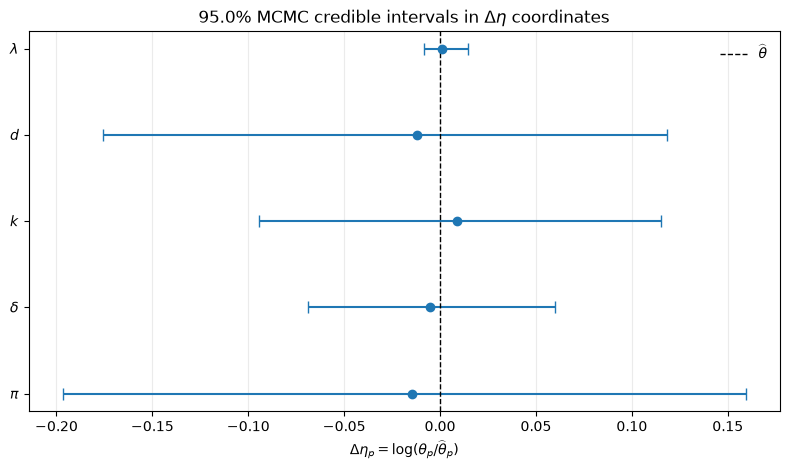

In [19]:
MCMC_NOISE_SIGMA = 2.5e-3
MCMC_CREDIBLE_LEVEL = 0.95
MCMC_RANDOM_SEED = 20260903
MCMC_N_CHAINS = 4              # overdispersed starts around phi_hat
MCMC_WARMUP = 5_000            # learn scale and rotated residual covariance
MCMC_DRAWS_PER_CHAIN = 10_000  # target tail ESS > 400; adjust after IAT
MCMC_ADAPT_INTERVAL = 50       # warmup adaptation only
MCMC_TARGET_ACCEPT = 0.234
MCMC_ODE_RTOL, MCMC_ODE_ATOL = 1e-10, 1e-12

# Proper local prior and warmup-only adaptation controls.
MCMC_PRIOR_LOG_HALF_WIDTH = 2.0
MCMC_INITIAL_JITTER_SCALE = 10.0
MCMC_ADAPT_WINDOW = 1_000
MCMC_COVARIANCE_SHRINKAGE = 0.05
MCMC_ODE_FAILURE_LIMIT = 0.01

if not np.isfinite(MCMC_NOISE_SIGMA) or MCMC_NOISE_SIGMA <= 0.0:
    raise ValueError('MCMC_NOISE_SIGMA must be positive')
if not 0.0 < MCMC_CREDIBLE_LEVEL < 1.0:
    raise ValueError('MCMC_CREDIBLE_LEVEL must lie strictly between 0 and 1')
if MCMC_N_CHAINS < 2:
    raise ValueError('MCMC_N_CHAINS must be at least 2')
if MCMC_WARMUP < MCMC_ADAPT_INTERVAL:
    raise ValueError('MCMC_WARMUP must cover at least one adaptation block')
if MCMC_DRAWS_PER_CHAIN < 1:
    raise ValueError('MCMC_DRAWS_PER_CHAIN must be positive')
if MCMC_WARMUP % MCMC_ADAPT_INTERVAL != 0:
    raise ValueError('MCMC_WARMUP must be divisible by MCMC_ADAPT_INTERVAL')
if MCMC_PRIOR_LOG_HALF_WIDTH <= 0.0:
    raise ValueError('MCMC_PRIOR_LOG_HALF_WIDTH must be positive')
if not (0.0 <= MCMC_COVARIANCE_SHRINKAGE < 1.0):
    raise ValueError('MCMC_COVARIANCE_SHRINKAGE must lie in [0, 1)')
if MCMC_ODE_RTOL <= 0.0 or MCMC_ODE_ATOL <= 0.0:
    raise ValueError('ODE tolerances must be positive')

mcmc_observed_h = np.log10(xexp_fitting)
mcmc_phi_hat = eta_free_new.copy()
mcmc_prior_lower = np.maximum(
    eta_lb, mcmc_phi_hat-MCMC_PRIOR_LOG_HALF_WIDTH)
mcmc_prior_upper = np.minimum(
    eta_ub, mcmc_phi_hat+MCMC_PRIOR_LOG_HALF_WIDTH)

# W is the orthogonal eigenvector matrix from the log-coordinate
# Gauss--Newton construction used above (Algorithm 2.1 coordinates).
mcmc_rotation_W = eigvecs_logtheta.copy()
if not np.allclose(
        mcmc_rotation_W.T @ mcmc_rotation_W,
        np.eye(N_FREE), atol=1e-10, rtol=1e-10):
    raise RuntimeError('MCMC rotation W must be orthogonal')

mcmc_ode_counter = {'attempts': 0, 'failures': 0}


def mcmc_observable_hiv(theta):
    """MCMC likelihood solve with the requested ODE tolerances."""
    t_eval = np.concatenate([[0.0], tspan])
    solution = solve_ivp(
        lambda t, state: hiv_eq(t, state, theta),
        [0.0, t_eval[-1]], y0, t_eval=t_eval,
        rtol=MCMC_ODE_RTOL, atol=MCMC_ODE_ATOL, method='DOP853')
    if (not solution.success
            or solution.y.shape[1] != t_eval.size):
        raise RuntimeError(
            f'MCMC ODE integration failed: {solution.message}')
    virus = solution.y[2, 1:]
    if np.any(~np.isfinite(virus)):
        raise RuntimeError('MCMC ODE solution has non-finite values')
    virus = np.maximum(virus, 1e-30)
    return np.log10(2.0*virus*1e3)


def mcmc_phi_from_rotated(rotated_coordinate):
    return mcmc_phi_hat+mcmc_rotation_W @ rotated_coordinate


def mcmc_rotated_from_phi(phi):
    return mcmc_rotation_W.T @ (phi-mcmc_phi_hat)


def mcmc_log_posterior_rotated(rotated_coordinate):
    """Exact ODE log likelihood and uniform prior in phi=log(theta)."""
    phi = mcmc_phi_from_rotated(
        np.asarray(rotated_coordinate, dtype=float))
    if (np.any(phi < mcmc_prior_lower)
            or np.any(phi > mcmc_prior_upper)):
        return -np.inf
    mcmc_ode_counter['attempts'] += 1
    try:
        h_model = mcmc_observable_hiv(theta_from_free_log(phi))
    except (ValueError, RuntimeError, FloatingPointError):
        mcmc_ode_counter['failures'] += 1
        return -np.inf
    residual = (
        h_model-mcmc_observed_h)/MCMC_NOISE_SIGMA
    value = float(-0.5*np.dot(residual, residual))
    if not np.isfinite(value):
        mcmc_ode_counter['failures'] += 1
        return -np.inf
    return value


def mcmc_base_factor_rotated():
    """Local posterior factor after rotation by W."""
    prior_sd = (
        mcmc_prior_upper-mcmc_prior_lower)/np.sqrt(12.0)
    prior_precision_rotated = (
        mcmc_rotation_W.T @ np.diag(1.0/prior_sd**2)
        @ mcmc_rotation_W)
    likelihood_precision_rotated = np.diag(
        eigvals_logtheta/MCMC_NOISE_SIGMA**2)
    precision = (likelihood_precision_rotated
                 + prior_precision_rotated)
    precision = 0.5*(precision+precision.T)
    eigenvalues, eigenvectors = np.linalg.eigh(precision)
    eigenvalue_floor = max(
        np.max(eigenvalues)*1e-12, 1e-12)
    covariance = (eigenvectors
                  @ np.diag(1.0/np.maximum(
                      eigenvalues, eigenvalue_floor))
                  @ eigenvectors.T)
    covariance = 0.5*(covariance+covariance.T)
    jitter = max(
        np.max(np.diag(covariance))*1e-12, 1e-16)
    return np.linalg.cholesky(
        covariance+jitter*np.eye(N_FREE))


def mcmc_residual_factor(rotated_history, base_factor):
    """Learn residual covariance in standardized rotated coordinates."""
    standardized = np.linalg.solve(
        base_factor, rotated_history.T).T
    covariance = np.cov(standardized, rowvar=False, ddof=1)
    covariance = np.atleast_2d(covariance)
    covariance = (
        (1.0-MCMC_COVARIANCE_SHRINKAGE)*covariance
        + MCMC_COVARIANCE_SHRINKAGE*np.eye(N_FREE))
    covariance = 0.5*(covariance+covariance.T)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    eigenvalue_floor = max(
        np.max(eigenvalues)*1e-8, 1e-8)
    covariance = (eigenvectors
                  @ np.diag(np.maximum(
                      eigenvalues, eigenvalue_floor))
                  @ eigenvectors.T)
    covariance = 0.5*(covariance+covariance.T)
    return np.linalg.cholesky(
        covariance+1e-12*np.eye(N_FREE))


def sample_mcmc_posterior():
    """Overdispersed RWM; all adaptation is confined to warmup."""
    rng = np.random.default_rng(MCMC_RANDOM_SEED)
    base_factor = mcmc_base_factor_rotated()
    optimal_scale = 2.38/np.sqrt(N_FREE)
    prior_span = mcmc_prior_upper-mcmc_prior_lower
    interior = 1e-10*np.maximum(prior_span, 1.0)
    rotated_states = np.empty((MCMC_N_CHAINS, N_FREE))
    log_probability = np.empty(MCMC_N_CHAINS)

    # phi_hat plus a large local-posterior-scale jitter gives
    # intentionally overdispersed initial chains.
    for chain_idx in range(MCMC_N_CHAINS):
        initialized = False
        for initialization_attempt in range(50):
            jitter_scale = (MCMC_INITIAL_JITTER_SCALE
                            * 0.85**initialization_attempt)
            standardized_jitter = (
                jitter_scale*rng.normal(size=N_FREE))
            rotated_state = base_factor @ standardized_jitter
            phi_state = mcmc_phi_from_rotated(rotated_state)
            phi_state = np.clip(
                phi_state, mcmc_prior_lower+interior,
                mcmc_prior_upper-interior)
            rotated_state = mcmc_rotated_from_phi(phi_state)
            candidate_log_probability = (
                mcmc_log_posterior_rotated(rotated_state))
            if np.isfinite(candidate_log_probability):
                rotated_states[chain_idx] = rotated_state
                log_probability[chain_idx] = (
                    candidate_log_probability)
                initialized = True
                break
        if not initialized:
            rotated_states[chain_idx] = np.zeros(N_FREE)
            log_probability[chain_idx] = (
                mcmc_log_posterior_rotated(
                    rotated_states[chain_idx]))
    if not np.all(np.isfinite(log_probability)):
        raise RuntimeError('Could not initialize the MCMC chains')

    # Warmup: learn a scalar step size and the residual covariance in
    # standardized W-rotated coordinates.
    log_step_scale = np.zeros(MCMC_N_CHAINS)
    accepted_in_block = np.zeros(MCMC_N_CHAINS, dtype=int)
    residual_factor = np.eye(N_FREE)
    warmup_history = np.empty((
        MCMC_WARMUP, MCMC_N_CHAINS, N_FREE))

    for warmup_step in range(MCMC_WARMUP):
        proposal_factor = base_factor @ residual_factor
        for chain_idx in range(MCMC_N_CHAINS):
            proposal = (
                rotated_states[chain_idx]
                + optimal_scale*np.exp(log_step_scale[chain_idx])
                * proposal_factor @ rng.normal(size=N_FREE))
            proposal_log_probability = mcmc_log_posterior_rotated(
                proposal)
            accept = bool(
                np.isfinite(proposal_log_probability)
                and np.log(rng.uniform())
                < proposal_log_probability-log_probability[chain_idx])
            if accept:
                rotated_states[chain_idx] = proposal
                log_probability[chain_idx] = proposal_log_probability
            accepted_in_block[chain_idx] += int(accept)
        warmup_history[warmup_step] = rotated_states

        if (warmup_step+1) % MCMC_ADAPT_INTERVAL == 0:
            acceptance = accepted_in_block/MCMC_ADAPT_INTERVAL
            block_number = (warmup_step+1)/MCMC_ADAPT_INTERVAL
            gain = min(0.50, 1.0/np.sqrt(block_number))
            log_step_scale += gain*(acceptance-MCMC_TARGET_ACCEPT)
            log_step_scale = np.clip(log_step_scale, -5.0, 5.0)
            accepted_in_block[:] = 0

            window_start = max(
                0, warmup_step+1-MCMC_ADAPT_WINDOW)
            history = warmup_history[
                window_start:warmup_step+1].reshape(-1, N_FREE)
            if history.shape[0] > N_FREE:
                residual_factor = mcmc_residual_factor(
                    history, base_factor)

    # Freeze both learned objects before collecting posterior draws.
    # The sampling loop below contains no covariance or scale update.
    frozen_log_step_scale = log_step_scale.copy()
    frozen_residual_factor = residual_factor.copy()
    frozen_proposal_factor = base_factor @ frozen_residual_factor
    rotated_draws = np.empty((
        MCMC_N_CHAINS, MCMC_DRAWS_PER_CHAIN, N_FREE))

    for draw_idx in range(MCMC_DRAWS_PER_CHAIN):
        for chain_idx in range(MCMC_N_CHAINS):
            proposal = (
                rotated_states[chain_idx]
                + optimal_scale*np.exp(
                    frozen_log_step_scale[chain_idx])
                * frozen_proposal_factor @ rng.normal(size=N_FREE))
            proposal_log_probability = mcmc_log_posterior_rotated(
                proposal)
            accept = bool(
                np.isfinite(proposal_log_probability)
                and np.log(rng.uniform())
                < proposal_log_probability-log_probability[chain_idx])
            if accept:
                rotated_states[chain_idx] = proposal
                log_probability[chain_idx] = proposal_log_probability
            rotated_draws[chain_idx, draw_idx] = (
                rotated_states[chain_idx])

    phi_draws = (
        np.einsum(
            'ij,cdj->cdi', mcmc_rotation_W, rotated_draws,
            optimize=True)
        + mcmc_phi_hat[None, None, :])
    return (phi_draws, frozen_log_step_scale,
            frozen_residual_factor)


(mcmc_logtheta_chains,
 mcmc_frozen_log_step_scale,
 mcmc_frozen_residual_factor) = sample_mcmc_posterior()
MCMC_ADAPTATION_FROZEN_DURING_SAMPLING = True
mcmc_ode_failure_rate = (
    mcmc_ode_counter['failures']/mcmc_ode_counter['attempts']
    if mcmc_ode_counter['attempts'] else 0.0)
if mcmc_ode_failure_rate >= MCMC_ODE_FAILURE_LIMIT:
    raise RuntimeError(
        f'MCMC ODE failure rate {mcmc_ode_failure_rate:.3%} '
        f'exceeds {MCMC_ODE_FAILURE_LIMIT:.1%}')

mcmc_logtheta_draws = mcmc_logtheta_chains.reshape(-1, N_FREE)
mcmc_theta_draws = np.exp(mcmc_logtheta_draws)
mcmc_alpha = 1.0-MCMC_CREDIBLE_LEVEL
mcmc_probability = np.array([
    mcmc_alpha/2.0, 0.5, 1.0-mcmc_alpha/2.0])
mcmc_logtheta_quantiles_free = np.quantile(
    mcmc_logtheta_draws, mcmc_probability, axis=0)
mcmc_theta_quantiles_free = np.quantile(
    mcmc_theta_draws, mcmc_probability, axis=0)
mcmc_delta_eta_quantiles_free = (
    mcmc_logtheta_quantiles_free-mcmc_phi_hat[None, :])

# Include the fixed parameter so every model parameter is reported.
mcmc_logtheta_quantiles = np.empty((3, N_THETA))
mcmc_theta_quantiles = np.empty((3, N_THETA))
mcmc_logtheta_quantiles[:, FREE_PARAM_IDX] = (
    mcmc_logtheta_quantiles_free)
mcmc_theta_quantiles[:, FREE_PARAM_IDX] = (
    mcmc_theta_quantiles_free)
for fixed_name, fixed_value in FIXED_PARAMETER_VALUES.items():
    fixed_idx = PARAM_TXT.index(fixed_name)
    mcmc_logtheta_quantiles[:, fixed_idx] = np.log(fixed_value)
    mcmc_theta_quantiles[:, fixed_idx] = fixed_value

mcmc_credible_intervals = {
    'method': 'warmup-adapted rotated random-walk Metropolis',
    'level': MCMC_CREDIBLE_LEVEL,
    'sigma': MCMC_NOISE_SIGMA,
    'probability': mcmc_probability,
    'parameter_names': np.asarray(PARAM_TXT, dtype='U'),
    'free_parameter_indices': FREE_PARAM_IDX.copy(),
    'rotation_W': mcmc_rotation_W,
    'logtheta_chains': mcmc_logtheta_chains,
    'logtheta_draws': mcmc_logtheta_draws,
    'theta_draws_free': mcmc_theta_draws,
    'delta_eta_draws_free': (
        mcmc_logtheta_draws-mcmc_phi_hat[None, :]),
    'delta_eta_lower_free': mcmc_delta_eta_quantiles_free[0],
    'delta_eta_median_free': mcmc_delta_eta_quantiles_free[1],
    'delta_eta_upper_free': mcmc_delta_eta_quantiles_free[2],
    'logtheta_lower': mcmc_logtheta_quantiles[0],
    'logtheta_median': mcmc_logtheta_quantiles[1],
    'logtheta_upper': mcmc_logtheta_quantiles[2],
    'theta_lower': mcmc_theta_quantiles[0],
    'theta_median': mcmc_theta_quantiles[1],
    'theta_upper': mcmc_theta_quantiles[2],
    'prior_log_lower_free': mcmc_prior_lower,
    'prior_log_upper_free': mcmc_prior_upper,
    'frozen_log_step_scale': mcmc_frozen_log_step_scale,
    'frozen_residual_factor': mcmc_frozen_residual_factor,
    'adaptation_frozen_during_sampling': (
        MCMC_ADAPTATION_FROZEN_DURING_SAMPLING),
    'ode_rtol': MCMC_ODE_RTOL,
    'ode_atol': MCMC_ODE_ATOL,
    'ode_attempts': mcmc_ode_counter['attempts'],
    'ode_failures': mcmc_ode_counter['failures'],
    'ode_failure_rate': mcmc_ode_failure_rate,
}

print(f'{100*MCMC_CREDIBLE_LEVEL:.1f}% MCMC credible intervals')
print(f"{'parameter':>10s} {'lower':>14s} "
      f"{'median':>14s} {'upper':>14s}")
for param_idx, name in enumerate(PARAM_TXT):
    print(
        f'{name:>10s} '
        f'{mcmc_theta_quantiles[0, param_idx]:14.6e} '
        f'{mcmc_theta_quantiles[1, param_idx]:14.6e} '
        f'{mcmc_theta_quantiles[2, param_idx]:14.6e}')

y_position = np.arange(N_FREE)
delta_eta_median = mcmc_delta_eta_quantiles_free[1]
fig, ax = plt.subplots(figsize=(8.0, 4.8))
ax.errorbar(
    delta_eta_median, y_position,
    xerr=np.vstack([
        delta_eta_median-mcmc_delta_eta_quantiles_free[0],
        mcmc_delta_eta_quantiles_free[2]-delta_eta_median]),
    fmt='o', capsize=4, color='tab:blue')
ax.axvline(0.0, color='black', ls='--', lw=1.0,
           label=r'$\widehat\theta$')
ax.set_yticks(y_position)
ax.set_yticklabels(FREE_PARAM_TEX)
ax.invert_yaxis()
ax.set_xlabel(
    r'$\Delta\eta_p=\log(\theta_p/\widehat\theta_p)$')
ax.set_title(
    f'{100*MCMC_CREDIBLE_LEVEL:.1f}% MCMC credible intervals in '
    r'$\Delta\eta$ coordinates')
ax.grid(axis='x', alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 9a comparison. PDF residual-corrected interval, Gauss--Newton interval, and MCMC

For every free log parameter, compare the Gaussian quantiles implied by Eq. (1.89), $u_p\sim N(0,\sigma^2/\kappa_p^K)$, the Gauss--Newton quantiles of Part 9a-GN, $u_p\sim N(0,\sigma^2/\kappa_p^F)$, with the empirical MCMC quantiles in the common coordinate $\Delta\eta_p=\log(\theta_p/\theta_p^*)$. The table reports all three intervals, their widths, and the width ratios Paper/MCMC, GN/MCMC, and GN/Paper; the grouped boxplot places the three distributions on the same parameter row, so the gap between the Gauss--Newton and residual-corrected boxes shows how much the residual term $C_\eta$ moves each interval towards or away from MCMC. The code also verifies that the two methods use the same fitted reference point and noise level.

95.0% credible intervals: PDF Eq. (1.89) versus Gauss--Newton versus MCMC
same eta reference (Paper, MCMC) = True
same noise sigma   (Paper, MCMC) = True
same eta reference (GN, MCMC)    = True
same noise sigma   (GN, MCMC)    = True
 parameter         method        lower       median        upper        width
    lambda           MCMC  -8.1933e-03   1.1777e-03   1.4340e-02   2.2533e-02
    lambda  Paper kappa_K  -1.0079e-02   0.0000e+00   1.0079e-02   2.0158e-02
    lambda     GN kappa_F  -1.1384e-02   0.0000e+00   1.1384e-02   2.2768e-02
               Paper/MCMC                                              0.8946
                  GN/MCMC                                              1.0104
                 GN/Paper                                              1.1295
         d           MCMC  -1.7552e-01  -1.1897e-02   1.1849e-01   2.9400e-01
         d  Paper kappa_K  -1.3815e-01   0.0000e+00   1.3815e-01   2.7630e-01
         d     GN kappa_F  -1.5237e-01   0.0000e+00   1.5237e-01

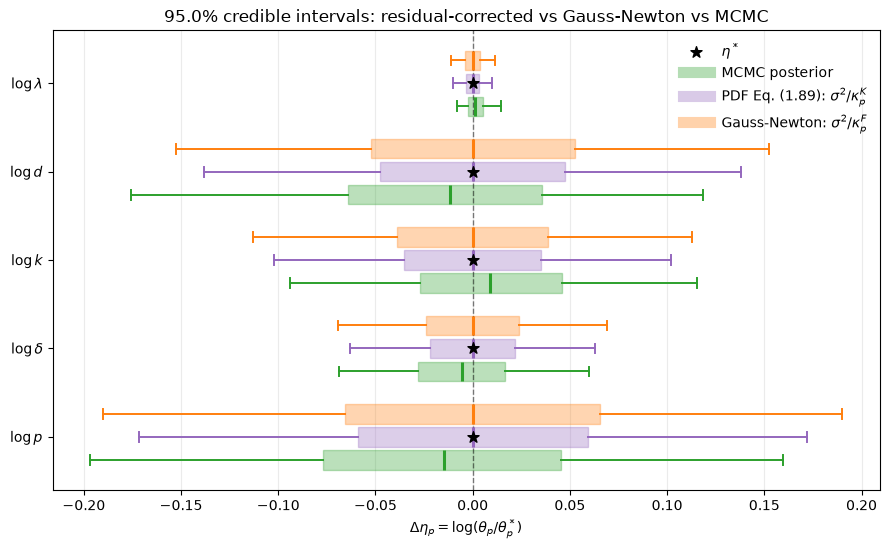

In [20]:
COMPARISON_CREDIBLE_LEVEL = 0.95
if not 0.0 < COMPARISON_CREDIBLE_LEVEL < 1.0:
    raise ValueError(
        'COMPARISON_CREDIBLE_LEVEL must lie strictly between 0 and 1')

# Compare MCMC with the PDF Eq. (1.89) residual-corrected interval
# in Delta eta_p = log(theta_p/theta_p^*).
comparison_probability = np.array([
    (1.0-COMPARISON_CREDIBLE_LEVEL)/2.0,
    0.25, 0.50, 0.75,
    1.0-(1.0-COMPARISON_CREDIBLE_LEVEL)/2.0,
])
comparison_mcmc_delta_eta_draws = (
    mcmc_logtheta_draws-paper_eta_star[None, :])
comparison_mcmc_quantiles = np.quantile(
    comparison_mcmc_delta_eta_draws,
    comparison_probability, axis=0)
comparison_paper_quantiles = (
    norm.ppf(comparison_probability)[:, None]
    * paper_parameter_sd[None, :])
comparison_gn_quantiles = (
    norm.ppf(comparison_probability)[:, None]
    * gn_parameter_sd[None, :])
comparison_reference_match = bool(np.allclose(
    paper_eta_star, mcmc_phi_hat, rtol=1e-10, atol=1e-12))
comparison_sigma_match = bool(np.isclose(
    PAPER_CI_NOISE_SIGMA, MCMC_NOISE_SIGMA,
    rtol=1e-12, atol=0.0))
comparison_gn_reference_match = bool(np.allclose(
    paper_eta_star, gn_eta_star, rtol=1e-10, atol=1e-12))
comparison_gn_sigma_match = bool(np.isclose(
    GN_CI_NOISE_SIGMA, MCMC_NOISE_SIGMA, rtol=1e-12, atol=0.0))
comparison_mcmc_width = (
    comparison_mcmc_quantiles[-1]
    - comparison_mcmc_quantiles[0])
comparison_paper_width = (
    comparison_paper_quantiles[-1]
    - comparison_paper_quantiles[0])
comparison_width_ratio_paper_over_mcmc = np.divide(
    comparison_paper_width, comparison_mcmc_width,
    out=np.full(N_FREE, np.nan),
    where=(np.isfinite(comparison_mcmc_width)
           & (comparison_mcmc_width > 0.0)))
comparison_gn_width = (
    comparison_gn_quantiles[-1]-comparison_gn_quantiles[0])
comparison_width_ratio_gn_over_mcmc = np.divide(
    comparison_gn_width, comparison_mcmc_width,
    out=np.full(N_FREE, np.nan),
    where=(np.isfinite(comparison_mcmc_width)
           & (comparison_mcmc_width > 0.0)))
comparison_width_ratio_gn_over_paper = np.divide(
    comparison_gn_width, comparison_paper_width,
    out=np.full(N_FREE, np.nan),
    where=(np.isfinite(comparison_paper_width)
           & (comparison_paper_width > 0.0)))

credible_interval_comparison = {
    'coordinate': 'Delta eta = log(theta/theta_star)',
    'level': COMPARISON_CREDIBLE_LEVEL,
    'probability': comparison_probability,
    'parameter_names': np.asarray(FREE_PARAM_TXT, dtype='U'),
    'mcmc_quantiles': comparison_mcmc_quantiles,
    'paper_quantiles': comparison_paper_quantiles,
    'paper_kappa_K': paper_kappa_K.copy(),
    'gn_quantiles': comparison_gn_quantiles,
    'gn_kappa_F': gn_kappa_F.copy(),
    'mcmc_width': comparison_mcmc_width,
    'paper_width': comparison_paper_width,
    'gn_width': comparison_gn_width,
    'width_ratio_paper_over_mcmc': (
        comparison_width_ratio_paper_over_mcmc),
    'width_ratio_gn_over_mcmc': comparison_width_ratio_gn_over_mcmc,
    'width_ratio_gn_over_paper': comparison_width_ratio_gn_over_paper,
    'gn_interval_computable': gn_interval_computable.copy(),
    'gn_reference_eta_match': comparison_gn_reference_match,
    'gn_noise_sigma_match': comparison_gn_sigma_match,
    'paper_interval_computable': paper_interval_computable.copy(),
    'paper_theorem_assumptions_verified': (
        paper_theorem_assumptions_verified.copy()),
    'reference_eta_match': comparison_reference_match,
    'noise_sigma_match': comparison_sigma_match,
}

print(
    f'{100*COMPARISON_CREDIBLE_LEVEL:.1f}% credible intervals: '
    'PDF Eq. (1.89) versus Gauss--Newton versus MCMC')
print('same eta reference (Paper, MCMC) =', comparison_reference_match)
print('same noise sigma   (Paper, MCMC) =', comparison_sigma_match)
print('same eta reference (GN, MCMC)    =',
      comparison_gn_reference_match)
print('same noise sigma   (GN, MCMC)    =', comparison_gn_sigma_match)
print(
    f"{'parameter':>10s} {'method':>14s} "
    f"{'lower':>12s} {'median':>12s} {'upper':>12s} "
    f"{'width':>12s}")
for p_idx, name in enumerate(FREE_PARAM_TXT):
    print(
        f'{name:>10s} {"MCMC":>14s} '
        f'{comparison_mcmc_quantiles[0, p_idx]:12.4e} '
        f'{comparison_mcmc_quantiles[2, p_idx]:12.4e} '
        f'{comparison_mcmc_quantiles[4, p_idx]:12.4e} '
        f'{comparison_mcmc_width[p_idx]:12.4e}')
    print(
        f'{name:>10s} {"Paper kappa_K":>14s} '
        f'{comparison_paper_quantiles[0, p_idx]:12.4e} '
        f'{comparison_paper_quantiles[2, p_idx]:12.4e} '
        f'{comparison_paper_quantiles[4, p_idx]:12.4e} '
        f'{comparison_paper_width[p_idx]:12.4e}')
    print(
        f'{name:>10s} {"GN kappa_F":>14s} '
        f'{comparison_gn_quantiles[0, p_idx]:12.4e} '
        f'{comparison_gn_quantiles[2, p_idx]:12.4e} '
        f'{comparison_gn_quantiles[4, p_idx]:12.4e} '
        f'{comparison_gn_width[p_idx]:12.4e}')
    print(
        f'{"":>10s} {"Paper/MCMC":>14s} '
        f'{"":>12s} {"":>12s} {"":>12s} '
        f'{comparison_width_ratio_paper_over_mcmc[p_idx]:12.4f}')
    print(
        f'{"":>10s} {"GN/MCMC":>14s} '
        f'{"":>12s} {"":>12s} {"":>12s} '
        f'{comparison_width_ratio_gn_over_mcmc[p_idx]:12.4f}')
    print(
        f'{"":>10s} {"GN/Paper":>14s} '
        f'{"":>12s} {"":>12s} {"":>12s} '
        f'{comparison_width_ratio_gn_over_paper[p_idx]:12.4f}')


def comparison_boxplot_stats(quantiles, indices):
    return [
        {
            'label': FREE_PARAM_TXT[p_idx],
            'whislo': quantiles[0, p_idx],
            'q1': quantiles[1, p_idx],
            'med': quantiles[2, p_idx],
            'q3': quantiles[3, p_idx],
            'whishi': quantiles[4, p_idx],
            'fliers': [],
        }
        for p_idx in indices
    ]


y_center = np.arange(1, N_FREE+1, dtype=float)
box_offset = 0.26
box_width = 0.22
fig, ax = plt.subplots(figsize=(9.0, 5.6))

mcmc_indices = np.flatnonzero(
    np.all(np.isfinite(comparison_mcmc_quantiles), axis=0))
ax.bxp(
    comparison_boxplot_stats(
        comparison_mcmc_quantiles, mcmc_indices),
    positions=y_center[mcmc_indices]+box_offset,
    orientation='horizontal', showfliers=False,
    manage_ticks=False, patch_artist=True, widths=box_width,
    boxprops={'facecolor': 'tab:green', 'alpha': 0.32,
              'edgecolor': 'tab:green'},
    whiskerprops={'color': 'tab:green', 'linewidth': 1.4},
    capprops={'color': 'tab:green', 'linewidth': 1.4},
    medianprops={'color': 'tab:green', 'linewidth': 2.2})

paper_indices = np.flatnonzero(
    paper_interval_computable
    & np.all(np.isfinite(comparison_paper_quantiles), axis=0))
if paper_indices.size:
    ax.bxp(
        comparison_boxplot_stats(
            comparison_paper_quantiles, paper_indices),
        positions=y_center[paper_indices],
        orientation='horizontal', showfliers=False,
        manage_ticks=False, patch_artist=True, widths=box_width,
        boxprops={'facecolor': 'tab:purple', 'alpha': 0.32,
                  'edgecolor': 'tab:purple'},
        whiskerprops={'color': 'tab:purple', 'linewidth': 1.4},
        capprops={'color': 'tab:purple', 'linewidth': 1.4},
        medianprops={'color': 'tab:purple', 'linewidth': 2.2})

gn_cmp_indices = np.flatnonzero(
    gn_interval_computable
    & np.all(np.isfinite(comparison_gn_quantiles), axis=0))
if gn_cmp_indices.size:
    ax.bxp(
        comparison_boxplot_stats(
            comparison_gn_quantiles, gn_cmp_indices),
        positions=y_center[gn_cmp_indices]-box_offset,
        orientation='horizontal', showfliers=False,
        manage_ticks=False, patch_artist=True, widths=box_width,
        boxprops={'facecolor': 'tab:orange', 'alpha': 0.32,
                  'edgecolor': 'tab:orange'},
        whiskerprops={'color': 'tab:orange', 'linewidth': 1.4},
        capprops={'color': 'tab:orange', 'linewidth': 1.4},
        medianprops={'color': 'tab:orange', 'linewidth': 2.2})

ax.scatter(np.zeros(N_FREE), y_center, marker='*', s=70,
           color='black', label=r'$\eta^*$', zorder=5)
ax.plot([], [], color='tab:green', lw=8, alpha=0.35,
        label='MCMC posterior')
ax.plot([], [], color='tab:purple', lw=8, alpha=0.35,
        label=r'PDF Eq. (1.89): $\sigma^2/\kappa_p^K$')
ax.plot([], [], color='tab:orange', lw=8, alpha=0.35,
        label=r'Gauss-Newton: $\sigma^2/\kappa_p^F$')
ax.axvline(0.0, color='black', ls='--', lw=1.0, alpha=0.5)
ax.set_yticks(y_center)
ax.set_yticklabels(FREE_LOG_PARAM_TEX)
ax.set_ylim(N_FREE+0.6, 0.4)
ax.set_xlabel(
    r'$\Delta\eta_p=\log(\theta_p/\theta_p^*)$')
ax.set_title(
    f'{100*COMPARISON_CREDIBLE_LEVEL:.1f}% credible intervals: '
    'residual-corrected vs Gauss-Newton vs MCMC')
ax.grid(axis='x', alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### 9b. Model-prediction credible interval 

This section implements Eqs. (1.92)--(1.105) of the supplied PDF.  The residual-corrected curvature is decomposed as

$$K_\eta=[U\;V]\begin{pmatrix}\Lambda_+&0\\0&0\end{pmatrix}[U\;V]^T,$$

where $U$ spans the positive-curvature (stable) subspace and $V$ spans the numerically null, quadratically unstable subspace.  In local coordinates $\Delta\eta=U\phi+V\zeta$, Eq. (1.100) gives

$$\phi\mid\widehat h\sim N(0,\sigma^2\Lambda_+^{-1}),\qquad \zeta\mid\widehat h\sim N(0,\tau_0^2I).$$

For $a_l(t)=\nabla_\eta h_l(t;\eta^*)$, the first-order predictive variances in Eqs. (1.103)--(1.104) are

$$V_{l,\mathrm{stab}}(t)=\sigma^2a_{l,U}(t)^T\Lambda_+^{-1}a_{l,U}(t),\qquad V_{l,\mathrm{unst}}(t;\tau_0)=\tau_0^2\lVert a_{l,V}(t)\rVert_2^2.$$

The approximate $100(1-\alpha)\%$ deterministic model-output credible interval is therefore Eq. (1.105),

$$h_l(t;\eta^*)\pm z_{1-\alpha/2}\sqrt{V_{l,\mathrm{stab}}(t)+V_{l,\mathrm{unst}}(t;\tau_0)}.$$

The code uses an explicit numerical eigenvalue threshold to identify the null block of $K_\eta$, reports the stable and unstable contributions separately, and plots the local prediction-instability index $I_{l,\mathrm{unst}}(t)=\lVert V^Ta_l(t)\rVert_2$.  In accordance with the PDF, no second-order radial integral and no $\mathbb E[\Delta y]$ centre correction are used.

In [21]:
# MODEL_PREDICTION_NOISE_SIGMA = 2.5e-3
# MODEL_PREDICTION_CREDIBLE_LEVEL = 0.95
# MODEL_PREDICTION_PRIOR_TAU0 = 5.0
# MODEL_PREDICTION_K_EIGENVALUE_THRESHOLD = 1e-2
# MODEL_PREDICTION_K_PSD_REL_TOL = 1e-10
# MODEL_PREDICTION_TIME_MIN = 0.0
# MODEL_PREDICTION_TIME_MAX = 10.0
# MODEL_PREDICTION_N_TIME_POINTS = 200
# MODEL_PREDICTION_OUTPUT_N_TIMES = 10
# MODEL_PREDICTION_TIMES = np.linspace(
#     MODEL_PREDICTION_TIME_MIN, MODEL_PREDICTION_TIME_MAX,
#     MODEL_PREDICTION_N_TIME_POINTS)

# if (not np.isfinite(MODEL_PREDICTION_NOISE_SIGMA)
#         or MODEL_PREDICTION_NOISE_SIGMA <= 0.0):
#     raise ValueError('MODEL_PREDICTION_NOISE_SIGMA must be positive')
# if not 0.0 < MODEL_PREDICTION_CREDIBLE_LEVEL < 1.0:
#     raise ValueError(
#         'MODEL_PREDICTION_CREDIBLE_LEVEL must lie strictly between 0 and 1')
# if (not np.isfinite(MODEL_PREDICTION_PRIOR_TAU0)
#         or MODEL_PREDICTION_PRIOR_TAU0 <= 0.0):
#     raise ValueError('MODEL_PREDICTION_PRIOR_TAU0 must be positive')
# if MODEL_PREDICTION_K_EIGENVALUE_THRESHOLD <= 0.0:
#     raise ValueError(
#         'MODEL_PREDICTION_K_EIGENVALUE_THRESHOLD must be positive')
# if MODEL_PREDICTION_N_TIME_POINTS < 2:
#     raise ValueError('MODEL_PREDICTION_N_TIME_POINTS must be >= 2')
# if not (0 < MODEL_PREDICTION_OUTPUT_N_TIMES
#         <= MODEL_PREDICTION_N_TIME_POINTS):
#     raise ValueError(
#         'MODEL_PREDICTION_OUTPUT_N_TIMES must not exceed the grid size')


# def observable_and_log_jacobian_at_times(theta, prediction_times):
#     """Return h(t; eta*) and its free-log-parameter gradient."""
#     prediction_times = np.asarray(prediction_times, dtype=float)
#     if (prediction_times.ndim != 1 or prediction_times.size < 2
#             or prediction_times[0] < 0.0
#             or np.any(np.diff(prediction_times) <= 0.0)):
#         raise ValueError(
#             'prediction_times must be strictly increasing and nonnegative')
#     initial_augmented = np.concatenate([
#         y0, np.zeros(N_STATE*N_THETA)])
#     solution = solve_ivp(
#         lambda t, state: hiv_ode_sens(t, state, theta),
#         [0.0, prediction_times[-1]], initial_augmented,
#         t_eval=prediction_times, rtol=1e-10, atol=1e-12,
#         method='DOP853')
#     if (not solution.success
#             or solution.y.shape[1] != prediction_times.size):
#         raise RuntimeError(
#             f'Prediction sensitivity integration failed: {solution.message}')

#     states = solution.y[:N_STATE].T
#     sensitivities_theta = solution.y[N_STATE:].T.reshape(
#         -1, N_STATE, N_THETA)
#     viral_load = np.maximum(states[:, 2], 1e-30)
#     h_value = np.log10(2.0*viral_load*1e3)
#     gradient_theta = (
#         sensitivities_theta[:, 2, :]
#         / (viral_load[:, None]*np.log(10.0)))
#     gradient_eta = (
#         gradient_theta[:, FREE_PARAM_IDX]
#         * theta[FREE_PARAM_IDX][None, :])
#     return h_value, gradient_eta


# # Eq. (1.94): residual-corrected eigenspaces, not J_eta.T @ J_eta.
# prediction_K_eta = 0.5*(K_eta+K_eta.T)
# (prediction_K_eigenvalues,
#  prediction_K_eigenvectors) = np.linalg.eigh(prediction_K_eta)
# prediction_K_scale = max(
#     1.0, float(np.max(np.abs(prediction_K_eigenvalues))))
# prediction_K_psd_tolerance = (
#     MODEL_PREDICTION_K_PSD_REL_TOL*prediction_K_scale)
# if prediction_K_eigenvalues[0] < -prediction_K_psd_tolerance:
#     raise np.linalg.LinAlgError(
#         'K_eta is not positive semidefinite at the fitted point')
# prediction_stable_mask = (
#     prediction_K_eigenvalues
#     > MODEL_PREDICTION_K_EIGENVALUE_THRESHOLD)
# prediction_unstable_mask = ~prediction_stable_mask
# prediction_Lambda_plus = prediction_K_eigenvalues[
#     prediction_stable_mask]
# U_prediction = prediction_K_eigenvectors[:, prediction_stable_mask]
# V_prediction_basis = prediction_K_eigenvectors[:, prediction_unstable_mask]
# prediction_stable_dimension = U_prediction.shape[1]
# prediction_unstable_dimension = V_prediction_basis.shape[1]
# if prediction_stable_dimension == 0:
#     raise np.linalg.LinAlgError(
#         'The selected threshold leaves no positive-curvature subspace')

# prediction_basis = np.column_stack([
#     U_prediction, V_prediction_basis])
# prediction_basis_orthogonality_error = np.linalg.norm(
#     prediction_basis.T @ prediction_basis-np.eye(N_FREE), ord='fro')
# prediction_K_reconstruction = (
#     U_prediction @ np.diag(prediction_Lambda_plus) @ U_prediction.T)
# prediction_K_discarded_norm = np.linalg.norm(
#     prediction_K_eta-prediction_K_reconstruction, ord=2)

# h_prediction_hat, J_prediction_logtheta = (
#     observable_and_log_jacobian_at_times(
#         theta_new, MODEL_PREDICTION_TIMES))
# prediction_gradient_stable = J_prediction_logtheta @ U_prediction
# prediction_gradient_unstable = (
#     J_prediction_logtheta @ V_prediction_basis)

# # Eqs. (1.103)--(1.104).
# prediction_variance_stable = (
#     MODEL_PREDICTION_NOISE_SIGMA**2
#     * np.sum(
#         prediction_gradient_stable**2
#         / prediction_Lambda_plus[None, :], axis=1))
# prediction_instability_index = np.linalg.norm(
#     prediction_gradient_unstable, axis=1)
# prediction_variance_unstable = (
#     MODEL_PREDICTION_PRIOR_TAU0**2
#     * prediction_instability_index**2)
# prediction_variance_total = np.maximum(
#     prediction_variance_stable+prediction_variance_unstable, 0.0)

# # Independent covariance-form check of the same decomposition.
# prediction_parameter_covariance = (
#     MODEL_PREDICTION_NOISE_SIGMA**2
#     * U_prediction @ np.diag(1.0/prediction_Lambda_plus)
#     @ U_prediction.T
#     + MODEL_PREDICTION_PRIOR_TAU0**2
#     * V_prediction_basis @ V_prediction_basis.T)
# prediction_variance_covariance_form = np.einsum(
#     'ti,ij,tj->t', J_prediction_logtheta,
#     prediction_parameter_covariance, J_prediction_logtheta,
#     optimize=True)
# prediction_variance_check_error = float(np.max(np.abs(
#     prediction_variance_total-prediction_variance_covariance_form)))

# # Eq. (1.105).
# prediction_alpha = 1.0-MODEL_PREDICTION_CREDIBLE_LEVEL
# prediction_z_value = float(norm.ppf(1.0-prediction_alpha/2.0))
# prediction_half_width = (
#     prediction_z_value*np.sqrt(prediction_variance_total))
# prediction_center = h_prediction_hat.copy()
# prediction_lower = prediction_center-prediction_half_width
# prediction_upper = prediction_center+prediction_half_width

# model_prediction_explicit = {
#     'method': 'M3AS Eqs. (1.94)--(1.105), linear--quadratic',
#     'coordinate': 'eta = log(theta_free)',
#     'times': MODEL_PREDICTION_TIMES.copy(),
#     'level': float(MODEL_PREDICTION_CREDIBLE_LEVEL),
#     'alpha': float(prediction_alpha),
#     'z_value': prediction_z_value,
#     'sigma': float(MODEL_PREDICTION_NOISE_SIGMA),
#     'tau0': float(MODEL_PREDICTION_PRIOR_TAU0),
#     'K_eta': prediction_K_eta.copy(),
#     'K_eigenvalues': prediction_K_eigenvalues.copy(),
#     'K_eigenvalue_threshold': float(
#         MODEL_PREDICTION_K_EIGENVALUE_THRESHOLD),
#     'K_psd_tolerance': float(prediction_K_psd_tolerance),
#     'stable_dimension': int(prediction_stable_dimension),
#     'unstable_dimension': int(prediction_unstable_dimension),
#     'U_stable': U_prediction.copy(),
#     'V_unstable': V_prediction_basis.copy(),
#     'Lambda_plus': prediction_Lambda_plus.copy(),
#     'basis_orthogonality_error': float(
#         prediction_basis_orthogonality_error),
#     'K_discarded_norm': float(prediction_K_discarded_norm),
#     'h_fitted': h_prediction_hat.copy(),
#     'gradient_eta': J_prediction_logtheta.copy(),
#     'gradient_stable': prediction_gradient_stable.copy(),
#     'gradient_unstable': prediction_gradient_unstable.copy(),
#     'instability_index': prediction_instability_index.copy(),
#     'variance_stable': prediction_variance_stable.copy(),
#     'variance_unstable': prediction_variance_unstable.copy(),
#     'variance_total': prediction_variance_total.copy(),
#     'variance_check_error': prediction_variance_check_error,
#     'parameter_covariance': prediction_parameter_covariance.copy(),
#     'half_width': prediction_half_width.copy(),
#     'center': prediction_center.copy(),
#     'lower': prediction_lower.copy(),
#     'upper': prediction_upper.copy(),
# }

# print('M3AS model-prediction credible interval, Eqs. (1.94)--(1.105)')
# print('  K_eta eigenvalues (ascending) =', prediction_K_eigenvalues)
# print('  numerical eigenvalue threshold =',
#       MODEL_PREDICTION_K_EIGENVALUE_THRESHOLD)
# print('  stable / unstable dimensions =',
#       prediction_stable_dimension, '/', prediction_unstable_dimension)
# print('  Lambda_plus =', prediction_Lambda_plus)
# print('  sigma =', MODEL_PREDICTION_NOISE_SIGMA)
# print('  tau_0 =', MODEL_PREDICTION_PRIOR_TAU0)
# print('  max variance decomposition error =',
#       prediction_variance_check_error)
# print('  max stable variance =', np.max(prediction_variance_stable))
# print('  max unstable variance =', np.max(prediction_variance_unstable))
# print('  max instability index =', np.max(prediction_instability_index))

# prediction_report_indices = np.unique(np.linspace(
#     0, MODEL_PREDICTION_N_TIME_POINTS-1,
#     MODEL_PREDICTION_OUTPUT_N_TIMES, dtype=int))
# print(f'\n{100*MODEL_PREDICTION_CREDIBLE_LEVEL:.1f}% intervals '
#       'at selected grid points:')
# print(f"{'time':>8s} {'h_hat':>12s} {'V_stab':>12s} "
#       f"{'V_unst':>12s} {'half-width':>12s} "
#       f"{'lower':>12s} {'upper':>12s}")
# for idx in prediction_report_indices:
#     print(
#         f'{MODEL_PREDICTION_TIMES[idx]:8.3f} '
#         f'{h_prediction_hat[idx]:12.5e} '
#         f'{prediction_variance_stable[idx]:12.5e} '
#         f'{prediction_variance_unstable[idx]:12.5e} '
#         f'{prediction_half_width[idx]:12.5e} '
#         f'{prediction_lower[idx]:12.5e} '
#         f'{prediction_upper[idx]:12.5e}')

# fig, ax = plt.subplots(figsize=(7.4, 4.8))
# ax.fill_between(
#     MODEL_PREDICTION_TIMES, prediction_lower, prediction_upper,
#     color='tab:blue', alpha=0.25,
#     label=(f'{100*MODEL_PREDICTION_CREDIBLE_LEVEL:.1f}% '
#            'credible interval, Eq. (1.105)'))
# ax.plot(MODEL_PREDICTION_TIMES, prediction_center,
#         color='tab:blue', lw=2.0, label=r'$h_l(t;\eta^*)$')
# ax.scatter(tspan, np.log10(xexp_fitting), s=42, color='tab:red',
#            zorder=3, label='observations used in fitting')
# ax.set_xlabel('Day post infection')
# ax.set_ylabel(r'$\log_{10}$ viral load (copies/ml)')
# ax.set_title('M3AS linear--quadratic model-prediction interval')
# ax.set_xlim(MODEL_PREDICTION_TIMES[0], MODEL_PREDICTION_TIMES[-1])
# ax.grid(alpha=0.25)
# ax.legend(frameon=False)
# fig.tight_layout()
# plt.show()

# fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2), sharex=True)
# prediction_component_plots = (
#     (prediction_variance_stable, r'$V_{l,\mathrm{stab}}(t)$',
#      'likelihood-informed stable variance, Eq. (1.103)'),
#     (prediction_variance_unstable, r'$V_{l,\mathrm{unst}}(t;\tau_0)$',
#      'regularized unstable variance, Eq. (1.104)'),
#     (prediction_instability_index, r'$I_{l,\mathrm{unst}}(t)$',
#      'local prediction-instability index'),
#     (prediction_half_width, 'credible half-width',
#      'Eq. (1.105) half-width'),
# )
# for component_ax, (values, ylabel, title) in zip(
#         axes.ravel(), prediction_component_plots):
#     component_ax.plot(MODEL_PREDICTION_TIMES, values, lw=1.8)
#     component_ax.set_ylabel(ylabel)
#     component_ax.set_title(title)
#     component_ax.grid(alpha=0.25)
# for component_ax in axes[-1]:
#     component_ax.set_xlabel('Day post infection')
# fig.tight_layout()
# plt.show()

## 11. Quaiser--Mönnigmann eigenvalue identifiability test

Apply the iterative local at-a-point test of Quaiser and Mönnigmann (2009) to the current fitted HIV model. The five fitted log-parameter coordinates are analyzed while $c=3.0$ remains fixed:

$$\eta=\log(\lambda,d,k,\delta,p,c),\qquad S_\eta=\frac{\partial h}{\partial\eta}.$$

At each iteration form $H_I=S_{\eta,I}^TS_{\eta,I}$. If its smallest eigenvalue is below the paper's cutoff $e=10^{-4}$, fix the active parameter having the largest absolute component in the corresponding eigenvector. Repeat until $\lambda_{\min}(H_I)\ge e$ or no parameter remains. The removal order ranks parameters from least to most locally identifiable. Components within 90% of the largest component are reported as co-dominant.

This is a numerical local-at-the-fitted-point test, not a proof of global structural identifiability. The cutoff depends on sensitivity scaling; log sensitivities are used here to remove parameter units.

In [22]:
# IDENT_PARAM_IDX = FREE_PARAM_IDX.copy()
# IDENT_PARAM_TXT = [PARAM_TXT[j] for j in IDENT_PARAM_IDX]
# IDENT_PARAM_TEX = [PARAM_TEX[j] for j in IDENT_PARAM_IDX]
# IDENT_LOG_PARAM_TXT = [f'log({name})' for name in IDENT_PARAM_TXT]
# IDENT_LOG_PARAM_TEX = [
#     r'$\log\lambda$', r'$\log d$', r'$\log k$',
#     r'$\log\delta$', r'$\log p$', r'$\log c$']

# # Use the common log-coordinate observable Jacobian directly.
# S_log_ident = Z_logtheta.copy()


# def quaiser_moennigmann_test(
#         sensitivity, parameter_names, eigenvalue_cutoff=1e-4,
#         codominance_ratio=0.90):
#     '''Iterative minimum-eigenvalue test from Quaiser--Mönnigmann.'''
#     sensitivity = np.asarray(sensitivity, dtype=float)
#     if sensitivity.ndim != 2:
#         raise ValueError('sensitivity must be a two-dimensional matrix')
#     n_parameter = sensitivity.shape[1]
#     if len(parameter_names) != n_parameter:
#         raise ValueError('parameter_names must match sensitivity columns')
#     if eigenvalue_cutoff <= 0.0:
#         raise ValueError('eigenvalue_cutoff must be positive')
#     if not 0.0 < codominance_ratio <= 1.0:
#         raise ValueError('codominance_ratio must lie in (0, 1]')

#     gram_full = sensitivity.T @ sensitivity
#     gram_full = 0.5 * (gram_full + gram_full.T)
#     active = list(range(n_parameter))
#     removed = []
#     history = []

#     while active:
#         gram_active = gram_full[np.ix_(active, active)]
#         eigenvalues, eigenvectors = np.linalg.eigh(gram_active)
#         lambda_min = max(float(eigenvalues[0]), 0.0)
#         direction_active = eigenvectors[:, 0].copy()
#         dominant_local = int(np.argmax(np.abs(direction_active)))
#         if direction_active[dominant_local] < 0.0:
#             direction_active *= -1.0
#         component_abs = np.abs(direction_active)
#         dominant_global = active[dominant_local]
#         component_max = float(component_abs[dominant_local])
#         codominant_global = [
#             active[j] for j in range(len(active))
#             if component_abs[j] >= codominance_ratio * component_max]
#         direction_full = np.zeros(n_parameter)
#         direction_full[active] = direction_active
#         identifiable_now = lambda_min >= eigenvalue_cutoff

#         history.append({
#             'number_fixed': len(removed),
#             'active_indices': np.asarray(active, dtype=int),
#             'active_names': [parameter_names[j] for j in active],
#             'eigenvalues': eigenvalues.copy(),
#             'lambda_min': lambda_min,
#             'degenerate_direction': direction_full,
#             'dominant_index': dominant_global,
#             'dominant_name': parameter_names[dominant_global],
#             'codominant_indices': np.asarray(
#                 codominant_global, dtype=int),
#             'codominant_names': [
#                 parameter_names[j] for j in codominant_global],
#             'identifiable_now': identifiable_now,
#         })

#         if identifiable_now:
#             break
#         removed.append(dominant_global)
#         active.remove(dominant_global)

#     return {
#         'parameter_names': list(parameter_names),
#         'sensitivity': sensitivity,
#         'gram_matrix': gram_full,
#         'eigenvalue_cutoff': float(eigenvalue_cutoff),
#         'codominance_ratio': float(codominance_ratio),
#         'history': history,
#         'removed_indices': np.asarray(removed, dtype=int),
#         'removed_names': [parameter_names[j] for j in removed],
#         'identifiable_indices': np.asarray(active, dtype=int),
#         'identifiable_names': [parameter_names[j] for j in active],
#         'passed': bool(active and history[-1]['identifiable_now']),
#     }


# QUAISER_EIGENVALUE_CUTOFF = 1e-4
# QUAISER_CODOMINANCE_RATIO = 0.90
# quaiser_result = quaiser_moennigmann_test(
#     S_log_ident, IDENT_LOG_PARAM_TXT,
#     eigenvalue_cutoff=QUAISER_EIGENVALUE_CUTOFF,
#     codominance_ratio=QUAISER_CODOMINANCE_RATIO)

# print('Quaiser--Moennigmann iterations in log coordinates')
# print(f"{'fixed':>5s} {'lambda_min':>14s} {'action':>18s} "
#       f"{'co-dominant parameters':>30s}")
# for row in quaiser_result['history']:
#     action = ('stop' if row['identifiable_now'] else
#               f"fix {row['dominant_name']}")
#     print(f"{row['number_fixed']:5d} {row['lambda_min']:14.6e} "
#           f"{action:>18s} "
#           f"{', '.join(row['codominant_names']):>30s}")
# print('least-identifiable removal order =',
#       quaiser_result['removed_names'])
# print('retained identifiable subset =',
#       quaiser_result['identifiable_names'])
# print('test passed =', quaiser_result['passed'])

# quaiser_lambda_min = np.asarray([
#     row['lambda_min'] for row in quaiser_result['history']])
# quaiser_directions = np.column_stack([
#     row['degenerate_direction'] for row in quaiser_result['history']])
# quaiser_floor = QUAISER_EIGENVALUE_CUTOFF * 1e-8

# fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
# iteration = np.arange(quaiser_lambda_min.size)
# axes[0].plot(
#     iteration, np.maximum(quaiser_lambda_min, quaiser_floor),
#     'o-', color='tab:blue')
# axes[0].axhline(
#     QUAISER_EIGENVALUE_CUTOFF, color='tab:red', ls='--',
#     label=fr'$e={QUAISER_EIGENVALUE_CUTOFF:.0e}$')
# for q, row in enumerate(quaiser_result['history']):
#     if not row['identifiable_now']:
#         axes[0].annotate(
#             f"fix {row['dominant_name']}",
#             (q, max(row['lambda_min'], quaiser_floor)),
#             xytext=(4, 7), textcoords='offset points', fontsize=8)
# axes[0].set_yscale('log')
# axes[0].set_xticks(iteration)
# axes[0].set_xlabel('Number of parameters fixed')
# axes[0].set_ylabel(r'$\lambda_{\min}(S_I^TS_I)$')
# axes[0].set_title('Quaiser--Moennigmann stopping sequence')
# axes[0].grid(which='both', alpha=0.25)
# axes[0].legend(frameon=False)

# im = axes[1].imshow(
#     np.abs(quaiser_directions), cmap='viridis',
#     vmin=0.0, vmax=1.0, aspect='auto')
# axes[1].set_xticks(iteration)
# axes[1].set_xticklabels([f'iteration {q}' for q in iteration])
# axes[1].set_yticks(np.arange(len(IDENT_LOG_PARAM_TEX)))
# axes[1].set_yticklabels(IDENT_LOG_PARAM_TEX)
# axes[1].set_xlabel('Smallest-eigenvalue iteration')
# axes[1].set_ylabel('Free log parameter')
# axes[1].set_title('Absolute degenerate-direction components')
# for row in range(quaiser_directions.shape[0]):
#     for col in range(quaiser_directions.shape[1]):
#         value = abs(quaiser_directions[row, col])
#         color = 'white' if value < 0.45 else 'black'
#         axes[1].text(
#             col, row, f'{value:.2f}', ha='center', va='center',
#             color=color, fontsize=8)
# fig.colorbar(im, ax=axes[1], label='absolute component')
# fig.tight_layout()
# plt.show()

## 12. Yao orthogonalization / column-pivoted QR selection

Apply the Yao orthogonalization method to the same $S_\eta$. For selected columns $X_L$, the next parameter maximizes

$$\left\|(I-X_LX_L^+)s_i\right\|_2.$$

This is exactly the next pivot norm in a column-pivoted QR factorization. A stable Householder QRCP implementation is used, and selection stops when the pivot norm is below $\varepsilon=0.04$. Two scaling choices from the supplied Yao note are shown: semi-relative log sensitivities without column normalization, and unit-norm columns. The first retains sensitivity magnitude; the second ranks directional independence only. Consequently, the two rankings need not agree.

In [23]:
# from scipy.linalg import qr as scipy_qr


# def yao_orthogonal_qrcp(
#         sensitivity, parameter_names, epsilon=0.04,
#         row_sigma=None, normalize_columns=False):
#     '''Yao forward selection implemented as Householder QRCP.'''
#     sensitivity = np.asarray(sensitivity, dtype=float)
#     if sensitivity.ndim != 2:
#         raise ValueError('sensitivity must be a two-dimensional matrix')
#     n_observation, n_parameter = sensitivity.shape
#     if len(parameter_names) != n_parameter:
#         raise ValueError('parameter_names must match sensitivity columns')
#     if epsilon < 0.0:
#         raise ValueError('epsilon must be nonnegative')

#     scaled = sensitivity.copy()
#     if row_sigma is not None:
#         row_sigma = np.asarray(row_sigma, dtype=float)
#         if row_sigma.shape != (n_observation,):
#             raise ValueError('row_sigma must have one value per row')
#         if np.any(row_sigma <= 0.0):
#             raise ValueError('row_sigma entries must be positive')
#         scaled = scaled / row_sigma[:, None]

#     column_norms = np.linalg.norm(scaled, axis=0)
#     if normalize_columns:
#         safe_norms = np.where(column_norms > 0.0, column_norms, 1.0)
#         scaled = scaled / safe_norms[None, :]

#     q_matrix, r_matrix, permutation = scipy_qr(
#         scaled, mode='economic', pivoting=True)
#     pivot_norms = np.zeros(n_parameter)
#     diagonal_count = min(r_matrix.shape)
#     pivot_norms[:diagonal_count] = np.abs(
#         np.diag(r_matrix)[:diagonal_count])

#     below = np.flatnonzero(pivot_norms < epsilon)
#     selected_count = int(below[0]) if below.size else n_parameter
#     selected_indices = permutation[:selected_count]
#     excluded_indices = permutation[selected_count:]

#     # Independently reconstruct each projection residual to verify
#     # the equivalence between the Yao criterion and the QR pivots.
#     q_incremental = np.empty((n_observation, 0))
#     projection_residual_norms = np.zeros(n_parameter)
#     for position, parameter_index in enumerate(permutation):
#         residual = scaled[:, parameter_index].copy()
#         if q_incremental.shape[1]:
#             residual -= q_incremental @ (q_incremental.T @ residual)
#             residual -= q_incremental @ (q_incremental.T @ residual)
#         residual_norm = float(np.linalg.norm(residual))
#         projection_residual_norms[position] = residual_norm
#         numerical_tol = np.finfo(float).eps * max(
#             1.0, np.linalg.norm(scaled[:, parameter_index]))
#         if residual_norm > numerical_tol:
#             q_incremental = np.column_stack(
#                 [q_incremental, residual / residual_norm])

#     selected_condition_numbers = []
#     for count in range(1, n_parameter + 1):
#         singular_values = np.linalg.svd(
#             scaled[:, permutation[:count]], compute_uv=False)
#         condition = (np.inf if singular_values[-1] == 0.0 else
#                      float(singular_values[0] / singular_values[-1]))
#         selected_condition_numbers.append(condition)

#     return {
#         'parameter_names': list(parameter_names),
#         'scaled_sensitivity': scaled,
#         'row_sigma': row_sigma,
#         'normalize_columns': bool(normalize_columns),
#         'original_column_norms': column_norms,
#         'epsilon': float(epsilon),
#         'Q': q_matrix,
#         'R': r_matrix,
#         'permutation': permutation,
#         'ranking_names': [parameter_names[j] for j in permutation],
#         'pivot_norms': pivot_norms,
#         'projection_residual_norms': projection_residual_norms,
#         'pivot_residual_max_error': float(np.max(np.abs(
#             pivot_norms - projection_residual_norms))),
#         'selected_indices': selected_indices,
#         'selected_names': [parameter_names[j] for j in selected_indices],
#         'excluded_indices': excluded_indices,
#         'excluded_names': [parameter_names[j] for j in excluded_indices],
#         'selected_condition_numbers': np.asarray(
#             selected_condition_numbers),
#     }


# YAO_ORTHOGONAL_EPSILON = 0.04
# yao_log_result = yao_orthogonal_qrcp(
#     S_log_ident, IDENT_LOG_PARAM_TXT,
#     epsilon=YAO_ORTHOGONAL_EPSILON,
#     normalize_columns=False)
# yao_unit_column_result = yao_orthogonal_qrcp(
#     S_log_ident, IDENT_LOG_PARAM_TXT,
#     epsilon=YAO_ORTHOGONAL_EPSILON,
#     normalize_columns=True)

# for label, result in [
#         ('log sensitivities', yao_log_result),
#         ('unit-normalized log columns', yao_unit_column_result)]:
#     print()
#     print('Yao QRCP scaling =', label)
#     print('ranking (most to least estimable) =',
#           result['ranking_names'])
#     print('QR pivot norms =', result['pivot_norms'])
#     print('selected subset =', result['selected_names'])
#     print('excluded after threshold =', result['excluded_names'])
#     print('max |QR pivot - projection residual| =',
#           result['pivot_residual_max_error'])

# fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.3), sharey=True)
# for ax, label, result in zip(
#         axes,
#         ['Log sensitivities', 'Unit-normalized log columns'],
#         [yao_log_result, yao_unit_column_result]):
#     position = np.arange(1, N_FREE + 1)
#     selected_count = len(result['selected_indices'])
#     colors = np.array(['tab:blue'] * N_FREE, dtype=object)
#     colors[selected_count:] = 'tab:red'
#     shown = np.maximum(
#         result['pivot_norms'], np.finfo(float).tiny)
#     bars = ax.bar(position, shown, color=colors, alpha=0.85)
#     ax.axhline(
#         YAO_ORTHOGONAL_EPSILON, color='black', ls='--',
#         label=fr'$\varepsilon={YAO_ORTHOGONAL_EPSILON:.2f}$')
#     ax.set_yscale('log')
#     ax.set_xticks(position)
#     ax.set_xticklabels(result['ranking_names'], rotation=35)
#     ax.set_xlabel('QRCP selection order')
#     ax.set_title(label)
#     ax.grid(axis='y', which='both', alpha=0.25)
#     ax.legend(frameon=False)
#     ax.bar_label(
#         bars, labels=[f'{value:.2e}' for value in result['pivot_norms']],
#         padding=3, fontsize=8, rotation=45)
# axes[0].set_ylabel('Yao orthogonal residual / QR pivot norm')
# fig.suptitle(
#     r'Yao parameter-subset selection for the HIV model in $\log\theta$')
# fig.tight_layout()
# plt.show()

## 13. Save the Patient-8 data analysis results

Run this cell after all previous sections. It writes every result dictionary and array produced in this run to `HIV_patient8_results.mat` with `scipy.io.savemat`: the Patient-8 observations, fitted and fixed parameters, log-coordinate sensitivities $J_\eta$ and Hessians $H_\eta$, $F_\eta$ and $K_\eta$ with their eigenpairs, the perturbation checks of Parts 6b--6c, the Theorem 2--4 indicators, the residual-corrected, Gauss--Newton and MCMC parameter credible intervals with their comparison, and the $K_\eta$ and $F_\eta$ model-prediction bands when Part 9b is active. Python dictionaries become MATLAB structs, and field names are sanitized to valid MATLAB identifiers of at most 63 characters. Results from sections that are commented out are skipped and listed in `run_info.missing_results`. The file is read back once to confirm it is valid.


In [24]:
# Save every analysis result produced in this run to a MATLAB .mat file.
# Nested Python dicts become MATLAB structs, lists of strings become cell
# arrays, None becomes an empty array, and results from sections that are
# commented out (not defined in this run) are skipped and listed in
# `missing_results`.
import re
from datetime import datetime
from pathlib import Path
from scipy.io import loadmat, savemat

RESULTS_MAT_PATH = Path('HIV_patient8_results.mat')
MAT_NAME_MAX = 63


def _mat_name(name, used):
    name = re.sub(r'[^0-9A-Za-z_]', '_', str(name))
    if not name or not name[0].isalpha():
        name = 'x_'+name
    name = name[:MAT_NAME_MAX]
    base, k = name, 1
    while name in used:
        suffix = f'_{k}'
        name = base[:MAT_NAME_MAX-len(suffix)]+suffix
        k += 1
    used.add(name)
    return name


def _to_mat(value):
    if value is None:
        return np.zeros((0, 0))
    if isinstance(value, dict):
        used, out = set(), {}
        for key, item in value.items():
            out[_mat_name(key, used)] = _to_mat(item)
        return out
    if isinstance(value, (bool, np.bool_)):
        return np.bool_(value)
    if isinstance(value, (int, float, complex, np.number)):
        return value
    if isinstance(value, (str, np.str_)):
        return str(value)
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        if value.dtype.kind in 'US':
            # String arrays become MATLAB cell arrays of unpadded strings.
            cell = np.empty(value.shape, dtype=object)
            for index, item in np.ndenumerate(value):
                cell[index] = str(item)
            return cell
        if value.dtype == object:
            converted = np.empty(value.shape, dtype=object)
            for index, item in np.ndenumerate(value):
                converted[index] = _to_mat(item)
            return converted
        return value
    if isinstance(value, (list, tuple)):
        if len(value) == 0:
            return np.zeros((0, 0))
        if all(isinstance(v, (str, np.str_)) for v in value):
            cell = np.empty((len(value),), dtype=object)
            cell[:] = [str(v) for v in value]
            return cell
        if all(isinstance(v, (bool, int, float, np.number, np.bool_))
               for v in value):
            return np.asarray(value)
        try:
            array = np.asarray(value, dtype=float)
            if array.dtype != object:
                return array
        except (TypeError, ValueError):
            pass
        cell = np.empty((len(value),), dtype=object)
        for k, item in enumerate(value):
            cell[k] = _to_mat(item)
        return cell
    return str(value)


RESULT_VARIABLES = [
    # data, fit, and parameter bookkeeping
    'PARAM_TXT', 'FREE_PARAM_TXT', 'FREE_PARAM_IDX', 'FIXED_PARAM_IDX',
    'FIXED_PARAMETER_VALUES', 'PARAMETER_RANGES',
    'tspan', 'xexp_fitting', 'y0',
    'theta_new', 'eta_free_new', 'eta_lb', 'eta_ub',
    'near_lower_bound', 'near_upper_bound',
    'fit_local_minimum_verified', 'local_minimum_check',
    # Parts 5--6: sensitivities and curvature
    'Z_logtheta', 'J_logtheta', 'H_logtheta', 'G_logtheta',
    'eigvals_logtheta', 'sqrt_eigvals_logtheta', 'eigvecs_logtheta',
    'K_eta', 'K_eta_results',
    # Parts 6b--6c: perturbation checks
    'perturbation_check', 'perturbation_check_theta',
    # Parts 7--8c
    'theorem2_indicators', 'profile_sensitivity_comparison_results',
    'residual_hessian_coordinate_stability',
    'theorem4_global_bounds', 'theorem4_exact_factors',
    'theorem4_global_checks', 'theorem4_coordinate_actual',
    'theorem4_coordinate_bound_checks', 'theorem4_part8b_errors',
    'theorem4_residual_hessian_bounds',
    # Part 9a: parameter credible intervals
    'paper_parameter_credible_intervals',
    'gauss_newton_parameter_credible_intervals',
    'mcmc_credible_intervals', 'mcmc_logtheta_draws',
    'credible_interval_comparison',
    # Part 9b: model-prediction credible intervals
    'model_prediction_K', 'model_prediction_F',
    'model_prediction_comparison', 'model_prediction_explicit',
]

results_to_save, saved_results, missing_results = {}, [], []
_top_used = set()
for variable in RESULT_VARIABLES:
    if variable in globals():
        results_to_save[_mat_name(variable, _top_used)] = _to_mat(
            globals()[variable])
        saved_results.append(variable)
    else:
        missing_results.append(variable)

results_to_save['run_info'] = _to_mat({
    'notebook': 'HIV8.ipynb',
    'data_file': 'HIV_patient8.txt',
    'saved_at': datetime.now().isoformat(timespec='seconds'),
    'numpy_version': np.__version__,
    'saved_results': saved_results,
    'missing_results': missing_results,
})

savemat(RESULTS_MAT_PATH, results_to_save, do_compression=True,
        long_field_names=True, oned_as='column')

# Read the file back to confirm it is a valid MATLAB file.
_check = loadmat(RESULTS_MAT_PATH, squeeze_me=True,
                 struct_as_record=False)
_stored = sorted(k for k in _check if not k.startswith('__'))
print(f'saved {RESULTS_MAT_PATH.resolve()}')
print(f'  size = {RESULTS_MAT_PATH.stat().st_size/1024:.1f} KiB, '
      f'{len(_stored)} top-level variables')
print('  saved  :', ', '.join(saved_results))
print('  missing (section not run in this notebook):',
      ', '.join(missing_results) if missing_results else 'none')
if not np.allclose(np.asarray(_check['K_eta']), K_eta):
    raise RuntimeError('K_eta read back from the .mat file differs')


saved /Users/shunwang/Desktop/Penn state/General Practical Identifiability/ODE/HIV_patient8_results.mat
  size = 1995.5 KiB, 43 top-level variables
  saved  : PARAM_TXT, FREE_PARAM_TXT, FREE_PARAM_IDX, FIXED_PARAM_IDX, FIXED_PARAMETER_VALUES, PARAMETER_RANGES, tspan, xexp_fitting, y0, theta_new, eta_free_new, eta_lb, eta_ub, near_lower_bound, near_upper_bound, fit_local_minimum_verified, local_minimum_check, Z_logtheta, J_logtheta, H_logtheta, G_logtheta, eigvals_logtheta, sqrt_eigvals_logtheta, eigvecs_logtheta, K_eta, K_eta_results, perturbation_check, theorem2_indicators, profile_sensitivity_comparison_results, residual_hessian_coordinate_stability, theorem4_global_bounds, theorem4_exact_factors, theorem4_global_checks, theorem4_coordinate_actual, theorem4_coordinate_bound_checks, theorem4_part8b_errors, theorem4_residual_hessian_bounds, paper_parameter_credible_intervals, gauss_newton_parameter_credible_intervals, mcmc_credible_intervals, mcmc_logtheta_draws, credible_interval_comp